# Bangladesh Dengue Research — Notebook 01: Data Audit, EDA & PCA

**Research question:** How do dengue patterns change over time, and what information do meteorological predictors contain?

**Your data:** `Bangladesh_Dengue_2000_2025_Deaths2024_Verified.xlsx` → sheet `Research_Data`.

**Period:** January 2000–December 2025 (312 monthly rows). **Status:** *provisional*: historical dengue provenance, some recent monthly dengue records, and the single-point climate/national dengue geographic mismatch need verification before publication.

**How to use:** Run each cell in order in VS Code (`Shift + Enter`). Put this notebook and the Excel file in the **same folder**. Figures and result CSVs will be saved in `outputs/`.

> This first notebook performs data checking, exploratory analysis and unsupervised PCA. It does **not** make dengue forecasts, establish causality, or claim publication-ready results. We'll build ML, Bayesian models, and time-aware bootstrap validation in later notebooks.

Research methods

PCA	Reduce correlated climatic variables and test whether dimensionality reduction helps

Random Forest	Establish a nonlinear ML comparison

XGBoost / LightGBM	Predict future dengue cases using boosted trees

Bayesian modelling	Estimate expected case counts and credible intervals

Bootstrap	Measure model performance and feature stability through time-aware resampling

Explainable AI (SHAP)	Identify which available predictors drive ML forecasts

## 0. Install packages (only once)

Open **VS Code → Terminal → New Terminal** inside your research folder, then run on macOS:

```bash
python3 -m venv .venv
source .venv/bin/activate
python -m pip install --upgrade pip
python -m pip install ipykernel jupyter pandas numpy matplotlib scipy scikit-learn openpyxl
python -m ipykernel install --user --name dengue-research --display-name "Python (Dengue Research)"
```

In the open notebook, click **Select Kernel** → **Python (Dengue Research)**. Do not paste these terminal commands into a Python notebook cell.

Folder layout:

```text
dengue_research/
    01_Dengue_EDA_PCA.ipynb
    Bangladesh_Dengue_2000_2025_Deaths2024_Verified.xlsx
    outputs/               # created automatically
```

In [2]:
import sys
import pandas as pd
import numpy as np
import sklearn

print("Python:", sys.version)
print("Environment:", sys.executable)
print("Dengue Research Environment Ready!")

Python: 3.12.2 | packaged by conda-forge | (main, Feb 16 2024, 20:54:21) [Clang 16.0.6 ]
Environment: /Users/selimmondol/Downloads/Research/Dengue/.venv/bin/python
Dengue Research Environment Ready!


## 1. Import libraries and create the output folder

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 130)

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Python notebook is ready.")
print("Pandas version:", pd.__version__)
print("Output folder:", OUTPUT_DIR.resolve())

Python notebook is ready.
Pandas version: 3.0.6
Output folder: /Users/selimmondol/Downloads/Research/Dengue/outputs


## 2. Read the research worksheet

**Do not change the original Excel file.** If you see a `FileNotFoundError`, move your Excel file to the same folder as the notebook and rerun.

In [4]:
from pathlib import Path

print("Current folder:", Path.cwd())

print("\nExcel files:")
for file in Path.cwd().rglob("*.xlsx"):
    print(file)

Current folder: /Users/selimmondol/Downloads/Research/Dengue

Excel files:
/Users/selimmondol/Downloads/Research/Dengue/untitled folder/Bangladesh_Dengue_2000_2025_Research_Draft.xlsx
/Users/selimmondol/Downloads/Research/Dengue/untitled folder/Bangladesh_Dengue_2000_2025_NASA_Merged_PROVISIONAL.xlsx
/Users/selimmondol/Downloads/Research/Dengue/Data/Bangladesh_Dengue_2000_2025_Complete_NASA_Climate_PROVISIONAL.xlsx
/Users/selimmondol/Downloads/Research/Dengue/Data/Bangladesh_Dengue_2000_2025_Deaths2024_Verified.xlsx
/Users/selimmondol/Downloads/Research/Dengue/Data/Bangladesh_Dengue_2000_2025_UPDATED_AUDITED.xlsx


In [5]:

# Step 2.1: Load Bangladesh Dengue Dataset


import pandas as pd
from pathlib import Path

FILE = Path(
    "Data/Bangladesh_Dengue_2000_2025_UPDATED_AUDITED.xlsx"
)

df_updated = pd.read_excel(
    FILE,
    sheet_name="Research_Data"
)

print("===== UPDATED DATASET =====")
print("Observations:", len(df_updated))
print("Variables:", len(df_updated.columns))
print("Total cases:", df_updated["Cases"].sum())
print("Total deaths:", df_updated["Deaths"].sum())

print("\n===== ANNUAL TOTALS =====")
display(
    df_updated.groupby("Year")[
        ["Cases", "Deaths"]
    ].sum().tail(7)
)


===== UPDATED DATASET =====
Observations: 312
Variables: 21
Total cases: 769500
Total deaths: 3538

===== ANNUAL TOTALS =====


,Cases,Deaths
Year,,
2019,101354,166
2020,1405,3
2021,28429,105
2022,62382,281
2023,321179,1703
2024,101214,575
2025,102861,413


The updated dengue dataset contains 312 monthly observations spanning January 2000 to December 2025, with 769,500 reported cases and 3,538 recorded deaths. The updated annual case totals for 2019 and 2020 are consistent with the selected reference series. Mortality discrepancies and provisional observations remain documented for further verification.

In [6]:

# Set updated data as the active dataset

df = df_updated.copy()

df["date"] = pd.to_datetime({
    "year": df["Year"],
    "month": df["Month_Number"],
    "day": 1
})

df = df.sort_values("date").reset_index(drop=True)

assert len(df) == 312
assert df["Cases"].sum() == 769500

print("Updated dataset is now active.")
print("Cases:", df["Cases"].sum())
print("Deaths:", df["Deaths"].sum())


Updated dataset is now active.
Cases: 769500
Deaths: 3538


In [7]:

print("Rows:", len(df))
print("Total Cases:", df["Cases"].sum())
print("Total Deaths:", df["Deaths"].sum())


Rows: 312
Total Cases: 769500
Total Deaths: 3538


In [8]:

# STEP 2.2: DATA QUALITY CHECKING

import pandas as pd

# 1. Dataset information
print("========== DATASET INFORMATION ==========")
df.info()

# 2. Missing values
print("\n========== MISSING VALUES ==========")
print(df.isnull().sum())

# 3. Duplicate records
print("\n========== DUPLICATE RECORDS ==========")
duplicates = df.duplicated(
    subset=["Year", "Month_Number"]
).sum()
print("Duplicate months:", duplicates)

# 4. Check missing months
print("\n========== MISSING MONTHS ==========")

dates = pd.to_datetime(
    dict(year=df["Year"], month=df["Month_Number"], day=1)
)

expected = pd.date_range(
    "2000-01-01", "2025-12-01", freq="MS"
)

missing_months = expected.difference(dates)

print("Missing months:", len(missing_months))
print(missing_months)

# 5. Check invalid values
print("\n========== INVALID VALUES ==========")

cases = pd.to_numeric(df["Cases"], errors="coerce")
deaths = pd.to_numeric(df["Deaths"], errors="coerce")

print("Negative cases:", (cases < 0).sum())
print("Negative deaths:", (deaths < 0).sum())
print("Non-numeric cases:", cases.isna().sum())
print("Non-numeric deaths:", deaths.isna().sum())

# 6. Dengue record verification
print("\n========== RECORD STATUS ==========")
print(df["Dengue_Record_Status"].value_counts(dropna=False))

# 7. Basic descriptive statistics
print("\n========== BASIC STATISTICS ==========")
display(df[["Cases", "Deaths"]].describe())


========== DATASET INFORMATION ==========
<class 'pandas.DataFrame'>
RangeIndex: 312 entries, 0 to 311
Data columns (total 22 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Year                      312 non-null    int64         
 1   Month_Number              312 non-null    int64         
 2   Month                     312 non-null    str           
 3   Year_Month                312 non-null    str           
 4   Cases                     312 non-null    int64         
 5   Deaths                    312 non-null    int64         
 6   T2M_C                     312 non-null    float64       
 7   T2M_MIN_C                 312 non-null    float64       
 8   T2M_MAX_C                 312 non-null    float64       
 9   RH2M_pct                  312 non-null    float64       
 10  PRECTOTCORR_mm_day        312 non-null    float64       
 11  PRECTOTCORR_SUM_mm_month  312 non-null    float64    

,Cases,Deaths
count,312.000000,312.000000
mean,2466.346154,11.339744
std,9244.079534,44.533884
min,0.000000,0.000000
25%,0.000000,0.000000
50%,73.500000,0.000000
75%,516.000000,2.000000
max,79598.000000,396.000000


The monthly dengue case distribution is highly right-skewed, with a mean of 2,466.35 cases compared with a median of only 73.5 cases. The large standard deviation (9,244.08) indicates substantial variability across months, consistent with occasional major outbreaks.
Deaths show a similarly uneven distribution, with a median of zero and a maximum of 396 deaths in a single month. The variability in both outcomes suggests that conventional Poisson assumptions may be inadequate, supporting our investigation of Negative Binomial and Zero-Inflated Negative Binomial models.

In [9]:

# STEP 2.3: FINAL DATA QUALITY SUMMARY

import pandas as pd

dates = pd.to_datetime(
    dict(
        year=df["Year"],
        month=df["Month_Number"],
        day=1
    )
)

expected = pd.date_range(
    "2000-01-01",
    "2025-12-01",
    freq="MS"
)

print("===== FINAL DATA QUALITY REPORT =====")

print("Total observations:", len(df))
print("Total variables:", len(df.columns))
print("Missing values:", df.isna().sum().sum())

print("Duplicate months:",
      df.duplicated(["Year", "Month_Number"]).sum())

print("Missing months:",
      len(expected.difference(dates)))

print("Negative dengue cases:",
      (df["Cases"] < 0).sum())

print("Negative dengue deaths:",
      (df["Deaths"] < 0).sum())

print("\n===== SURVEILLANCE RECORD STATUS =====")

status = df["Dengue_Record_Status"].astype(str)

print("Records mentioning provisional:",
      status.str.contains("provisional", case=False).sum())

print("Records mentioning derived:",
      status.str.contains("derived", case=False).sum())

print("\n===== TOTAL DENGUE RECORDS =====")
print("Total cases:", df["Cases"].sum())
print("Total deaths:", df["Deaths"].sum())


===== FINAL DATA QUALITY REPORT =====
Total observations: 312
Total variables: 22
Missing values: 0
Duplicate months: 0
Missing months: 0
Negative dengue cases: 0
Negative dengue deaths: 0

===== SURVEILLANCE RECORD STATUS =====
Records mentioning provisional: 10
Records mentioning derived: 2

===== TOTAL DENGUE RECORDS =====
Total cases: 769500
Total deaths: 3538


The updated dataset covers 312 consecutive months from January 2000 through December 2025. Structural checks found no missing values, duplicate months, missing months, or negative dengue counts.
However, 10 records remain classified as provisional and 2 as derived. Therefore, structural completeness should not be interpreted as complete source verification.

#### 2.4 Fix types, create month dates, and sort

We use an actual monthly date column (`date`) so all charts and future time-series models are chronologically ordered.

In [10]:
expected = [
    "Year", "Month_Number", "Cases", "Deaths", "T2M_C", "T2M_MIN_C",
    "T2M_MAX_C", "RH2M_pct", "PRECTOTCORR_mm_day",
    "PRECTOTCORR_SUM_mm_month", "PS_kPa", "WS50M_MAX_m_s",
    "QV2M_g_kg", "WS2M_m_s"
]
missing_columns = [c for c in expected if c not in df.columns]
if missing_columns:
    raise ValueError(f"Required column(s) missing: {missing_columns}")

for col in expected:
    df[col] = pd.to_numeric(df[col], errors="coerce")

if df[["Year", "Month_Number"]].isna().any().any():
    raise ValueError("Year or Month_Number has missing/non-numeric values")

df["date"] = pd.to_datetime(
    {"year": df["Year"].astype(int),
     "month": df["Month_Number"].astype(int),
     "day": 1}
)
df = df.sort_values("date").reset_index(drop=True)

print("From:", df["date"].min().strftime("%Y-%m"))
print("To:  ", df["date"].max().strftime("%Y-%m"))
display(df[["date", "Cases", "Deaths", "T2M_C", "RH2M_pct"]].head())

From: 2000-01
To:   2025-12


,date,Cases,Deaths,T2M_C,RH2M_pct
0,2000-01-01,0,0,18.45,62.09
1,2000-02-01,0,0,20.55,52.38
2,2000-03-01,0,0,25.78,55.96
3,2000-04-01,0,0,29.45,67.93
4,2000-05-01,0,0,28.50,81.64


The dataset covers 312 consecutive monthly observations from January 2000 to December 2025. The first five records contain zero reported dengue cases and deaths. These values should be retained as recorded, although historical zeros may reflect surveillance or reporting limitations rather than confirmed absence of transmission.

#### 2.5 Data Validation

In [14]:

# Check missing values after numeric conversion

print("Missing values in research variables:")
print(df[expected].isna().sum())

print("\nTotal observations:", len(df))

print("Date range:")
print(df["date"].min(), "to", df["date"].max())

print("\nDuplicate dates:")
print(df["date"].duplicated().sum())


Missing values in research variables:
Year                        0
Month_Number                0
Cases                       0
Deaths                      0
T2M_C                       0
T2M_MIN_C                   0
T2M_MAX_C                   0
RH2M_pct                    0
PRECTOTCORR_mm_day          0
PRECTOTCORR_SUM_mm_month    0
PS_kPa                      0
WS50M_MAX_m_s               0
QV2M_g_kg                   0
WS2M_m_s                    0
dtype: int64

Total observations: 312
Date range:
2000-01-01 00:00:00 to 2025-12-01 00:00:00

Duplicate dates:
0


The updated dataset contains 312 monthly observations covering January 2000 to December 2025. All 14 selected research variables are complete, with no missing values or duplicate dates.
These results confirm structural completeness of the dataset. However, they do not independently establish the accuracy of the reported values or resolve the provisional and derived surveillance records.

#### 2.6 Data quality checks

This cell reports missing cells, negative values, duplicate months and gaps. It **does not** automatically repair surveillance counts or alter your original Excel. The NASA missing-data sentinel `-999` is also checked.

In [16]:
numeric_cols = [c for c in expected if c not in ["Year", "Month_Number"]]

missing_by_column = df[numeric_cols].isna().sum().sort_values(ascending=False)
negative_cases = int((df["Cases"] < 0).sum())
negative_deaths = int((df["Deaths"] < 0).sum())
duplicate_months = int(df["date"].duplicated().sum())
expected_dates = pd.date_range(df["date"].min(), df["date"].max(), freq="MS")
missing_months = expected_dates.difference(pd.DatetimeIndex(df["date"]))
sentinel_counts = (df[numeric_cols] == -999).sum()

print("Number of records:", len(df))
print("Number of unique months:", df["date"].nunique())
print("Duplicate months:", duplicate_months)
print("Missing months:", len(missing_months))
print("Negative dengue case counts:", negative_cases)
print("Negative death counts:", negative_deaths)
print("Missing numeric values by column:")
display(missing_by_column.to_frame("missing"))
print("-999 sentinel count:", int(sentinel_counts.sum()))

assert duplicate_months == 0, "Duplicate months found; fix before analysis."
assert len(missing_months) == 0, "Missing months found; fix before analysis."
assert negative_cases == 0 and negative_deaths == 0, "Negative counts found."
assert (sentinel_counts == 0).all(), "-999 sentinel values found; replace them with NaN and investigate."
assert missing_by_column.eq(0).all(), "Some numeric fields missing; investigate before PCA."

print("Structural numeric-data checks passed (NOT source verification).")

Number of records: 312
Number of unique months: 312
Duplicate months: 0
Missing months: 0
Negative dengue case counts: 0
Negative death counts: 0
Missing numeric values by column:


,missing
Cases,0
Deaths,0
T2M_C,0
T2M_MIN_C,0
T2M_MAX_C,0
RH2M_pct,0
PRECTOTCORR_mm_day,0
PRECTOTCORR_SUM_mm_month,0
PS_kPa,0
WS50M_MAX_m_s,0


-999 sentinel count: 0
Structural numeric-data checks passed (NOT source verification).


The updated dataset is structurally complete, with 312 consecutive monthly observations from January 2000 to December 2025. No missing numeric values, duplicate months, negative counts, or sentinel values were identified.
However, passing structural checks does not establish source accuracy. The provisional and derived surveillance records must remain documented as limitations.

#### STEP 2.7 ADDITIONAL DATA QUALITY CHECKS

In [17]:

import pandas as pd

print("===== DATE RANGE VALIDATION =====")

expected_dates = pd.date_range(
    start="2000-01-01",
    end="2025-12-01",
    freq="MS"
)

actual_dates = pd.DatetimeIndex(df["date"])

missing_dates = expected_dates.difference(actual_dates)
extra_dates = actual_dates.difference(expected_dates)

print("Expected months:", len(expected_dates))
print("Actual months:", len(df))
print("Missing months:", len(missing_dates))
print("Unexpected months:", len(extra_dates))

print("\n===== CLIMATE VALIDATION =====")

checks = {
    "Invalid humidity": (
        (df["RH2M_pct"] < 0) |
        (df["RH2M_pct"] > 100)
    ).sum(),

    "Negative precipitation": (
        (df["PRECTOTCORR_mm_day"] < 0) |
        (df["PRECTOTCORR_SUM_mm_month"] < 0)
    ).sum(),

    "Temperature order violations": (
        (df["T2M_MIN_C"] > df["T2M_C"]) |
        (df["T2M_C"] > df["T2M_MAX_C"])
    ).sum()
}

for name, count in checks.items():
    print(f"{name}: {count}")

print("\n===== RECORD VERIFICATION =====")

status = df["Dengue_Record_Status"].astype(str)

review = df[
    status.str.contains(
        "provisional|derived",
        case=False,
        regex=True
    )
]

print("Records requiring verification:", len(review))

display(
    review[
        ["Year", "Month", "Cases",
         "Deaths", "Dengue_Record_Status"]
    ]
)


===== DATE RANGE VALIDATION =====
Expected months: 312
Actual months: 312
Missing months: 0
Unexpected months: 0

===== CLIMATE VALIDATION =====
Invalid humidity: 0
Negative precipitation: 0
Temperature order violations: 0

===== RECORD VERIFICATION =====
Records requiring verification: 12


,Year,Month,Cases,Deaths,Dengue_Record_Status
300,2025,Jan,1161,10,PROVISIONAL: cases/deaths from reports of DGHS...
301,2025,Feb,374,3,PROVISIONAL: cases/deaths from reports of DGHS...
302,2025,Mar,336,0,PROVISIONAL: cases/deaths from reports of DGHS...
303,2025,Apr,701,7,PROVISIONAL: cases/deaths from reports of DGHS...
304,2025,May,1773,3,PROVISIONAL: cases/deaths from reports of DGHS...
305,2025,Jun,5951,19,PROVISIONAL: cases/deaths from reports of DGHS...
306,2025,Jul,10684,41,PROVISIONAL: cases/deaths from reports of DGHS...
307,2025,Aug,10496,39,PROVISIONAL: cases/deaths from reports of DGHS...
308,2025,Sep,15866,76,PROVISIONAL: cases/deaths from reports of DGHS...
309,2025,Oct,22520,80,PROVISIONAL: cases/deaths from reports of DGHS...


## 3.1. Descriptive statistics

`Cases` and `Deaths` are observed surveillance counts. The mean can be misleading when there are large outbreaks, so compare the median, standard deviation and maximum too.

In [18]:

# STEP 3.1: DESCRIPTIVE STATISTICS

display(
    df[
        ["Cases", "Deaths", "T2M_C",
         "RH2M_pct", "PRECTOTCORR_SUM_mm_month"]
    ].describe().T
)

print("Months with zero cases:",
      int((df["Cases"] == 0).sum()))

print("Months with zero deaths:",
      int((df["Deaths"] == 0).sum()))

print("Total cases in workbook:",
      f"{df['Cases'].sum():,.0f}")

print("Total deaths in workbook:",
      f"{df['Deaths'].sum():,.0f}")


,count,mean,std,min,25%,50%,75%,max
Cases,312.0,2466.346154,9244.079534,0.00,0.0000,73.500,516.0000,79598.00
Deaths,312.0,11.339744,44.533884,0.00,0.0000,0.000,2.0000,396.00
T2M_C,312.0,25.532244,4.118906,15.54,22.2450,27.540,28.4625,31.90
RH2M_pct,312.0,76.275833,12.942775,45.16,66.8775,79.960,88.3775,91.76
PRECTOTCORR_SUM_mm_month,312.0,189.565449,192.202050,0.00,19.0000,150.415,308.5725,1007.30


Months with zero cases: 84
Months with zero deaths: 194
Total cases in workbook: 769,500
Total deaths in workbook: 3,538


The descriptive statistics reveal substantial variability in monthly dengue incidence in Bangladesh between 2000 and 2025. The mean number of monthly cases (2,466.35) is considerably higher than the median (73.50), indicating a strongly right-skewed distribution driven by major epidemic months.
Monthly dengue deaths also exhibit substantial variation, with a median of zero and a maximum of 396. Temperature, relative humidity, and precipitation exhibit considerable seasonal variation, providing useful meteorological predictors for further investigation.
These descriptive results alone do not establish a causal relationship between climate conditions and dengue incidence.

## 6. Annual dengue trend (first figure)

Two panels show annual reported cases on their original scale and on a `log(1 + cases)` scale. Log transformation helps reveal smaller outbreak years; it does not change the actual data.

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

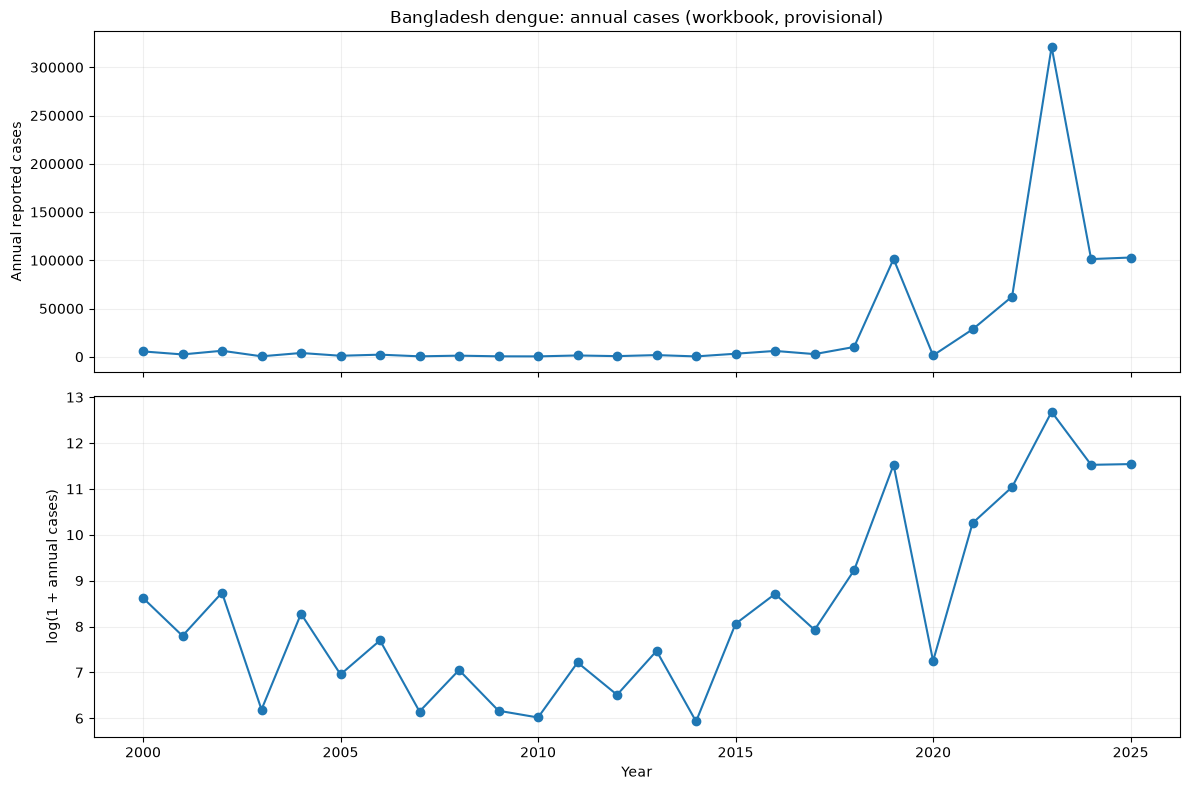

,Year,Cases,Deaths
23,2023,321179,1703
25,2025,102861,413
19,2019,101354,166
24,2024,101214,575
22,2022,62382,281
21,2021,28429,105
18,2018,10148,26
2,2002,6232,58


In [20]:
annual = df.groupby("Year", as_index=False).agg(
    Cases=("Cases", "sum"),
    Deaths=("Deaths", "sum")
)

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(annual["Year"], annual["Cases"], marker="o")
axes[0].set_ylabel("Annual reported cases")
axes[0].set_title("Bangladesh dengue: annual cases (workbook, provisional)")
axes[0].grid(alpha=0.2)

axes[1].plot(annual["Year"], np.log1p(annual["Cases"]), marker="o")
axes[1].set_ylabel("log(1 + annual cases)")
axes[1].set_xlabel("Year")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "figure_01_annual_dengue_trend.png", dpi=180, bbox_inches="tight")
plt.show()

display(annual.sort_values("Cases", ascending=False).head(8))

The annual dengue time series reveals substantial changes in reported disease burden between 2000 and 2025.
The most striking finding is the unprecedented outbreak in 2023, with 321,179 reported cases, substantially exceeding previous years.
The data also show a marked increase in reported dengue cases after 2018, although the number declined sharply in 2020. Annual cases remained above 100,000 during 2024 and 2025.
The logarithmic plot helps visualize variation in earlier low-incidence years that is difficult to distinguish on the original scale.
These patterns suggest substantial temporal instability, which is important when evaluating the generalization performance of forecasting models.

#### 3.3: Monthly Seasonality Analysis

We show both **median** and **mean** cases by calendar month. A few severe outbreaks can increase the mean dramatically.

MONTHLY DENGUE SEASONALITY SUMMARY


,Month_Number,Mean_Cases,Median_Cases,Mean_Deaths,Median_Deaths,Month
0,1,127.85,0.0,1.23,0.0,Jan
1,2,40.23,0.0,0.42,0.0,Feb
2,3,35.08,0.5,0.23,0.0,Mar
3,4,61.73,0.0,0.50,0.0,Apr
4,5,159.54,4.5,0.85,0.0,May
5,6,655.15,59.0,2.92,0.0,Jun
6,7,3247.88,385.5,13.77,1.5,Jul
7,8,6441.08,722.5,23.73,1.0,Aug
8,9,6164.88,503.0,27.04,2.0,Sep
9,10,6359.08,437.5,28.23,1.0,Oct



Highest average cases: Aug 6441.08
Highest median cases: Aug 722.5


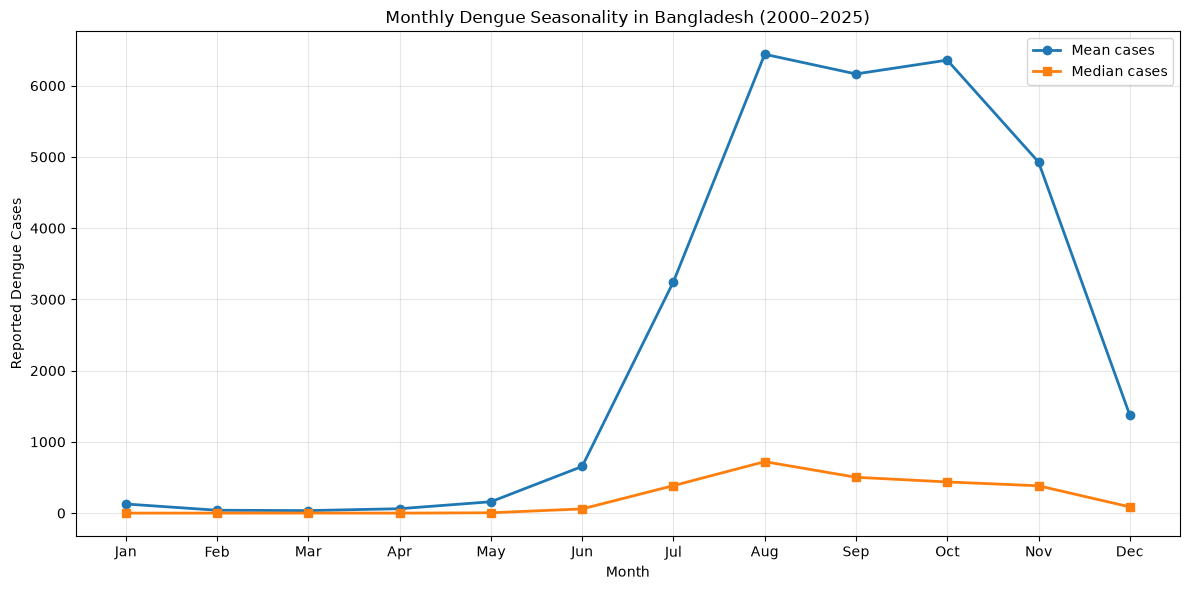

In [21]:

# STEP 3.3: MONTHLY DENGUE SEASONALITY

import pandas as pd
import matplotlib.pyplot as plt

month_names = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

# Monthly summary across 2000–2025
monthly = (
    df.groupby("Month_Number", as_index=False)
    .agg(
        Mean_Cases=("Cases", "mean"),
        Median_Cases=("Cases", "median"),
        Mean_Deaths=("Deaths", "mean"),
        Median_Deaths=("Deaths", "median")
    )
    .sort_values("Month_Number")
)

monthly["Month"] = month_names

print("MONTHLY DENGUE SEASONALITY SUMMARY")
display(monthly.round(2))

# Identify highest month
peak_mean = monthly.loc[
    monthly["Mean_Cases"].idxmax()
]

peak_median = monthly.loc[
    monthly["Median_Cases"].idxmax()
]

print("\nHighest average cases:",
      peak_mean["Month"],
      round(peak_mean["Mean_Cases"], 2))

print("Highest median cases:",
      peak_median["Month"],
      round(peak_median["Median_Cases"], 2))

# Plot monthly seasonality
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    monthly["Month"],
    monthly["Mean_Cases"],
    marker="o",
    linewidth=2,
    label="Mean cases"
)

ax.plot(
    monthly["Month"],
    monthly["Median_Cases"],
    marker="s",
    linewidth=2,
    label="Median cases"
)

ax.set_title(
    "Monthly Dengue Seasonality in Bangladesh (2000–2025)"
)

ax.set_xlabel("Month")
ax.set_ylabel("Reported Dengue Cases")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "figure_02_monthly_seasonality.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


The monthly seasonality analysis reveals a pronounced seasonal pattern in reported dengue incidence in Bangladesh during 2000–2025.
Dengue cases increase substantially from June, reaching their highest average in August (6,441 cases), before remaining elevated through November.
The highest average monthly mortality occurs in October (28.23 deaths), later than the August peak in cases. This difference is descriptive and does not by itself establish a biological delay between infection and death.
The substantial differences between monthly means and medians indicate that major epidemic years strongly influence seasonal averages.
These findings support including seasonal predictors and climate-related variables in subsequent forecasting models.

CLIMATE AND DENGUE MONTHLY SUMMARY


,Month_Number,Mean_Cases,Median_Cases,Mean_Temperature,Mean_Humidity,Mean_Rainfall,Month
0,1,127.85,0.0,17.73,67.68,9.37,Jan
1,2,40.23,0.0,21.66,57.07,20.50,Feb
2,3,35.08,0.5,26.75,54.66,55.12,Mar
3,4,61.73,0.0,29.68,64.85,136.68,Apr
4,5,159.54,4.5,29.57,76.21,316.86,May
5,6,655.15,59.0,28.73,87.53,382.37,Jun
6,7,3247.88,385.5,28.38,89.56,412.85,Jul
7,8,6441.08,722.5,28.18,89.69,381.40,Aug
8,9,6164.88,503.0,27.86,88.74,291.67,Sep
9,10,6359.08,437.5,26.42,84.42,207.38,Oct


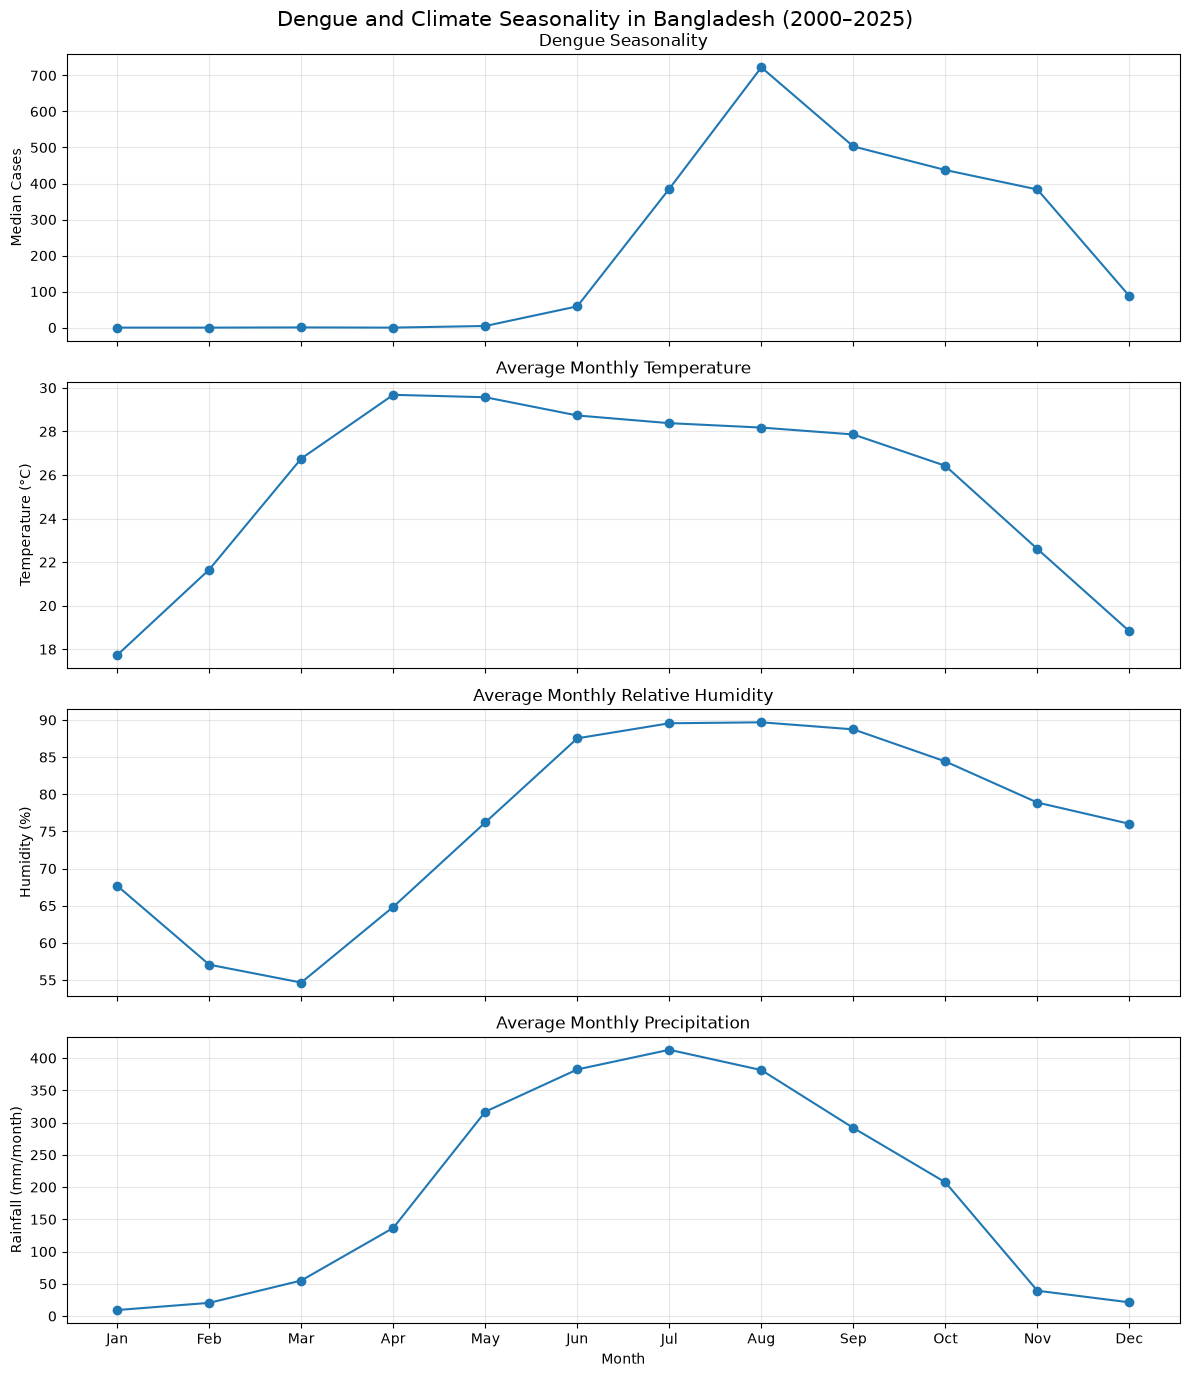

In [22]:

# STEP 3.4: CLIMATE AND DENGUE SEASONALITY

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Monthly averages across 2000-2025
climate_monthly = (
    df.groupby("Month_Number", as_index=False)
    .agg(
        Mean_Cases=("Cases", "mean"),
        Median_Cases=("Cases", "median"),
        Mean_Temperature=("T2M_C", "mean"),
        Mean_Humidity=("RH2M_pct", "mean"),
        Mean_Rainfall=("PRECTOTCORR_SUM_mm_month", "mean")
    )
    .sort_values("Month_Number")
)

month_names = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

climate_monthly["Month"] = month_names

print("CLIMATE AND DENGUE MONTHLY SUMMARY")
display(climate_monthly.round(2))

# Four separate panels
fig, axes = plt.subplots(
    4, 1, figsize=(12, 14), sharex=True
)

# Panel 1: Dengue cases
axes[0].plot(
    climate_monthly["Month"],
    climate_monthly["Median_Cases"],
    marker="o"
)
axes[0].set_ylabel("Median Cases")
axes[0].set_title("Dengue Seasonality")
axes[0].grid(alpha=0.3)

# Panel 2: Temperature
axes[1].plot(
    climate_monthly["Month"],
    climate_monthly["Mean_Temperature"],
    marker="o"
)
axes[1].set_ylabel("Temperature (°C)")
axes[1].set_title("Average Monthly Temperature")
axes[1].grid(alpha=0.3)

# Panel 3: Relative Humidity
axes[2].plot(
    climate_monthly["Month"],
    climate_monthly["Mean_Humidity"],
    marker="o"
)
axes[2].set_ylabel("Humidity (%)")
axes[2].set_title("Average Monthly Relative Humidity")
axes[2].grid(alpha=0.3)

# Panel 4: Rainfall
axes[3].plot(
    climate_monthly["Month"],
    climate_monthly["Mean_Rainfall"],
    marker="o"
)
axes[3].set_ylabel("Rainfall (mm/month)")
axes[3].set_xlabel("Month")
axes[3].set_title("Average Monthly Precipitation")
axes[3].grid(alpha=0.3)

plt.suptitle(
    "Dengue and Climate Seasonality in Bangladesh (2000–2025)",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "figure_03_climate_dengue_seasonality.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


The seasonal analysis reveals distinct temporal patterns between dengue incidence and meteorological conditions in Bangladesh during 2000–2025.
Rainfall reaches its seasonal maximum in July (412.85 mm), while median dengue incidence peaks in August (722.5 cases). Relative humidity also reaches its maximum in August (89.69%).
Temperature peaks earlier, in April (29.68°C), suggesting that the highest dengue incidence does not coincide with the hottest month.
The one-month difference between peak rainfall and peak dengue incidence is consistent with a possible delayed association. However, this descriptive pattern does not establish causality or a statistically significant lag.

Research note: The climate variables represent a central-Bangladesh grid location, not a national spatial average. We will state this limitation in the manuscript.

CLIMATE-DENGUE LAG CORRELATION


,Variable,Lag_Months,Raw_Spearman,Season_Adjusted_Spearman
0,Temperature,0,0.051,-0.061
1,Temperature,1,0.326,0.037
2,Temperature,2,0.528,0.105
3,Temperature,3,0.607,0.141
4,Humidity,0,0.601,0.341
5,Humidity,1,0.634,0.311
6,Humidity,2,0.513,0.269
7,Humidity,3,0.270,0.235
8,Rainfall,0,0.382,0.239
9,Rainfall,1,0.588,0.254


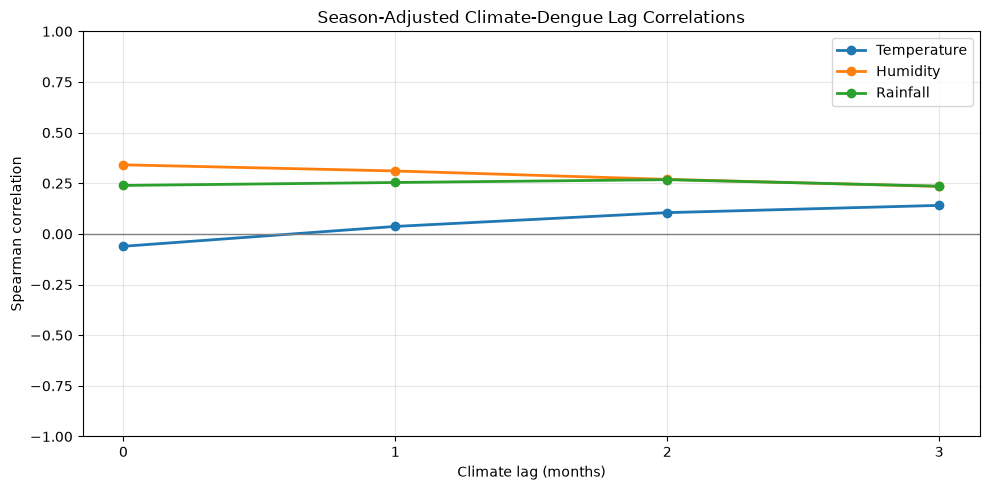

In [23]:

# STEP 3.5: CLIMATE-DENGUE LAG CORRELATION

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

data = df.sort_values("date").copy().reset_index(drop=True)

climate_vars = {
    "T2M_C": "Temperature",
    "RH2M_pct": "Humidity",
    "PRECTOTCORR_SUM_mm_month": "Rainfall"
}

# Log-transform cases and remove monthly seasonality
data["Log_Cases"] = np.log1p(data["Cases"])

data["Case_Anomaly"] = (
    data["Log_Cases"]
    - data.groupby("Month_Number")["Log_Cases"].transform("mean")
)

results = []

for col, name in climate_vars.items():

    # Remove average seasonal pattern from climate
    anomaly = (
        data[col]
        - data.groupby("Month_Number")[col].transform("mean")
    )

    for lag in range(4):

        # Lag 0 = same month
        # Lag 1 = previous month
        # Lag 2 = two months earlier
        # Lag 3 = three months earlier

        raw_lagged = data[col].shift(lag)
        anomaly_lagged = anomaly.shift(lag)

        raw_corr = data["Cases"].corr(
            raw_lagged, method="spearman"
        )

        adjusted_corr = data["Case_Anomaly"].corr(
            anomaly_lagged, method="spearman"
        )

        results.append({
            "Variable": name,
            "Lag_Months": lag,
            "Raw_Spearman": raw_corr,
            "Season_Adjusted_Spearman": adjusted_corr
        })

lag_results = pd.DataFrame(results)

print("CLIMATE-DENGUE LAG CORRELATION")
display(lag_results.round(3))

# Plot season-adjusted correlations
fig, ax = plt.subplots(figsize=(10, 5))

for name in climate_vars.values():

    subset = lag_results[
        lag_results["Variable"] == name
    ]

    ax.plot(
        subset["Lag_Months"],
        subset["Season_Adjusted_Spearman"],
        marker="o",
        linewidth=2,
        label=name
    )

ax.axhline(0, linewidth=1, color="gray")

ax.set_title(
    "Season-Adjusted Climate-Dengue Lag Correlations"
)
ax.set_xlabel("Climate lag (months)")
ax.set_ylabel("Spearman correlation")
ax.set_xticks([0, 1, 2, 3])
ax.set_ylim(-1, 1)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "figure_04_lag_correlations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


The lagged Spearman correlation analysis reveals positive associations between meteorological conditions and monthly dengue incidence after adjustment for calendar-month seasonality.
Relative humidity exhibits the strongest season-adjusted association at lag 0 (ρ = 0.341), suggesting that months with unusually high humidity tend to coincide with higher reported dengue incidence.
Rainfall shows its strongest season-adjusted association at a two-month lag (ρ = 0.268), indicating a possible delayed relationship between precipitation and dengue incidence.
Temperature has a relatively weak season-adjusted association at a three-month lag (ρ = 0.141), despite its much stronger unadjusted correlation (ρ = 0.607).
The substantial reduction in correlation coefficients after seasonal adjustment indicates that shared seasonal patterns explain an important part of the raw associations. These results are descriptive; statistical significance and causality cannot be established from these correlations alone.

Research conclusion
এই analysis থেকে তিনটি গুরুত্বপূর্ণ বিষয় পেয়েছি:
- Humidity-এর association সবচেয়ে বেশি।
- Rainfall-এর সঙ্গে সম্ভাব্য delayed association রয়েছে।
- Seasonality adjust করলে climate–dengue correlations অনেক কমে যায়।

#### 3.6 Monthly time series

The log-scale view makes low-case months visible next to years with extremely large outbreaks.

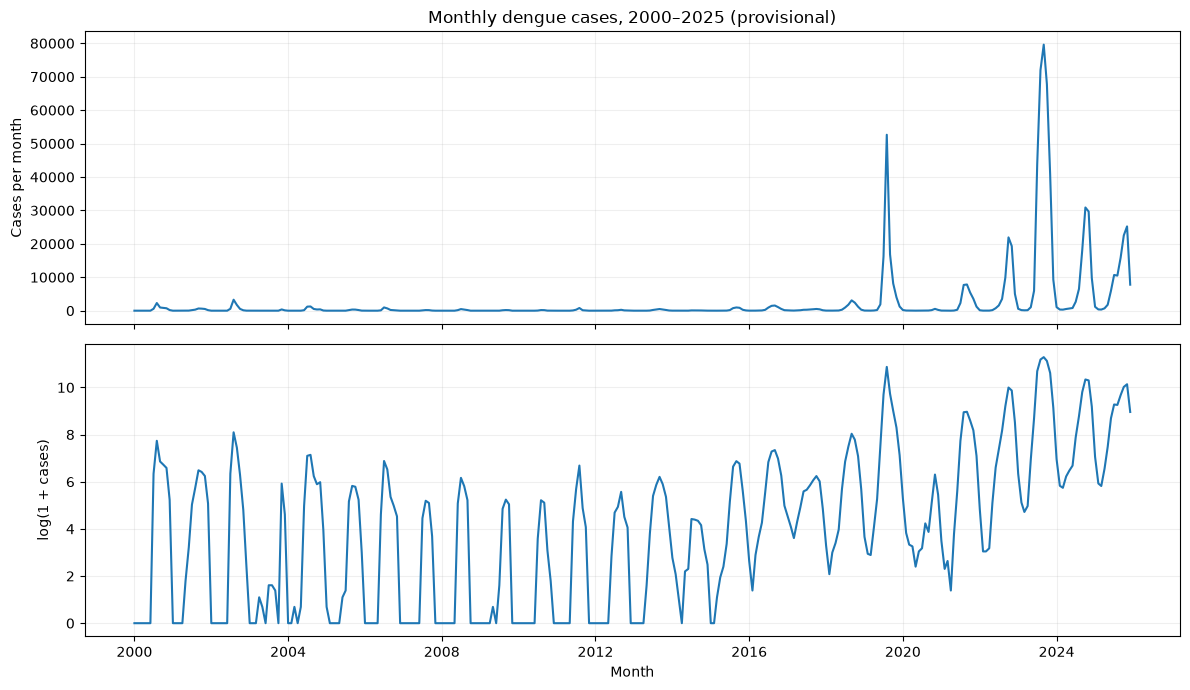

In [24]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(df["date"], df["Cases"])
axes[0].set_ylabel("Cases per month")
axes[0].set_title("Monthly dengue cases, 2000–2025 (provisional)")
axes[0].grid(alpha=0.2)
axes[1].plot(df["date"], np.log1p(df["Cases"]))
axes[1].set_ylabel("log(1 + cases)")
axes[1].set_xlabel("Month")
axes[1].grid(alpha=0.2)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "figure_03_monthly_cases.png", dpi=180, bbox_inches="tight")
plt.show()

The monthly dengue time series from 2000 to 2025 reveals substantial temporal variation in reported dengue incidence in Bangladesh.
The most prominent findings are:
- 2000–2018: Relatively low reported incidence, with occasional seasonal outbreaks.
- 2019: A major epidemic produced a pronounced increase in monthly cases.
- 2023: The largest observed monthly outbreak occurred, reaching 79,598 cases.
- 2024–2025: Recurrent substantial outbreaks indicate that elevated dengue incidence persisted beyond 2023.
The logarithmic transformation, log(1 + cases), makes earlier low-incidence periods and recurring seasonal patterns more visible.
The dramatic variation in outbreak magnitude suggests that forecasting models may struggle to generalize across different epidemic periods. This is particularly relevant when evaluating Machine Learning and Bayesian models.

## 4. Choose climate variables for PCA

The source contains **both** average daily precipitation (`mm/day`) and monthly precipitation totals (`mm/month`), which largely encode the same rain information. Include **only the monthly total** in PCA to avoid double-counting rainfall. Here we use nine distinct parameter columns; some still correlate, which is precisely what PCA investigates.

PCA EXPLAINED VARIANCE


,Component,Explained_Variance_%,Cumulative_Variance_%
0,PC1,67.892,67.892
1,PC2,17.400,85.292
2,PC3,6.546,91.838
3,PC4,3.611,95.450
4,PC5,3.176,98.626
5,PC6,0.805,99.431
6,PC7,0.362,99.793
7,PC8,0.170,99.963
8,PC9,0.037,100.000


Components needed for 90% variance: 3


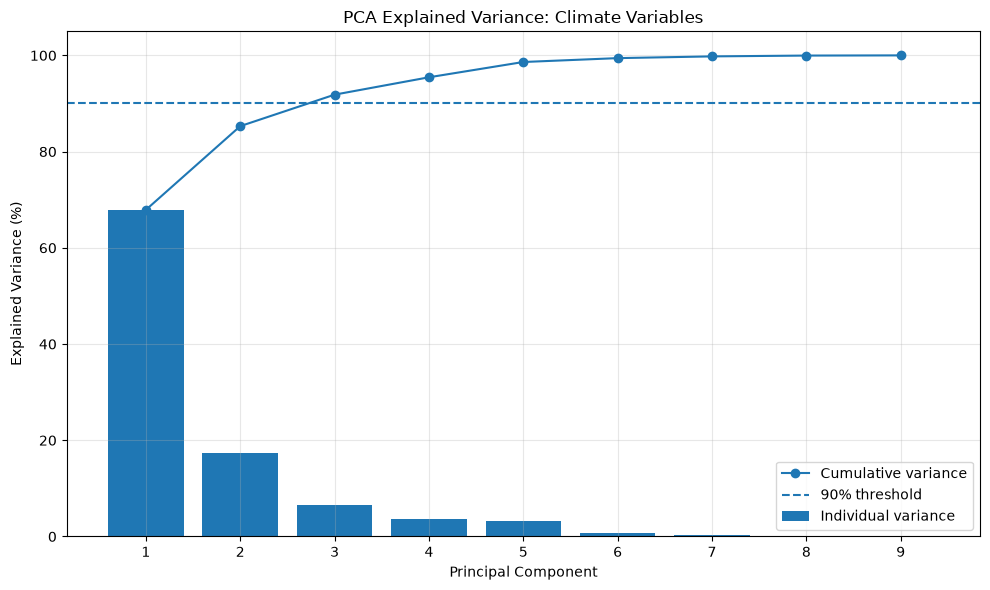

In [25]:

# STEP 4.1: PRINCIPAL COMPONENT ANALYSIS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Select 9 climate variables
climate_features = [
    "T2M_C",
    "T2M_MIN_C",
    "T2M_MAX_C",
    "RH2M_pct",
    "PRECTOTCORR_SUM_mm_month",
    "PS_kPa",
    "WS50M_MAX_m_s",
    "QV2M_g_kg",
    "WS2M_m_s"
]

# Sort observations
data = df.sort_values("date").copy()

# Training period: 2000-2022
# Evaluation period: 2023-2025
train = data[data["date"] < "2023-01-01"].copy()

X_train = train[climate_features]

# Check missing values
assert X_train.notna().all().all(), "Missing values detected"

# Standardize training data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)

# Fit PCA
pca = PCA()
pca.fit(X_scaled)

# Explained variance
explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)

pca_summary = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(explained))],
    "Explained_Variance_%": explained * 100,
    "Cumulative_Variance_%": cumulative * 100
})

print("PCA EXPLAINED VARIANCE")
display(pca_summary.round(3))

# Components needed for 90% variance
n_components = np.searchsorted(cumulative, 0.90) + 1

print("Components needed for 90% variance:", n_components)

# Visualize explained variance
fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    range(1, 10),
    explained * 100,
    label="Individual variance"
)

ax.plot(
    range(1, 10),
    cumulative * 100,
    marker="o",
    label="Cumulative variance"
)

ax.axhline(
    90,
    linestyle="--",
    label="90% threshold"
)

ax.set_title("PCA Explained Variance: Climate Variables")
ax.set_xlabel("Principal Component")
ax.set_ylabel("Explained Variance (%)")
ax.set_xticks(range(1, 10))
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "figure_04_pca_variance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


Principal Component Analysis (PCA) was applied to nine standardized meteorological variables to reduce dimensionality and identify dominant patterns of climate variability.
The first principal component (PC1) explained 67.892% of total climate variance, followed by PC2 (17.400%) and PC3 (6.546%). Together, the first three components explained 91.838% of the variance.
These findings indicate that three principal components can represent most of the variability in the nine meteorological variables, substantially reducing feature dimensionality.
Importantly, explaining 91.838% of climate variance does not mean that PCA explains 91.838% of dengue incidence.

#### 4.2: PCA Loadings Analysis

===== PCA LOADINGS =====


,PC1,PC2,PC3
T2M_C,0.896,0.340,-0.246
T2M_MIN_C,0.970,-0.005,-0.200
T2M_MAX_C,0.555,0.802,-0.154
RH2M_pct,0.598,-0.773,-0.090
PRECTOTCORR_SUM_mm_month,0.811,-0.315,0.130
PS_kPa,-0.966,0.025,0.040
WS50M_MAX_m_s,0.732,0.157,0.585
QV2M_g_kg,0.944,-0.261,-0.172
WS2M_m_s,0.838,0.153,0.262



===== TOP VARIABLES PER COMPONENT =====

Top 5 variables for PC1:


,PC1
T2M_MIN_C,0.970
PS_kPa,-0.966
QV2M_g_kg,0.944
T2M_C,0.896
WS2M_m_s,0.838



Top 5 variables for PC2:


,PC2
T2M_MAX_C,0.802
RH2M_pct,-0.773
T2M_C,0.340
PRECTOTCORR_SUM_mm_month,-0.315
QV2M_g_kg,-0.261



Top 5 variables for PC3:


,PC3
WS50M_MAX_m_s,0.585
WS2M_m_s,0.262
T2M_C,-0.246
T2M_MIN_C,-0.200
QV2M_g_kg,-0.172


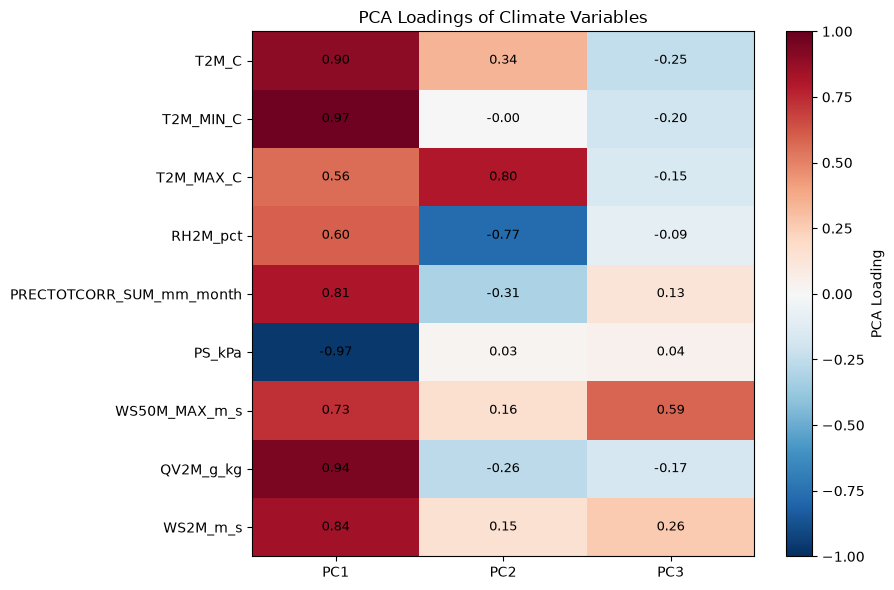

PCA Loadings Analysis Completed!


In [26]:

# STEP 4.2: PCA LOADINGS ANALYSIS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Calculate PCA loadings
# Correlations between standardized original variables
# and principal components

loadings = pd.DataFrame(
    pca.components_[:3].T *
    np.sqrt(pca.explained_variance_[:3]),
    index=climate_features,
    columns=["PC1", "PC2", "PC3"]
)

print("===== PCA LOADINGS =====")
display(loadings.round(3))

# Find strongest variables for each component
print("\n===== TOP VARIABLES PER COMPONENT =====")

for pc in ["PC1", "PC2", "PC3"]:

    top_variables = (
        loadings[pc]
        .abs()
        .sort_values(ascending=False)
        .head(5)
    )

    print(f"\nTop 5 variables for {pc}:")
    display(
        loadings.loc[
            top_variables.index, [pc]
        ].round(3)
    )

# Create heatmap
fig, ax = plt.subplots(figsize=(9, 6))

im = ax.imshow(
    loadings.values,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    aspect="auto"
)

ax.set_xticks(range(3))
ax.set_xticklabels(loadings.columns)

ax.set_yticks(range(len(climate_features)))
ax.set_yticklabels(climate_features)

ax.set_title(
    "PCA Loadings of Climate Variables"
)

# Display loading values
for i in range(len(climate_features)):
    for j in range(3):
        ax.text(
            j, i,
            f"{loadings.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=9
        )

fig.colorbar(
    im,
    ax=ax,
    label="PCA Loading"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "figure_05_pca_loadings.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save loadings
loadings.to_csv(
    OUTPUT_DIR / "pca_loadings.csv"
)

print("PCA Loadings Analysis Completed!")


The PCA loading structure reveals three distinct patterns of climate variability.
PC1 represents a broad meteorological pattern characterized by higher temperatures, greater atmospheric moisture, increased precipitation, and lower surface pressure.
PC2 primarily contrasts maximum temperature with relative humidity, distinguishing hotter conditions from more humid conditions.
PC3 is predominantly associated with wind variability, particularly maximum wind speed.
Together, these three components account for 91.838% of the total variance across the nine climate variables, supporting their use as a reduced-dimensionality representation in subsequent forecasting models.
However, PCA identifies climate variability patterns rather than direct determinants of dengue transmission.

2. Research finding
Component	Main interpretation	Variance
PC1	Warm, humid, rainy and low-pressure conditions	67.89%
PC2	Maximum temperature versus relative humidity	17.40%
PC3	Mainly wind-speed variation	6.55%
Combined	First three components	91.84%

===== PCA SCORES =====


/var/folders/f5/1cr997s92hq6g4lfsh2pz_3c0000gn/T/ipykernel_58954/2750716592.py:41: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(10).round(3)


,date,Cases,PC1,PC2,PC3,Period
0,2000-01-01,0,-3.712,-0.261,0.617,Training
1,2000-02-01,0,-3.223,0.669,0.643,Training
2,2000-03-01,0,-1.010,1.856,0.490,Training
3,2000-04-01,0,1.762,2.018,0.182,Training
4,2000-05-01,0,2.128,0.307,-0.357,Training
5,2000-06-01,0,2.589,-0.461,0.193,Training
6,2000-07-01,565,2.626,-0.449,0.137,Training
7,2000-08-01,2290,2.766,-0.821,0.458,Training
8,2000-09-01,951,1.253,-0.761,-0.201,Training
9,2000-10-01,835,0.043,-0.655,-0.941,Training



===== DATA SPLIT =====
Period
Training    276
Test         36
Name: count, dtype: int64


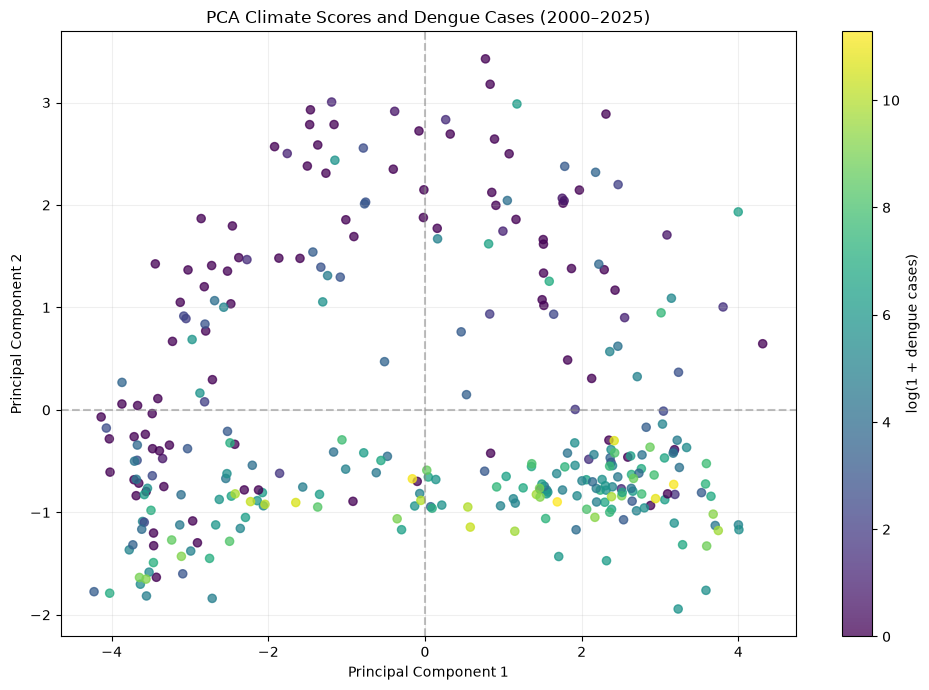


PCA Scores Analysis Completed!


In [27]:

# STEP 4.3: PCA SCORES ANALYSIS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Sort the dataset
pca_data = df.sort_values("date").reset_index(drop=True).copy()

# Use the scaler and PCA already fitted on 2000-2022
X_all = pca_data[climate_features]

assert X_all.notna().all().all(), "Missing climate data found"

X_all_scaled = scaler.transform(X_all)

# Calculate PCA scores
scores = pca.transform(X_all_scaled)

# Retain first 3 components
for i in range(3):
    pca_data[f"PC{i+1}"] = scores[:, i]

# Identify training and test periods
pca_data["Period"] = np.where(
    pca_data["date"] < "2023-01-01",
    "Training",
    "Test"
)

# Display PCA scores
print("===== PCA SCORES =====")

display(
    pca_data[
        ["date", "Cases", "PC1", "PC2", "PC3", "Period"]
    ].head(10).round(3)
)

print("\n===== DATA SPLIT =====")
print(pca_data["Period"].value_counts())

# PCA scores scatter plot
fig, ax = plt.subplots(figsize=(10, 7))

scatter = ax.scatter(
    pca_data["PC1"],
    pca_data["PC2"],
    c=np.log1p(pca_data["Cases"]),
    cmap="viridis",
    alpha=0.75,
    s=35
)

ax.axhline(0, color="gray", linestyle="--", alpha=0.5)
ax.axvline(0, color="gray", linestyle="--", alpha=0.5)

ax.set_title(
    "PCA Climate Scores and Dengue Cases (2000–2025)"
)
ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")

fig.colorbar(
    scatter,
    ax=ax,
    label="log(1 + dengue cases)"
)

ax.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "figure_06_pca_scores.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save PCA scores
pca_data[
    ["date", "Cases", "Deaths", "PC1", "PC2", "PC3", "Period"]
].to_csv(
    OUTPUT_DIR / "pca_scores_2000_2025.csv",
    index=False
)

print("\nPCA Scores Analysis Completed!")


The PCA score plot illustrates the distribution of monthly climate conditions across the first two principal components.
Higher dengue incidence appears more frequently in regions with negative PC2 scores, suggesting a possible association with relatively humid meteorological conditions. However, the substantial overlap between low- and high-incidence observations indicates that climate components alone do not clearly distinguish dengue outbreak intensity.

#### 5.1: Baseline Forecasting Models

===== BASELINE FORECAST RESULTS =====


,Model,MAE,RMSE,Log_MAE
0,Previous_Month,7430.444,12328.422,0.849
1,Seasonal_Naive,14381.806,26570.015,1.170


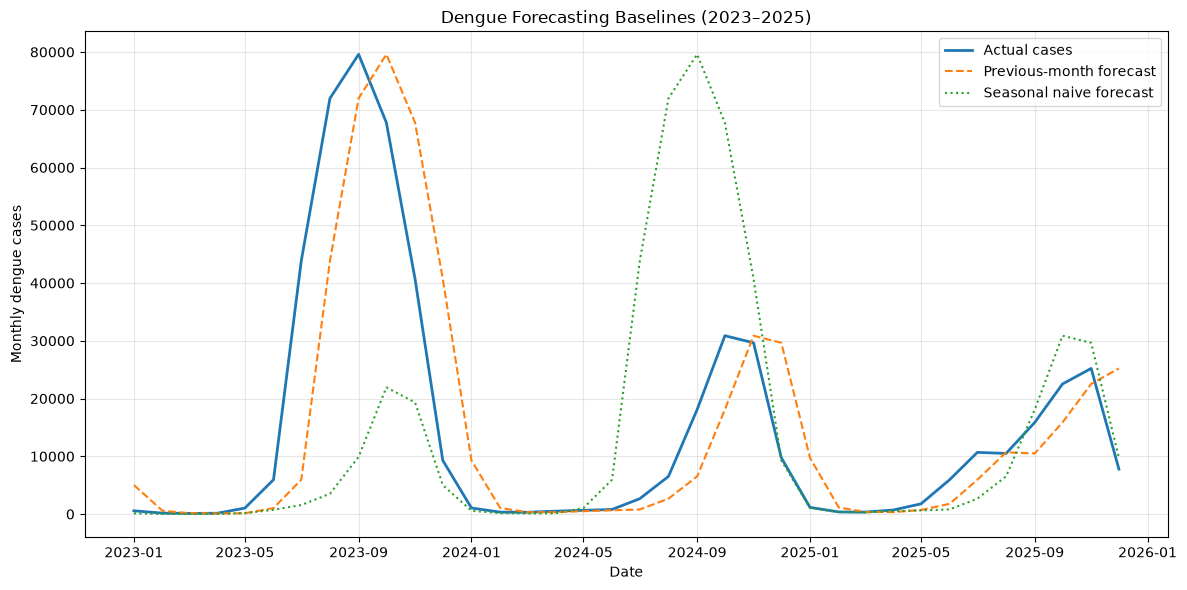

Baseline forecasting completed!


In [28]:

# STEP 5.1: BASELINE FORECASTING

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Sort monthly observations
forecast_data = (
    df.sort_values("date")
    .reset_index(drop=True)
    .copy()
)

# Create baseline predictions
forecast_data["Previous_Month"] = (
    forecast_data["Cases"].shift(1)
)

forecast_data["Seasonal_Naive"] = (
    forecast_data["Cases"].shift(12)
)

# Final test period
test = forecast_data[
    forecast_data["date"] >= "2023-01-01"
].copy()

results = []

for model in ["Previous_Month", "Seasonal_Naive"]:

    y_true = test["Cases"]
    y_pred = test[model]

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    log_mae = mean_absolute_error(
        np.log1p(y_true),
        np.log1p(y_pred)
    )

    results.append({
        "Model": model,
        "MAE": mae,
        "RMSE": rmse,
        "Log_MAE": log_mae
    })

baseline_results = pd.DataFrame(results)

print("===== BASELINE FORECAST RESULTS =====")
display(baseline_results.round(3))

# Plot actual and predicted cases
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    test["date"],
    test["Cases"],
    label="Actual cases",
    linewidth=2
)

ax.plot(
    test["date"],
    test["Previous_Month"],
    label="Previous-month forecast",
    linestyle="--"
)

ax.plot(
    test["date"],
    test["Seasonal_Naive"],
    label="Seasonal naive forecast",
    linestyle=":"
)

ax.set_title(
    "Dengue Forecasting Baselines (2023–2025)"
)

ax.set_xlabel("Date")
ax.set_ylabel("Monthly dengue cases")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "figure_07_baseline_forecasting.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save results
baseline_results.to_csv(
    OUTPUT_DIR / "baseline_results.csv",
    index=False
)

print("Baseline forecasting completed!")


The previous-month naïve model substantially outperformed the seasonal naïve model during the 2023–2025 evaluation period.
The previous-month approach achieved an MAE of 7,430.44 cases, compared with 14,381.81 cases for the seasonal naïve approach.
The plot also reveals an important limitation: the previous-month forecast follows sudden outbreaks with a one-month delay, while the seasonal naïve forecast incorrectly anticipates a similarly large outbreak in 2024 based on the exceptional 2023 epidemic.
These findings suggest that outbreak magnitude varies considerably between years and that previous-year dengue incidence alone is an unreliable forecasting reference.

Research implication: Machine Learning models must be compared against the previous-month baseline. A more complicated model is not necessarily a better forecasting model.

#### 5.2 Random Forest — With and Without PCA

In [29]:

# STEP 5.2: RANDOM FOREST WITH AND WITHOUT PCA

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Prepare time-ordered data
ml_data = df.sort_values("date").copy().reset_index(drop=True)

# 2. Previous dengue observations
ml_data["Cases_lag1"] = ml_data["Cases"].shift(1)
ml_data["Cases_lag12"] = ml_data["Cases"].shift(12)

# 3. Previous-month climate variables
climate_lag_cols = []

for col in climate_features:
    new_col = col + "_lag1"
    ml_data[new_col] = ml_data[col].shift(1)
    climate_lag_cols.append(new_col)

# 4. Seasonal predictors
ml_data["month_sin"] = np.sin(
    2 * np.pi * ml_data["Month_Number"] / 12
)

ml_data["month_cos"] = np.cos(
    2 * np.pi * ml_data["Month_Number"] / 12
)

other_features = [
    "Cases_lag1",
    "Cases_lag12",
    "month_sin",
    "month_cos"
]

feature_cols = climate_lag_cols + other_features

ml_data = ml_data.dropna(
    subset=feature_cols + ["Cases"]
).reset_index(drop=True)

# 5. Chronological split
train = ml_data[
    ml_data["date"] < "2020-01-01"
].copy()

val = ml_data[
    (ml_data["date"] >= "2020-01-01") &
    (ml_data["date"] < "2023-01-01")
].copy()

test = ml_data[
    ml_data["date"] >= "2023-01-01"
].copy()

print("Training observations:", len(train))
print("Validation observations:", len(val))
print("Test observations:", len(test))

X_train = train[feature_cols]
y_train = train["Cases"]

X_val = val[feature_cols]
y_val = val["Cases"]

# 6. Random Forest without PCA
rf_original = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_original.fit(X_train, y_train)

pred_original = rf_original.predict(X_val)

# 7. Random Forest with PCA
preprocessor = ColumnTransformer(
    transformers=[
        (
            "climate_pca",
            Pipeline([
                ("scaler", StandardScaler()),
                ("pca", PCA(n_components=3))
            ]),
            climate_lag_cols
        ),
        (
            "other_features",
            "passthrough",
            other_features
        )
    ]
)

rf_pca = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

rf_pca.fit(X_train, y_train)

pred_pca = rf_pca.predict(X_val)

# 8. Evaluation function
def evaluate_model(name, actual, predicted):
    predicted = np.maximum(np.asarray(predicted), 0)

    return {
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "Log_MAE": mean_absolute_error(
            np.log1p(actual),
            np.log1p(predicted)
        )
    }

# 9. Compare validation results
comparison = pd.DataFrame([
    evaluate_model(
        "Previous Month",
        y_val,
        val["Cases_lag1"]
    ),
    evaluate_model(
        "Random Forest",
        y_val,
        pred_original
    ),
    evaluate_model(
        "Random Forest + PCA",
        y_val,
        pred_pca
    )
])

print("\n===== VALIDATION RESULTS (2020-2022) =====")
display(comparison.round(3))

print("\nRandom Forest validation completed!")


Training observations: 228
Validation observations: 36
Test observations: 36

===== VALIDATION RESULTS (2020-2022) =====


,Model,MAE,RMSE,Log_MAE
0,Previous Month,1579.028,3545.568,1.025
1,Random Forest,1369.637,3286.828,1.019
2,Random Forest + PCA,1500.118,3359.764,1.155



Random Forest validation completed!


Random Forest achieved the best validation performance among the three evaluated models, with an MAE of 1,369.64 cases and RMSE of 3,286.83 cases.
Compared with the previous-month baseline, Random Forest reduced MAE by approximately 13.3%.
Adding PCA did not improve Random Forest performance. Although Random Forest + PCA outperformed the naïve baseline on MAE and RMSE, it performed worse than standard Random Forest across all three metrics.
These results indicate that retaining the original climate features was more effective than replacing them with principal components for this validation period.

Important: Validation performance does not guarantee superior forecasting on the 2023–2025 test period.

#### 5.2.1: Random Forest Model Comparison Graph

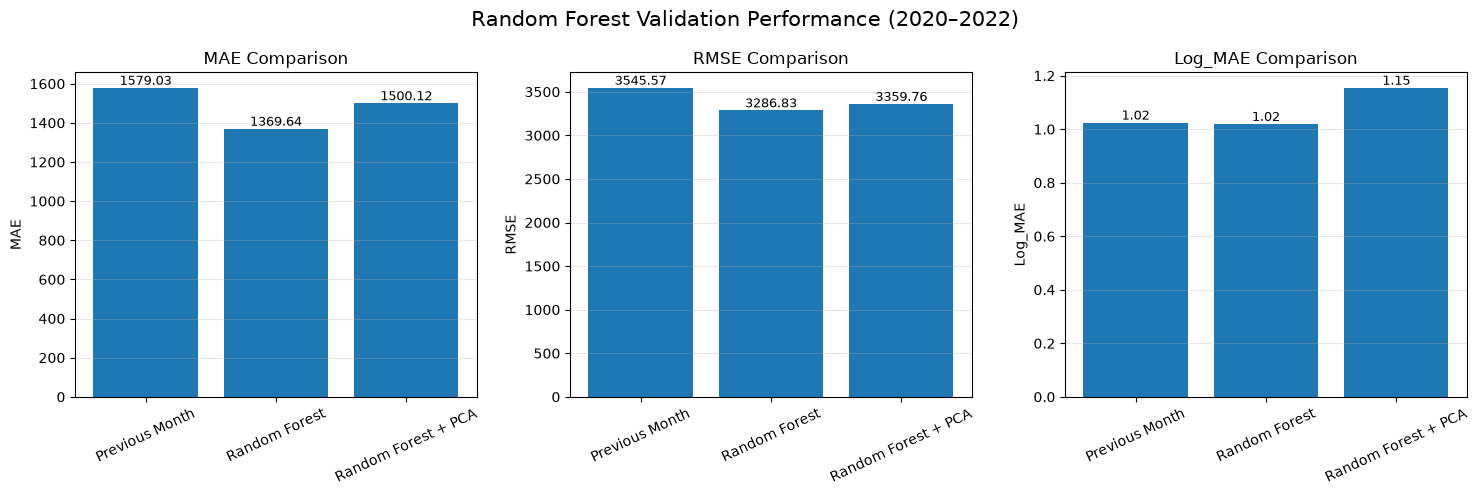

In [30]:

# STEP 5.2.1: RANDOM FOREST MODEL COMPARISON

import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

metrics = ["MAE", "RMSE", "Log_MAE"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, metric in zip(axes, metrics):

    bars = ax.bar(
        comparison["Model"],
        comparison[metric]
    )

    ax.set_title(f"{metric} Comparison")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.3)

    for bar in bars:
        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f"{height:.2f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

fig.suptitle(
    "Random Forest Validation Performance (2020–2022)",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "figure_08_RF_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Random Forest achieved the lowest validation errors among the three models, reducing MAE by approximately 13.3% relative to the previous-month baseline.
Adding PCA increased MAE from 1,369.64 to 1,500.12, indicating that PCA-based dimensionality reduction did not improve forecasting accuracy in this experiment.
The small difference in Log MAE between Random Forest and the previous-month baseline also suggests that their performance is similar when errors are evaluated on a logarithmic scale.
These findings are limited to the 2020–2022 validation period and should not be interpreted as evidence of superior performance during the 2023–2025 outbreaks.

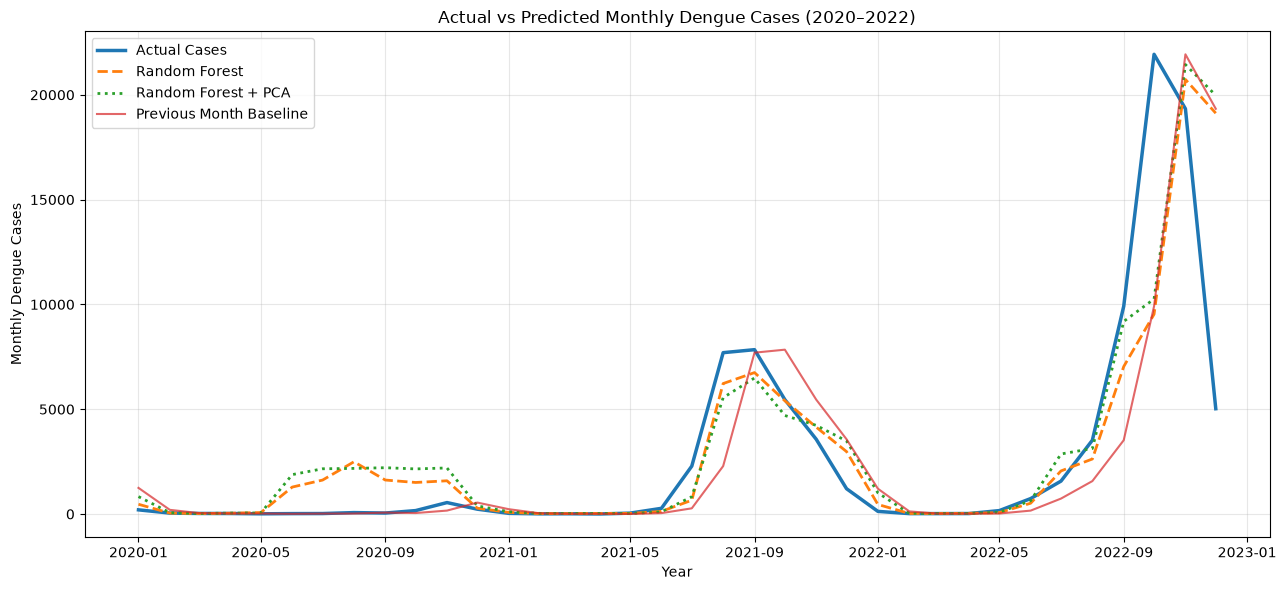

In [31]:

# STEP 10.2.2: ACTUAL VS PREDICTED CASES

import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(13, 6))

# Actual dengue cases
ax.plot(
    val["date"],
    y_val,
    label="Actual Cases",
    linewidth=2.5
)

# Random Forest without PCA
ax.plot(
    val["date"],
    pred_original,
    label="Random Forest",
    linestyle="--",
    linewidth=2
)

# Random Forest with PCA
ax.plot(
    val["date"],
    pred_pca,
    label="Random Forest + PCA",
    linestyle=":",
    linewidth=2
)

# Previous-month baseline
ax.plot(
    val["date"],
    val["Cases_lag1"],
    label="Previous Month Baseline",
    alpha=0.7
)

ax.set_title(
    "Actual vs Predicted Monthly Dengue Cases (2020–2022)"
)

ax.set_xlabel("Year")
ax.set_ylabel("Monthly Dengue Cases")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "figure_09_RF_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


The validation plot demonstrates that Random Forest captures several broad outbreak patterns during 2020–2022, but important forecasting errors remain.
- 2020: Both Random Forest models overpredict dengue incidence during several low-incidence months.
- 2021: Random Forest broadly follows the seasonal outbreak, although predictions differ from observed peak values.
- 2022: The models underestimate the rapid increase in October and predict elevated incidence in November, illustrating difficulties in forecasting abrupt epidemic changes.

Overall, Random Forest achieves better aggregate validation accuracy than the previous-month baseline, but it does not consistently predict the timing and magnitude of sudden outbreaks.

#### 3: XGBoost with and without PCA

In [52]:
%pip install xgboost

  Using cached xgboost-3.4.1-py3-none-macosx_12_0_arm64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-macosx_12_0_arm64.whl (2.4 MB)
Note: you may need to restart the kernel to use updated packages.


In [32]:

# STEP 5.3: XGBOOST WITH AND WITHOUT PCA

import numpy as np
import pandas as pd

from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# 1. XGBoost without PCA

xgb_original = XGBRegressor(
    n_estimators=300,
    max_depth=2,
    learning_rate=0.03,
    subsample=0.9,
    colsample_bytree=0.9,
    min_child_weight=3,
    reg_lambda=5,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42,
    n_jobs=4
)

xgb_original.fit(X_train, y_train)

pred_xgb = np.maximum(
    xgb_original.predict(X_val), 0
)

# 2. XGBoost with PCA

xgb_pca = Pipeline([
    (
        "preprocessing",
        clone(preprocessor)
    ),
    (
        "model",
        XGBRegressor(
            n_estimators=300,
            max_depth=2,
            learning_rate=0.03,
            subsample=0.9,
            colsample_bytree=0.9,
            min_child_weight=3,
            reg_lambda=5,
            objective="reg:squarederror",
            tree_method="hist",
            random_state=42,
            n_jobs=4
        )
    )
])

xgb_pca.fit(X_train, y_train)

pred_xgb_pca = np.maximum(
    xgb_pca.predict(X_val), 0
)

# 3. Compare all models

all_results = pd.DataFrame([
    evaluate_model(
        "Previous Month",
        y_val,
        val["Cases_lag1"]
    ),
    evaluate_model(
        "Random Forest",
        y_val,
        pred_original
    ),
    evaluate_model(
        "Random Forest + PCA",
        y_val,
        pred_pca
    ),
    evaluate_model(
        "XGBoost",
        y_val,
        pred_xgb
    ),
    evaluate_model(
        "XGBoost + PCA",
        y_val,
        pred_xgb_pca
    )
])

# 4. Sort by MAE

all_results = (
    all_results
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("===== ML VALIDATION COMPARISON =====")

display(all_results.round(3))

# 5. Save results

from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

all_results.to_csv(
    OUTPUT_DIR / "ml_validation_comparison.csv",
    index=False
)

print("\nXGBoost comparison completed!")


===== ML VALIDATION COMPARISON =====


,Model,MAE,RMSE,Log_MAE
0,Random Forest,1369.637,3286.828,1.019
1,Random Forest + PCA,1500.118,3359.764,1.155
2,XGBoost + PCA,1540.315,3796.129,1.814
3,Previous Month,1579.028,3545.568,1.025
4,XGBoost,1793.459,3847.399,1.789



XGBoost comparison completed!


Random Forest achieved the best overall validation performance, with an MAE of 1,369.64 cases and an RMSE of 3,286.83 cases.

Compared with the previous-month baseline, Random Forest reduced MAE by approximately 13.3%.

Adding PCA to Random Forest increased forecasting error, suggesting that dimensionality reduction did not improve its predictive performance.

For XGBoost, PCA reduced MAE from 1,793.46 to 1,540.32, but its logarithmic error increased slightly. Thus, the effect of PCA differs across algorithms and evaluation metrics.

These findings establish Random Forest as the leading candidate based on validation performance, but its effectiveness during major outbreaks must be assessed separately.

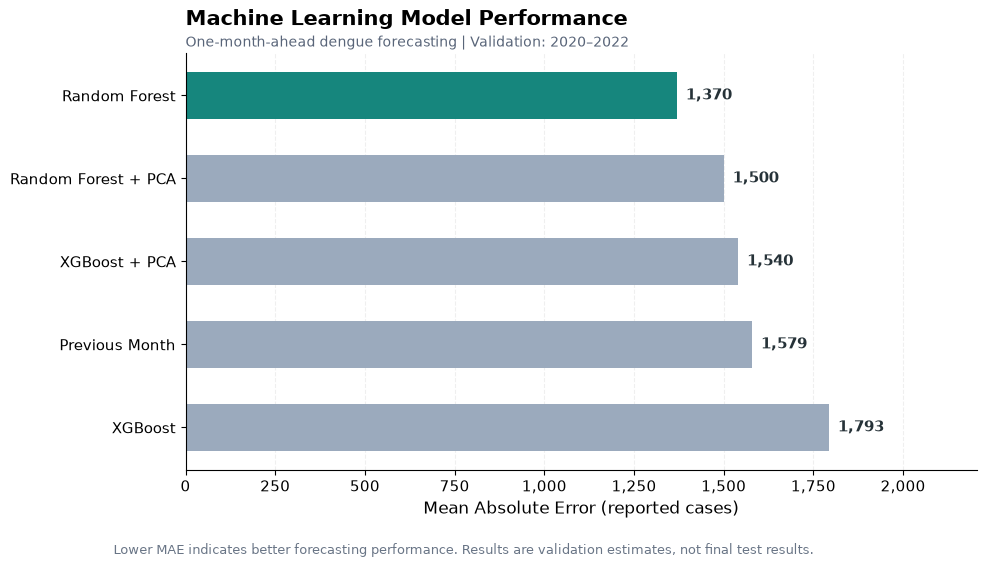

In [35]:

# FIGURE 5.4: PUBLICATION-QUALITY MODEL COMPARISON

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Consistent research figure style
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.labelsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "savefig.dpi": 300
})

plot_df = (
    all_results
    .sort_values("MAE", ascending=True)
    .reset_index(drop=True)
)

best_model = plot_df.iloc[0]["Model"]

colors = [
    "#16867D" if model == best_model else "#9BAABD"
    for model in plot_df["Model"]
]

fig, ax = plt.subplots(figsize=(10, 5.7))

bars = ax.barh(
    plot_df["Model"],
    plot_df["MAE"],
    color=colors,
    height=0.57,
    edgecolor="none"
)

ax.invert_yaxis()

# Show exact values
for bar, value in zip(bars, plot_df["MAE"]):
    ax.text(
        value + 25,
        bar.get_y() + bar.get_height() / 2,
        f"{value:,.0f}",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="#263238"
    )

ax.set_title(
    "Machine Learning Model Performance",
    loc="left",
    fontweight="bold",
    pad=20
)

ax.text(
    0, 1.015,
    "One-month-ahead dengue forecasting | Validation: 2020–2022",
    transform=ax.transAxes,
    fontsize=10,
    color="#596579"
)

ax.set_xlabel("Mean Absolute Error (reported cases)")
ax.set_xlim(0, plot_df["MAE"].max() * 1.23)

ax.xaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.20
)

ax.set_axisbelow(True)

fig.text(
    0.12, 0.015,
    "Lower MAE indicates better forecasting performance. "
    "Results are validation estimates, not final test results.",
    fontsize=9,
    color="#697586"
)

plt.tight_layout(rect=[0, 0.05, 1, 1])

fig.savefig(
    OUTPUT_DIR / "Figure_10_ML_Performance.png",
    dpi=400,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "Figure_10_ML_Performance.pdf",
    bbox_inches="tight"
)

plt.show()


Random Forest achieved the lowest validation MAE (1,369.64 cases), outperforming the previous-month baseline (1,579.03 cases) by approximately 13.3%.

Adding PCA did not improve Random Forest performance. XGBoost also performed worse than Random Forest during validation.

These findings identify Random Forest as the best-performing validation model, but its generalization to the 2023–2025 outbreak period remains to be evaluated.

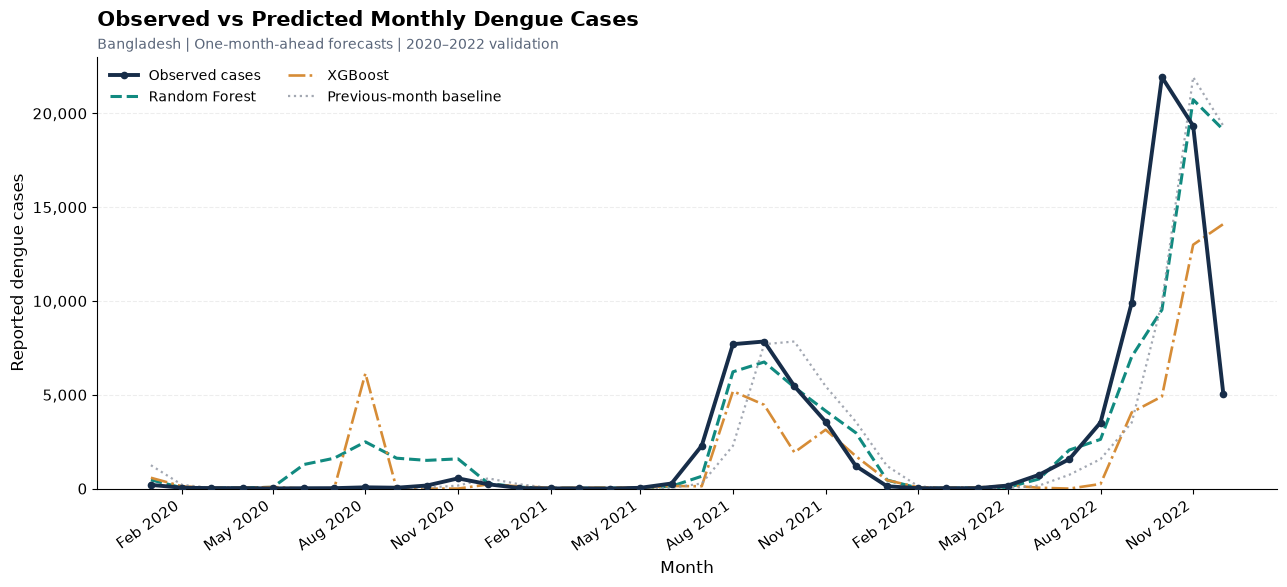

In [36]:

# FIGURE 5.5: PUBLICATION-QUALITY FORECAST COMPARISON

import matplotlib.dates as mdates

dates = pd.to_datetime(val["date"])

actual = np.asarray(y_val)
rf_pred = np.maximum(np.asarray(pred_original), 0)
xgb_pred = np.maximum(np.asarray(pred_xgb), 0)
naive_pred = np.asarray(val["Cases_lag1"])

fig, ax = plt.subplots(figsize=(13, 6))

# Actual observations
ax.plot(
    dates,
    actual,
    color="#172D49",
    linewidth=2.8,
    marker="o",
    markersize=4.5,
    label="Observed cases",
    zorder=5
)

# Random Forest
ax.plot(
    dates,
    rf_pred,
    color="#118A80",
    linewidth=2.2,
    linestyle="--",
    label="Random Forest"
)

# XGBoost
ax.plot(
    dates,
    xgb_pred,
    color="#D68C36",
    linewidth=1.9,
    linestyle="-.",
    label="XGBoost"
)

# Naive baseline
ax.plot(
    dates,
    naive_pred,
    color="#9399A5",
    linewidth=1.6,
    linestyle=":",
    label="Previous-month baseline",
    alpha=0.85
)

ax.set_title(
    "Observed vs Predicted Monthly Dengue Cases",
    loc="left",
    fontweight="bold",
    pad=22
)

ax.text(
    0, 1.018,
    "Bangladesh | One-month-ahead forecasts | 2020–2022 validation",
    transform=ax.transAxes,
    fontsize=10,
    color="#596579"
)

ax.set_xlabel("Month")
ax.set_ylabel("Reported dengue cases")

ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=3)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

ax.yaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

ax.set_ylim(bottom=0)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.22
)

ax.set_axisbelow(True)

ax.legend(
    frameon=False,
    ncol=2,
    loc="upper left",
    fontsize=10
)

plt.xticks(rotation=35, ha="right")

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "Figure_11_Observed_vs_Predicted.png",
    dpi=400,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "Figure_11_Observed_vs_Predicted.pdf",
    bbox_inches="tight"
)

plt.show()


The comparison reveals important differences in forecasting behavior across the models.
- Random Forest: Generally follows the observed epidemic patterns, particularly during 2021–2022, but underestimates the sharp increase in October 2022.
- XGBoost: Produces a substantial false outbreak peak in 2020 and considerably underestimates the 2022 epidemic peak.
- Previous-month baseline: Captures the magnitude of outbreaks after they occur, but its predictions tend to lag behind sudden changes.

These findings are consistent with the validation MAE results: Random Forest (1,369.64), previous-month baseline (1,579.03), and XGBoost (1,793.46).

Research implication: Random Forest performs best during validation, but predicting sudden epidemic peaks remains challenging.

#### 5.6 Year-wise Model Error Analysis

===== YEAR-WISE MODEL PERFORMANCE =====


,Year,Model,MAE,Bias
0,2020,Previous Month,177.50,84.67
1,2020,Random Forest,803.09,802.06
2,2020,Random Forest + PCA,1065.06,1064.69
3,2020,XGBoost,620.30,485.88
4,2020,XGBoost + PCA,233.43,92.09
5,2021,Previous Month,1225.67,-81.33
6,2021,Random Forest,570.54,-163.98
7,2021,Random Forest + PCA,748.95,-235.47
8,2021,XGBoost,1071.80,-950.64
9,2021,XGBoost + PCA,1155.51,-727.43


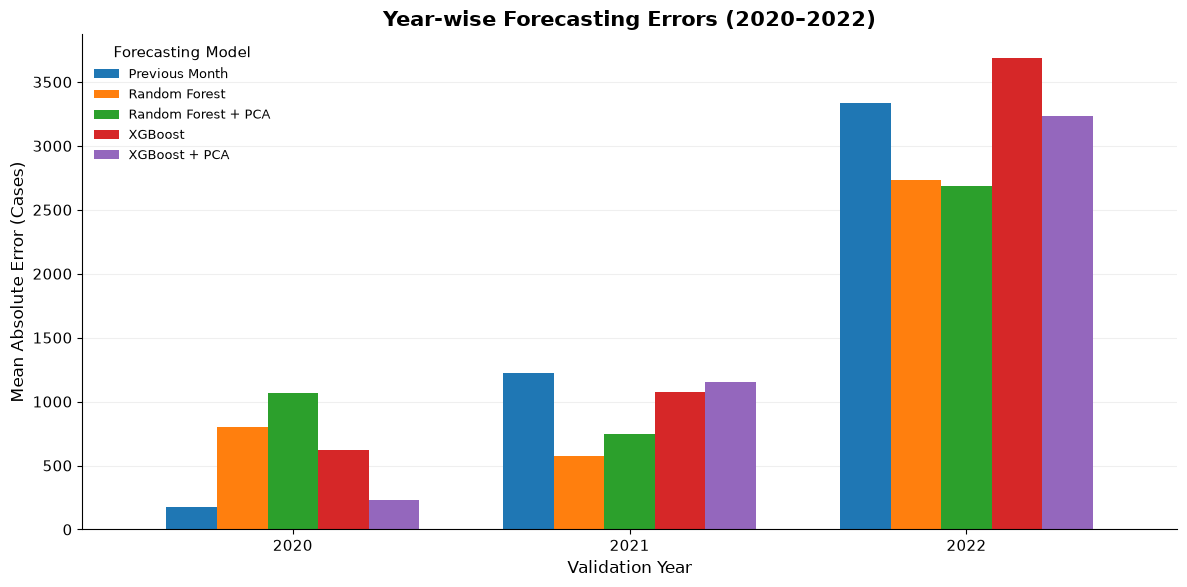

Year-wise error analysis completed!


In [44]:

# STEP 5.6 YEAR-WISE MODEL ERROR ANALYSIS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import mean_absolute_error

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Build validation predictions table
validation_predictions = pd.DataFrame({
    "Date": pd.to_datetime(val["date"]).to_numpy(),
    "Actual": np.asarray(y_val),
    "Previous Month": np.asarray(val["Cases_lag1"]),
    "Random Forest": np.maximum(pred_original, 0),
    "Random Forest + PCA": np.maximum(pred_pca, 0),
    "XGBoost": np.maximum(pred_xgb, 0),
    "XGBoost + PCA": np.maximum(pred_xgb_pca, 0)
})

validation_predictions["Year"] = (
    validation_predictions["Date"].dt.year
)

models = [
    "Previous Month",
    "Random Forest",
    "Random Forest + PCA",
    "XGBoost",
    "XGBoost + PCA"
]

# Calculate annual error metrics
yearly_results = []

for year, group in validation_predictions.groupby("Year"):

    for model in models:

        actual = group["Actual"].to_numpy()
        predicted = group[model].to_numpy()

        yearly_results.append({
            "Year": year,
            "Model": model,
            "MAE": mean_absolute_error(
                actual, predicted
            ),
            "Bias": np.mean(predicted - actual)
        })

yearly_results = pd.DataFrame(yearly_results)

print("===== YEAR-WISE MODEL PERFORMANCE =====")
display(yearly_results.round(2))

# Prepare plotting table
mae_table = yearly_results.pivot(
    index="Year",
    columns="Model",
    values="MAE"
)

# Plot annual MAE
fig, ax = plt.subplots(figsize=(12, 6))

mae_table[models].plot(
    kind="bar",
    ax=ax,
    width=0.75
)

ax.set_title(
    "Year-wise Forecasting Errors (2020–2022)",
    fontweight="bold",
    fontsize=15
)

ax.set_xlabel("Validation Year")
ax.set_ylabel("Mean Absolute Error (Cases)")
ax.tick_params(axis="x", rotation=0)

ax.legend(
    title="Forecasting Model",
    frameon=False,
    fontsize=9
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "Figure_12_Yearwise_Model_Errors.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save results
yearly_results.to_csv(
    OUTPUT_DIR / "yearwise_model_errors.csv",
    index=False
)

print("Year-wise error analysis completed!")


The year-wise evaluation reveals substantial variation in forecasting performance across 2020–2022.
In 2020, the previous-month baseline performed best, while Random Forest systematically overpredicted cases.
In 2021, Random Forest achieved the lowest MAE, indicating improved performance during that year's outbreak.

In 2022, Random Forest + PCA achieved the lowest MAE, although its advantage over standard Random Forest was relatively small.

Forecasting errors increased considerably in 2022, reflecting difficulties in anticipating large and rapidly changing outbreaks.

Overall, no single model performed best in every validation year. Random Forest nevertheless achieved the lowest average validation MAE across the full three-year period.

#### 5.7 Final Test Evaluation (2023–2025)

Training observations: 264
Test observations: 36

===== FINAL TEST RESULTS (2023-2025) =====


,Model,MAE,RMSE,Log_MAE,Bias
0,Previous Month,7430.444,12328.422,0.849,-76.556
1,XGBoost,9354.520,18164.933,0.969,-7128.162
2,Random Forest,9420.196,17578.650,0.799,-5216.016
3,XGBoost + PCA,9827.206,18417.655,1.008,-6554.086
4,Random Forest + PCA,9981.486,18347.468,0.743,-4999.189


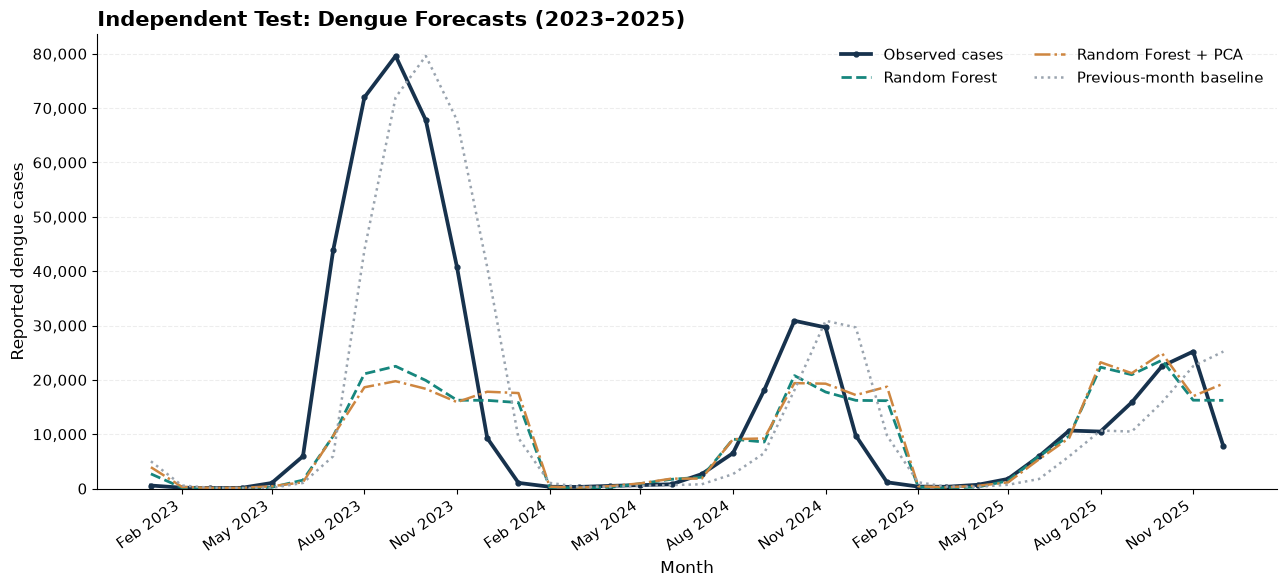


Final test evaluation completed!


In [45]:

# STEP 5.7 FINAL TEST EVALUATION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from pathlib import Path
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error
from matplotlib.ticker import StrMethodFormatter

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# 1. Training + validation and independent test
trainval = ml_data[
    ml_data["date"] < "2023-01-01"
].copy()

final_test = ml_data[
    ml_data["date"] >= "2023-01-01"
].copy()

X_trainval = trainval[feature_cols]
y_trainval = trainval["Cases"]

X_test = final_test[feature_cols]
y_test = final_test["Cases"]

print("Training observations:", len(trainval))
print("Test observations:", len(final_test))

# 2. Clone the previously selected model configurations
final_models = {
    "Random Forest": clone(rf_original),
    "Random Forest + PCA": clone(rf_pca),
    "XGBoost": clone(xgb_original),
    "XGBoost + PCA": clone(xgb_pca)
}

# 3. Previous-month baseline
predictions = {
    "Previous Month": final_test["Cases_lag1"].to_numpy()
}

# 4. Train and predict
for name, model in final_models.items():
    model.fit(X_trainval, y_trainval)

    predictions[name] = np.maximum(
        model.predict(X_test), 0
    )

# 5. Final performance evaluation
test_results = []

for name, pred in predictions.items():

    test_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "Log_MAE": mean_absolute_error(
            np.log1p(y_test),
            np.log1p(pred)
        ),
        "Bias": np.mean(pred - y_test.to_numpy())
    })

test_results = (
    pd.DataFrame(test_results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("\n===== FINAL TEST RESULTS (2023-2025) =====")
display(test_results.round(3))

# 6. Save test results
test_results.to_csv(
    OUTPUT_DIR / "final_test_results.csv",
    index=False
)

# 7. Publication-style forecast plot
fig, ax = plt.subplots(figsize=(13, 6))

dates = final_test["date"]

ax.plot(
    dates, y_test,
    label="Observed cases",
    color="#17324D",
    linewidth=2.7,
    marker="o",
    markersize=3.5
)

ax.plot(
    dates, predictions["Random Forest"],
    label="Random Forest",
    color="#16867D",
    linestyle="--",
    linewidth=2
)

ax.plot(
    dates, predictions["Random Forest + PCA"],
    label="Random Forest + PCA",
    color="#CE8640",
    linestyle="-.",
    linewidth=1.8
)

ax.plot(
    dates, predictions["Previous Month"],
    label="Previous-month baseline",
    color="#9AA4AF",
    linestyle=":",
    linewidth=1.8
)

ax.set_title(
    "Independent Test: Dengue Forecasts (2023–2025)",
    fontweight="bold",
    fontsize=15,
    loc="left"
)

ax.set_xlabel("Month")
ax.set_ylabel("Reported dengue cases")

ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=3)
)
ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)
ax.yaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

ax.set_ylim(bottom=0)
ax.grid(axis="y", linestyle="--", alpha=0.22)
ax.legend(frameon=False, ncol=2)

plt.xticks(rotation=35, ha="right")
plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "Figure_13_Final_Test.png",
    dpi=400,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "Figure_13_Final_Test.pdf",
    bbox_inches="tight"
)

plt.show()

print("\nFinal test evaluation completed!")


The independent chronological test evaluation reveals a substantial deterioration in Machine Learning forecasting performance during 2023–2025.

Despite achieving the lowest validation error, Random Forest did not outperform the previous-month baseline on the final test dataset. Its test MAE increased to 9,420.20 cases, approximately 26.8% higher than the baseline MAE of 7,430.44 cases.

XGBoost produced the lowest MAE among the Machine Learning models (9,354.52), but still performed approximately 25.9% worse than the naïve baseline.

The 2023 epidemic represents a major challenge for the forecasting models. The Random Forest predictions substantially underestimate the outbreak peak, illustrating limited generalization to unusually severe epidemic conditions.

Random Forest + PCA achieved the lowest logarithmic MAE (0.743), showing that model rankings depend on the evaluation metric. Nevertheless, it had the highest absolute count MAE.

The large negative biases of all four Machine Learning models indicate systematic underprediction of dengue cases, assuming bias is calculated as predicted minus observed cases.

Research finding: Model complexity and superior validation performance did not translate into better forecasting accuracy during the subsequent major dengue outbreaks.

===== YEAR-WISE FINAL TEST RESULTS =====


,Year,Model,MAE,Bias
0,2023,Previous Month,12892.50,-355.33
1,2023,Random Forest,19073.42,-17557.67
2,2023,Random Forest + PCA,19917.15,-17904.67
3,2023,XGBoost,19896.68,-19258.51
4,2023,XGBoost + PCA,20204.36,-18888.40
5,2024,Previous Month,5056.58,-38.08
6,2024,Random Forest,4808.25,-636.10
7,2024,Random Forest + PCA,4968.17,-312.64
8,2024,XGBoost,3847.66,-1623.68
9,2024,XGBoost + PCA,4041.06,-1963.07



===== LARGEST MONTHLY OUTBREAK =====
Date: 2023-09
Observed cases: 79598


,Model,Predicted_Cases,Error
0,Previous Month,71976.00,-7622.00
1,Random Forest,22508.54,-57089.46
2,Random Forest + PCA,19763.25,-59834.75
3,XGBoost,20264.54,-59333.46
4,XGBoost + PCA,18402.43,-61195.57


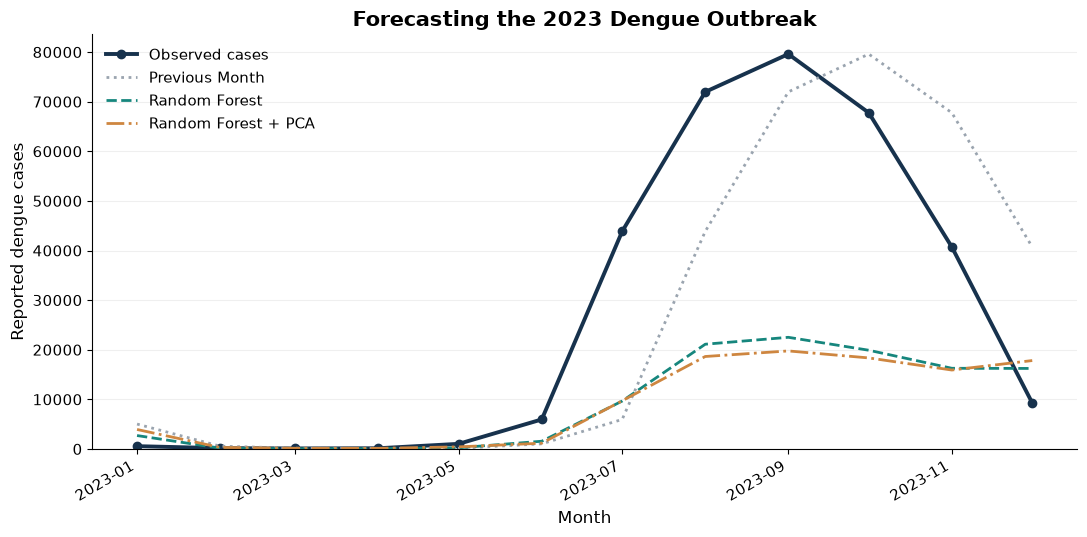

Outbreak-year diagnostics completed!


In [46]:

# STEP 5.8 OUTBREAK-YEAR ERROR DIAGNOSTICS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import mean_absolute_error

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Create test prediction table
test_predictions = pd.DataFrame({
    "Date": pd.to_datetime(final_test["date"]).to_numpy(),
    "Actual": y_test.to_numpy()
})

models = [
    "Previous Month",
    "Random Forest",
    "Random Forest + PCA",
    "XGBoost",
    "XGBoost + PCA"
]

for model in models:
    test_predictions[model] = np.asarray(predictions[model])

test_predictions["Year"] = test_predictions["Date"].dt.year

# Year-wise forecasting errors
yearly_test_results = []

for year, group in test_predictions.groupby("Year"):
    for model in models:

        actual = group["Actual"].to_numpy()
        predicted = group[model].to_numpy()

        yearly_test_results.append({
            "Year": year,
            "Model": model,
            "MAE": mean_absolute_error(actual, predicted),
            "Bias": np.mean(predicted - actual)
        })

yearly_test_results = pd.DataFrame(yearly_test_results)

print("===== YEAR-WISE FINAL TEST RESULTS =====")
display(yearly_test_results.round(2))

# Identify largest monthly outbreak in test period
peak_idx = test_predictions["Actual"].idxmax()
peak = test_predictions.loc[peak_idx]

print("\n===== LARGEST MONTHLY OUTBREAK =====")
print("Date:", peak["Date"].strftime("%Y-%m"))
print("Observed cases:", int(peak["Actual"]))

peak_comparison = pd.DataFrame({
    "Model": models,
    "Predicted_Cases": [
        peak[model] for model in models
    ],
    "Error": [
        peak[model] - peak["Actual"] for model in models
    ]
})

display(peak_comparison.round(2))

# Save results
yearly_test_results.to_csv(
    OUTPUT_DIR / "yearwise_final_test_results.csv",
    index=False
)

peak_comparison.to_csv(
    OUTPUT_DIR / "outbreak_peak_comparison.csv",
    index=False
)

# Plot 2023 outbreak forecasts
outbreak_2023 = test_predictions[
    test_predictions["Year"] == 2023
]

fig, ax = plt.subplots(figsize=(11, 5.5))

styles = {
    "Actual": ("#17324D", "-", 2.8),
    "Previous Month": ("#9AA4AF", ":", 2),
    "Random Forest": ("#16867D", "--", 2),
    "Random Forest + PCA": ("#CE8640", "-.", 2)
}

for model, (color, style, width) in styles.items():
    ax.plot(
        outbreak_2023["Date"],
        outbreak_2023[model],
        color=color,
        linestyle=style,
        linewidth=width,
        marker="o" if model == "Actual" else None,
        label="Observed cases" if model == "Actual" else model
    )

ax.set_title(
    "Forecasting the 2023 Dengue Outbreak",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Month")
ax.set_ylabel("Reported dengue cases")
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False)

fig.autofmt_xdate()
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "Figure_14_2023_Outbreak_Forecasts.png",
    dpi=400,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "Figure_14_2023_Outbreak_Forecasts.pdf",
    bbox_inches="tight"
)

plt.show()

print("Outbreak-year diagnostics completed!")


The year-wise evaluation demonstrates substantial variation in forecasting performance across epidemic periods.

During the exceptional 2023 outbreak, all Machine Learning models substantially underestimated dengue incidence. Random Forest predicted approximately 22,509 cases for September 2023, compared with 79,598 observed cases, representing an underprediction of approximately 71.7%.

The previous-month baseline performed considerably better during this peak, although its predictions depended on the previous month's observed case count.
In contrast, XGBoost achieved the lowest annual MAE in 2024 and 2025. This suggests that relative model performance depends strongly on outbreak characteristics and evaluation periods.

Overall, the results highlight limited generalization of Machine Learning models during unprecedented epidemic outbreaks, despite their promising validation performance.

#### Seasonal naïve baseline

In [61]:
from pathlib import Path

print("Current folder:", Path.cwd())

for file in Path.cwd().glob("*.xlsx"):
    print("Excel file:", file.name)

Current folder: /Users/selimmondol/Downloads/Research/Dengue


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Find audited dataset
folder = Path.cwd() / "Data"
filename = "Bangladesh_Dengue_2000_2025_UPDATED_AUDITED.xlsx"

matches = list(folder.glob(filename))

if not matches:
    raise FileNotFoundError(
        f"Dataset not found under: {folder}\n"
        "Check the filename or ensure the Excel file is inside the Data folder."
    )

file_path = matches[0]
print("Dataset found:", file_path)

# 2. Read data
df = pd.read_excel(file_path, sheet_name="Research_Data")
df = df.sort_values(["Year", "Month_Number"]).reset_index(drop=True)

# 3. Seasonal naive: same month in previous year
df["Seasonal_Naive"] = df["Cases"].shift(12)

# 4. Final test period
test = df[df["Year"].between(2023, 2025)].copy()

actual = test["Cases"].to_numpy()
predicted = test["Seasonal_Naive"].to_numpy()

assert len(test) == 36, "Expected 36 test months."
assert not np.isnan(predicted).any(), "Missing predictions found."

# 5. Calculate metrics
mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))
log_mae = np.mean(np.abs(np.log1p(actual) - np.log1p(predicted)))
bias = np.mean(predicted - actual)

# 6. Display results
print("\nSEASONAL NAIVE BASELINE — 2023–2025")
print("-----------------------------------")
print(f"MAE     : {mae:,.2f}")
print(f"RMSE    : {rmse:,.2f}")
print(f"Log MAE : {log_mae:.3f}")
print(f"Bias    : {bias:,.2f}")

Dataset found: /Users/selimmondol/Downloads/Research/Dengue/Data/Bangladesh_Dengue_2000_2025_UPDATED_AUDITED.xlsx

SEASONAL NAIVE BASELINE — 2023–2025
-----------------------------------
MAE     : 14,381.81
RMSE    : 26,570.02
Log MAE : 1.170
Bias    : -1,124.42


#### 6 — Bootstrap Uncertainty Analysis

===== BLOCK BOOTSTRAP RESULTS =====


,Model,MAE_Difference,CI_Lower,CI_Upper
0,Random Forest,1989.75,-1005.80,7715.18
1,Random Forest + PCA,2551.04,-715.56,8594.78
2,XGBoost,1924.07,-1933.76,8135.25
3,XGBoost + PCA,2396.76,-1405.05,8622.26


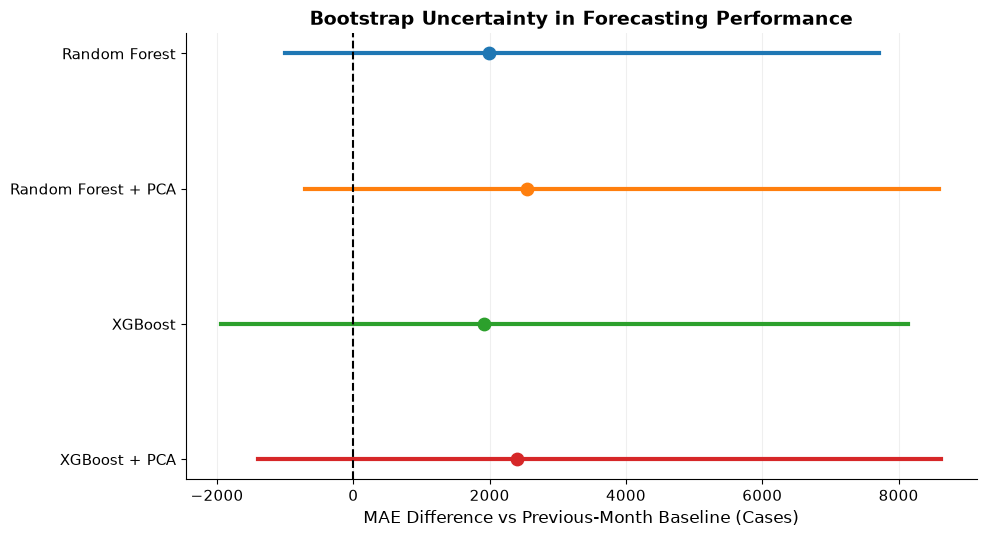

Bootstrap analysis completed!


In [47]:

# STEP 6.1: PAIRED MOVING BLOCK BOOTSTRAP
# Final test period: 2023-2025

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Use the frozen final-test predictions from Step 10.8
bootstrap_data = test_predictions.copy()

models = [
    "Random Forest",
    "Random Forest + PCA",
    "XGBoost",
    "XGBoost + PCA"
]

y_true = bootstrap_data["Actual"].to_numpy()
baseline = bootstrap_data["Previous Month"].to_numpy()

n = len(y_true)

# Bootstrap settings
B = 2000
block_length = 6
rng = np.random.default_rng(42)

# Generate paired block-bootstrap samples
bootstrap_indices = []

for _ in range(B):
    starts = rng.integers(
        0,
        n - block_length + 1,
        size=int(np.ceil(n / block_length))
    )

    indices = np.concatenate([
        np.arange(start, start + block_length)
        for start in starts
    ])[:n]

    bootstrap_indices.append(indices)

# Calculate MAE differences relative to baseline
results = []

baseline_error = np.abs(y_true - baseline)

for model in models:

    model_pred = bootstrap_data[model].to_numpy()
    model_error = np.abs(y_true - model_pred)

    # Positive difference means model is worse
    error_difference = model_error - baseline_error

    observed_difference = error_difference.mean()

    boot_differences = np.array([
        error_difference[idx].mean()
        for idx in bootstrap_indices
    ])

    ci_low, ci_high = np.percentile(
        boot_differences, [2.5, 97.5]
    )

    results.append({
        "Model": model,
        "MAE_Difference": observed_difference,
        "CI_Lower": ci_low,
        "CI_Upper": ci_high
    })

bootstrap_results = pd.DataFrame(results)

print("===== BLOCK BOOTSTRAP RESULTS =====")
display(bootstrap_results.round(2))

# Publication-style confidence interval plot
fig, ax = plt.subplots(figsize=(10, 5.5))

for i, row in bootstrap_results.iterrows():

    ax.plot(
        [row["CI_Lower"], row["CI_Upper"]],
        [i, i],
        linewidth=3
    )

    ax.scatter(
        row["MAE_Difference"], i,
        s=80, zorder=3
    )

ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.5
)

ax.set_yticks(range(len(bootstrap_results)))
ax.set_yticklabels(bootstrap_results["Model"])

ax.set_title(
    "Bootstrap Uncertainty in Forecasting Performance",
    fontweight="bold",
    fontsize=14
)

ax.set_xlabel(
    "MAE Difference vs Previous-Month Baseline (Cases)"
)

ax.grid(axis="x", alpha=0.2)
ax.invert_yaxis()

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "Figure_15_Bootstrap_MAE_Comparison.png",
    dpi=400,
    bbox_inches="tight"
)

plt.savefig(
    OUTPUT_DIR / "Figure_15_Bootstrap_MAE_Comparison.pdf",
    bbox_inches="tight"
)

plt.show()

bootstrap_results.to_csv(
    OUTPUT_DIR / "bootstrap_mae_results.csv",
    index=False
)

print("Bootstrap analysis completed!")


The moving-block bootstrap analysis was used to assess uncertainty in forecasting performance differences between Machine Learning models and the previous-month baseline.

All four Machine Learning models exhibited positive MAE differences, indicating worse average forecasting performance than the baseline during 2023–2025.

However, all bootstrap confidence intervals include zero, indicating that the observed differences are not statistically distinguishable from zero at the corresponding confidence level.

The wide intervals reflect substantial uncertainty, partly associated with the limited 36-month evaluation period and the exceptional 2023 dengue outbreak.

These results do not demonstrate equivalence between the models. Instead, they indicate insufficient evidence to establish a reliable difference in forecasting accuracy.

#### 6.2 Bootstrap Sensitivity Analysis

===== BOOTSTRAP SENSITIVITY RESULTS =====


,Block_Length,Model,MAE_Difference,CI_Lower,CI_Upper,Includes_Zero
0,3,Random Forest,1989.75,-1280.57,8035.60,True
1,3,Random Forest + PCA,2551.04,-860.87,8861.79,True
2,3,XGBoost,1924.07,-2170.07,8611.31,True
3,3,XGBoost + PCA,2396.76,-1604.63,8997.06,True
4,6,Random Forest,1989.75,-1005.80,7715.18,True
5,6,Random Forest + PCA,2551.04,-715.56,8594.78,True
6,6,XGBoost,1924.07,-1933.76,8135.25,True
7,6,XGBoost + PCA,2396.76,-1405.05,8622.26,True
8,12,Random Forest,1989.75,-930.19,6678.31,True
9,12,Random Forest + PCA,2551.04,-607.72,7537.15,True


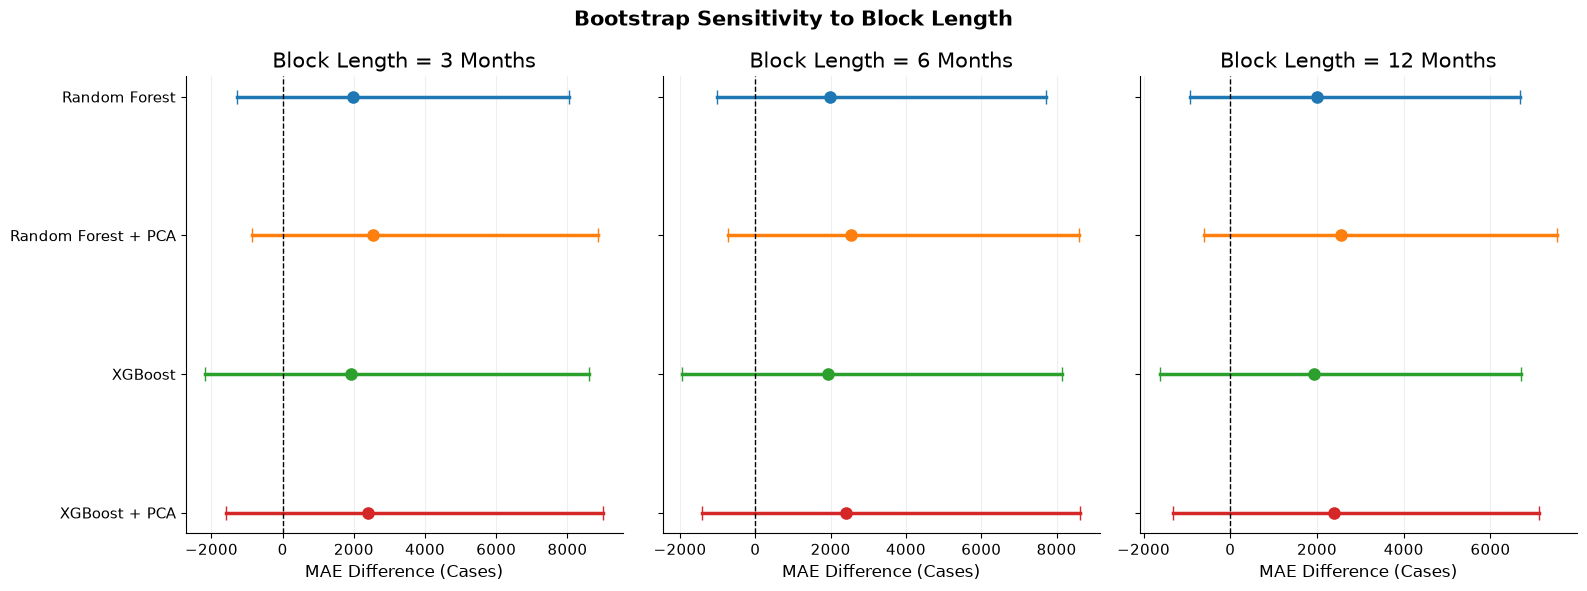

Bootstrap sensitivity analysis completed!


In [55]:

# STEP 6.2: BLOCK BOOTSTRAP SENSITIVITY ANALYSIS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

y_true = test_predictions["Actual"].to_numpy()
baseline = test_predictions["Previous Month"].to_numpy()

models = [
    "Random Forest",
    "Random Forest + PCA",
    "XGBoost",
    "XGBoost + PCA"
]

n = len(y_true)
B = 2000

block_lengths = [3, 6, 12]

baseline_error = np.abs(y_true - baseline)

sensitivity_results = []

for block_length in block_lengths:

    rng = np.random.default_rng(42)

    bootstrap_indices = []

    for _ in range(B):

        starts = rng.integers(
            0,
            n - block_length + 1,
            size=int(np.ceil(n / block_length))
        )

        indices = np.concatenate([
            np.arange(start, start + block_length)
            for start in starts
        ])[:n]

        bootstrap_indices.append(indices)

    for model in models:

        model_pred = test_predictions[model].to_numpy()
        model_error = np.abs(y_true - model_pred)

        difference = model_error - baseline_error

        observed = difference.mean()

        boot_values = np.array([
            difference[idx].mean()
            for idx in bootstrap_indices
        ])

        ci_low, ci_high = np.percentile(
            boot_values, [2.5, 97.5]
        )

        sensitivity_results.append({
            "Block_Length": block_length,
            "Model": model,
            "MAE_Difference": observed,
            "CI_Lower": ci_low,
            "CI_Upper": ci_high,
            "Includes_Zero": ci_low <= 0 <= ci_high
        })

sensitivity_df = pd.DataFrame(sensitivity_results)

print("===== BOOTSTRAP SENSITIVITY RESULTS =====")
display(sensitivity_df.round(2))

# Save results
sensitivity_df.to_csv(
    OUTPUT_DIR / "bootstrap_sensitivity_results.csv",
    index=False
)

# Visualization
fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 6),
    sharey=True
)

for ax, block_length in zip(axes, block_lengths):

    subset = sensitivity_df[
        sensitivity_df["Block_Length"] == block_length
    ].reset_index(drop=True)

    for i, row in subset.iterrows():

        ax.plot(
            [row["CI_Lower"], row["CI_Upper"]],
            [i, i],
            linewidth=2.5,
            marker="|",
            markersize=10
        )

        ax.scatter(
            row["MAE_Difference"], i,
            s=65,
            zorder=3
        )

    ax.axvline(
        0,
        color="black",
        linestyle="--",
        linewidth=1
    )

    ax.set_title(
        f"Block Length = {block_length} Months"
    )

    ax.set_xlabel("MAE Difference (Cases)")
    ax.grid(axis="x", alpha=0.2)
    ax.set_yticks(range(len(models)))

    if ax == axes[0]:
        ax.set_yticklabels(models)

    ax.invert_yaxis()

fig.suptitle(
    "Bootstrap Sensitivity to Block Length",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "Figure_16_Bootstrap_Sensitivity.png",
    dpi=400,
    bbox_inches="tight"
)

plt.savefig(
    OUTPUT_DIR / "Figure_16_Bootstrap_Sensitivity.pdf",
    bbox_inches="tight"
)

plt.show()

print("Bootstrap sensitivity analysis completed!")


The moving-block bootstrap sensitivity analysis assessed the robustness of forecasting performance differences across block lengths of 3, 6, and 12 months.

All four Machine Learning models exhibited positive MAE differences relative to the previous-month baseline, indicating higher observed forecasting errors during 2023–2025.

However, all confidence intervals included zero across all three block lengths. Therefore, the analysis does not provide sufficient statistical evidence that the models differ reliably in forecasting accuracy.

The conclusion is consistent across block-length choices, although uncertainty remains substantial due to the relatively short test period of 36 months.

Research conclusion
আমাদের Bootstrap analysis থেকে যা নিশ্চিত হলো:
- Previous-month baseline-এর observed MAE সবচেয়ে কম।
- সব ML model-এর MAE বেশি।
- কিন্তু statistical uncertainty থাকার কারণে baseline-এর superiority নিশ্চিতভাবে প্রতিষ্ঠিত হয়নি।
- Block length পরিবর্তন করলেও এই conclusion বদলায়নি।

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import StrMethodFormatter
from pathlib import Path

# =========================================================
# FIG 7 — Corrected final plot for 2023–2025 test period
# =========================================================

# ---- File path ----
csv_path = Path("outputs/Fig7_Test_2023_2025_predictions.csv")

if not csv_path.exists():
    raise FileNotFoundError(
        f"Could not find: {csv_path}\n"
        "Make sure the CSV file exists in the outputs folder."
    )

# ---- Load data ----
plot_df = pd.read_csv(csv_path)

# If an unnamed index column exists, remove it
plot_df = plot_df.loc[:, ~plot_df.columns.str.contains("^Unnamed")]

# ---- Check columns ----
required_cols = ["Date", "Actual", "Previous Month", "Random Forest", "XGBoost"]
missing = [col for col in required_cols if col not in plot_df.columns]

if missing:
    raise ValueError(
        f"Missing required columns: {missing}\n"
        f"Available columns: {list(plot_df.columns)}"
    )

# ---- Prepare dataframe ----
plot_df["Date"] = pd.to_datetime(plot_df["Date"])
plot_df = plot_df.sort_values("Date").reset_index(drop=True)

# ---- Restrict exactly to Jan 2023 – Dec 2025 ----
plot_df = plot_df[
    (plot_df["Date"] >= pd.Timestamp("2023-01-01")) &
    (plot_df["Date"] <= pd.Timestamp("2025-12-01"))
].copy()

# ---- Basic checks ----
assert len(plot_df) == 36, f"Expected 36 months, got {len(plot_df)}"
assert plot_df["Date"].min() == pd.Timestamp("2023-01-01"), "Start date should be 2023-01-01"
assert plot_df["Date"].max() == pd.Timestamp("2025-12-01"), "End date should be 2025-12-01"

# ---- Check September 2023 row ----
peak_row = plot_df.loc[plot_df["Date"] == pd.Timestamp("2023-09-01")]

if peak_row.empty:
    raise ValueError("September 2023 row not found in the data.")

peak = peak_row.iloc[0]

print("September 2023 values:")
print(peak.to_string())

# Optional manuscript checks
expected_values = {
    "Actual": 79598,
    "Previous Month": 71976,
    "Random Forest": 22508.54,
    "XGBoost": 20264.54
}

print("\nComparison with manuscript values:")
for key, expected in expected_values.items():
    observed = peak[key]
    print(f"{key:15s} observed = {observed:,.2f} | manuscript = {expected:,.2f}")

# =========================================================
# Plot
# =========================================================
fig, ax = plt.subplots(figsize=(13.5, 6.8))

# Colors/styles
styles = {
    "Actual": {
        "color": "#17324D",
        "linestyle": "-",
        "linewidth": 2.8,
        "label": "Observed cases",
        "marker": "o",
        "markersize": 3.5,
        "zorder": 4
    },
    "Previous Month": {
        "color": "#94A3B8",
        "linestyle": ":",
        "linewidth": 2.3,
        "label": "Previous-month baseline",
        "marker": None,
        "zorder": 2
    },
    "Random Forest": {
        "color": "#16867D",
        "linestyle": "--",
        "linewidth": 2.3,
        "label": "Random Forest",
        "marker": None,
        "zorder": 3
    },
    "XGBoost": {
        "color": "#D3832F",
        "linestyle": "-.",
        "linewidth": 2.3,
        "label": "XGBoost",
        "marker": None,
        "zorder": 3
    }
}

# Draw lines
for col, s in styles.items():
    ax.plot(
        plot_df["Date"],
        plot_df[col],
        color=s["color"],
        linestyle=s["linestyle"],
        linewidth=s["linewidth"],
        marker=s["marker"],
        markersize=s.get("markersize", None),
        label=s["label"],
        zorder=s["zorder"]
    )

# Shade 2025 provisional/derived period
ax.axvspan(
    pd.Timestamp("2025-01-01"),
    pd.Timestamp("2025-12-31"),
    color="#9AA4AF",
    alpha=0.14,
    zorder=0
)

# Main title
ax.set_title(
    "Observed vs Predicted Monthly Dengue Cases",
    fontsize=20,
    fontweight="bold",
    pad=18
)

# Subtitle
ax.text(
    0.005, 1.015,
    "Bangladesh | One-month-ahead forecasts | 2023–2025 test period",
    transform=ax.transAxes,
    fontsize=12.5,
    color="#556B84",
    ha="left",
    va="bottom"
)

# Annotation for Sep 2023
ax.annotate(
    "Sep 2023: 79,598 cases",
    xy=(peak["Date"], peak["Actual"]),
    xytext=(20, 12),  # moved so it won't hit the title
    textcoords="offset points",
    fontsize=12,
    color="#222222",
    bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="none", alpha=0.85),
    arrowprops=dict(arrowstyle="->", lw=1.2, color="#222222")
)

# Axis labels
ax.set_xlabel("Month", fontsize=15)
ax.set_ylabel("Reported dengue cases", fontsize=15)

# X-axis formatting
ax.set_xlim(pd.Timestamp("2023-01-01"), pd.Timestamp("2025-12-31"))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=35, ha="right", fontsize=11)

# Y-axis formatting
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.tick_params(axis="y", labelsize=11)
ax.set_ylim(bottom=0)

# Grid
ax.grid(axis="y", linestyle="--", alpha=0.25)

# Remove top/right spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Legend
ax.legend(
    frameon=False,
    ncol=2,
    loc="upper right",
    fontsize=12
)

plt.tight_layout()

# =========================================================
# Save outputs
# =========================================================
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

png_path = output_dir / "Fig7_Test_2023_2025_CORRECTED.png"
pdf_path = output_dir / "Fig7_Test_2023_2025_CORRECTED.pdf"

fig.savefig(png_path, dpi=400, bbox_inches="tight")
fig.savefig(pdf_path, bbox_inches="tight")

plt.show()

print("\nSaved files:")
print(png_path)
print(pdf_path)

FileNotFoundError: Could not find: outputs/Fig7_Test_2023_2025_predictions.csv
Make sure the CSV file exists in the outputs folder.

Dataset loaded successfully.
Dataset shape: (312, 22)
XGBoost version: 3.4.1
Feature engineering completed.

Training months: 264
Testing months: 36

Prediction data prepared.
        Date  Actual  Previous Month  Random Forest      XGBoost
0 2023-01-01     566          5024.0    2708.484937  2843.587158
1 2023-02-01     166           566.0     171.169741   437.453949
2 2023-03-01     111           166.0      50.636266    76.720070
3 2023-04-01     143           111.0      59.289745    60.605072
4 2023-05-01    1036           143.0     241.986659    75.659714

===== SEPTEMBER 2023 CHECK =====
Actual: 79,598.00 | Expected: 79,598.00 | OK
Previous Month: 71,976.00 | Expected: 71,976.00 | OK
Random Forest: 22,508.54 | Expected: 22,508.54 | OK
XGBoost: 20,264.54 | Expected: 20,264.54 | OK

===== TEST MAE CHECK =====
Previous Month: 7,430.444 | Expected: 7,430.444 | OK
Random Forest: 9,420.196 | Expected: 9,420.196 | OK
XGBoost: 9,354.520 | Expected: 9,354.520 | OK

All manuscript verificat

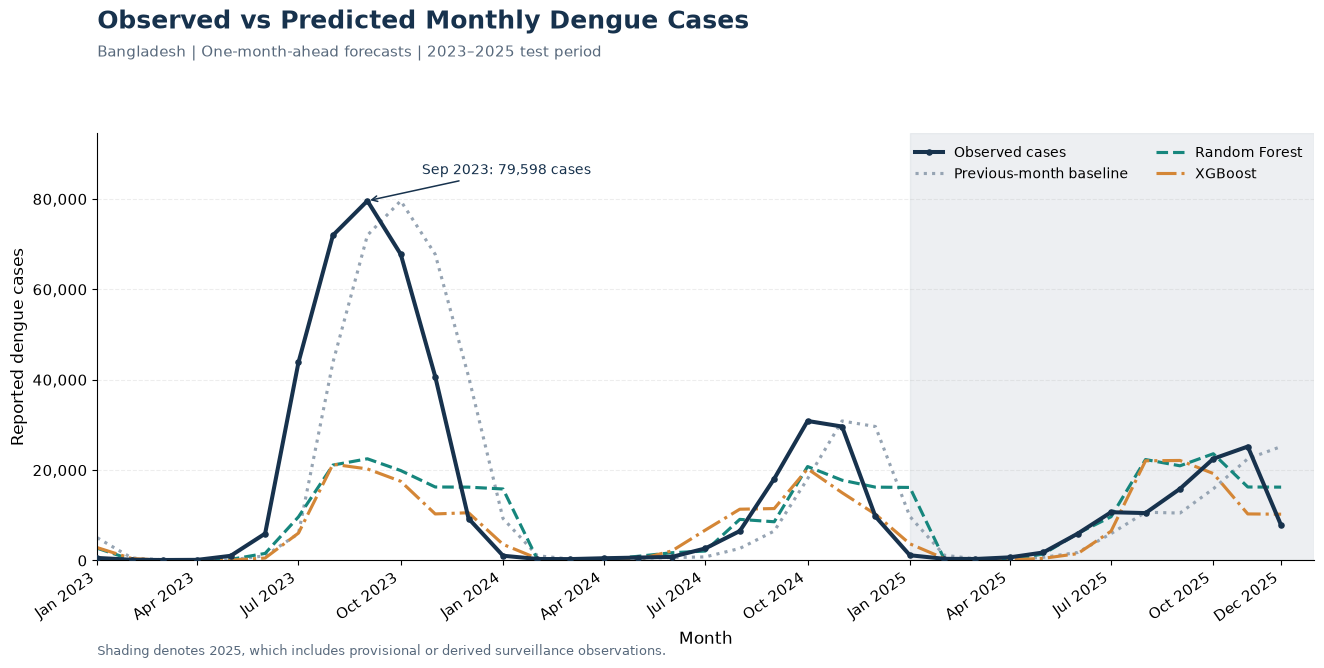


FIGURE 7 CREATED SUCCESSFULLY
Output folder: /Users/selimmondol/Downloads/Research/Dengue/outputs


In [ ]:

# ============================================================
# FIGURE 7 — OBSERVED VS PREDICTED MONTHLY DENGUE CASES
# Bangladesh | 2023–2025 independent test period
#
# Models:
#   1. Previous-month baseline
#   2. Random Forest
#   3. XGBoost
#
# No previous prediction CSV or notebook variables required.
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import StrMethodFormatter

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from xgboost import XGBRegressor
import xgboost


# ============================================================
# STEP 1 — LOAD ORIGINAL AUDITED DATASET
# ============================================================

file_name = "Bangladesh_Dengue_2000_2025_UPDATED_AUDITED.xlsx"

search_folders = [
    Path.cwd() / "Data",
    Path.cwd()
]

file_path = next(
    (
        folder / file_name
        for folder in search_folders
        if (folder / file_name).exists()
    ),
    None
)

if file_path is None:
    raise FileNotFoundError(
        f"Cannot find {file_name}.\n"
        "Put the Excel file in the same folder as your notebook.\n"
        f"Current working folder: {Path.cwd()}"
    )

df = pd.read_excel(
    file_path,
    sheet_name="Research_Data"
)

df["date"] = pd.to_datetime(
    dict(
        year=df["Year"],
        month=df["Month_Number"],
        day=1
    )
)

df = df.sort_values("date").reset_index(drop=True)

assert len(df) == 312, "Expected 312 monthly observations."
assert df["Cases"].sum() == 769500, "Dataset total differs."

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
print("XGBoost version:", xgboost.__version__)


# ============================================================
# STEP 2 — FEATURE ENGINEERING
# ============================================================

climate_features = [
    "T2M_C",
    "T2M_MIN_C",
    "T2M_MAX_C",
    "RH2M_pct",
    "PRECTOTCORR_SUM_mm_month",
    "PS_kPa",
    "WS50M_MAX_m_s",
    "QV2M_g_kg",
    "WS2M_m_s"
]

data = df.copy()

# Dengue lag features
data["Cases_lag1"] = data["Cases"].shift(1)
data["Cases_lag12"] = data["Cases"].shift(12)

# Lagged climate features
climate_lags = []

for feature in climate_features:
    new_col = feature + "_lag1"
    data[new_col] = data[feature].shift(1)
    climate_lags.append(new_col)

# Seasonal features
data["month_sin"] = np.sin(
    2 * np.pi * data["Month_Number"] / 12
)

data["month_cos"] = np.cos(
    2 * np.pi * data["Month_Number"] / 12
)

feature_cols = climate_lags + [
    "Cases_lag1",
    "Cases_lag12",
    "month_sin",
    "month_cos"
]

data = data.dropna(
    subset=feature_cols + ["Cases"]
).reset_index(drop=True)

print("Feature engineering completed.")


# ============================================================
# STEP 3 — CHRONOLOGICAL TRAIN / TEST SPLIT
# ============================================================

train_data = data[
    data["date"] < "2023-01-01"
].copy()

test_data = data[
    (data["date"] >= "2023-01-01") &
    (data["date"] <= "2025-12-01")
].copy()

X_train = train_data[feature_cols]
y_train = train_data["Cases"]

X_test = test_data[feature_cols]
y_test = test_data["Cases"]

assert len(train_data) == 264
assert len(test_data) == 36

print("\nTraining months:", len(train_data))
print("Testing months:", len(test_data))


# ============================================================
# STEP 4 — RANDOM FOREST
# Original notebook configuration
# ============================================================

rf_model = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

pred_rf = np.maximum(
    rf_model.predict(X_test),
    0
)


# ============================================================
# STEP 5 — XGBOOST
# Original notebook configuration
# ============================================================

xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=2,
    learning_rate=0.03,
    subsample=0.9,
    colsample_bytree=0.9,
    min_child_weight=3,
    reg_lambda=5,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42,
    n_jobs=4
)

xgb_model.fit(X_train, y_train)

pred_xgb = np.maximum(
    xgb_model.predict(X_test),
    0
)


# ============================================================
# STEP 6 — PREVIOUS-MONTH BASELINE
# ============================================================

pred_baseline = test_data[
    "Cases_lag1"
].to_numpy()


# ============================================================
# STEP 7 — BUILD PREDICTION DATAFRAME
# ============================================================

plot_df = pd.DataFrame({
    "Date": test_data["date"].to_numpy(),
    "Actual": y_test.to_numpy(),
    "Previous Month": pred_baseline,
    "Random Forest": pred_rf,
    "XGBoost": pred_xgb
})

plot_df = plot_df.sort_values(
    "Date"
).reset_index(drop=True)

print("\nPrediction data prepared.")
print(plot_df.head())


# ============================================================
# STEP 8 — VERIFY AGAINST MANUSCRIPT RESULTS
# ============================================================

sep = plot_df[
    plot_df["Date"] == "2023-09-01"
].iloc[0]

expected_peak = {
    "Actual": 79598,
    "Previous Month": 71976,
    "Random Forest": 22508.54,
    "XGBoost": 20264.54
}

expected_mae = {
    "Previous Month": 7430.444,
    "Random Forest": 9420.196,
    "XGBoost": 9354.520
}

problems = []

print("\n===== SEPTEMBER 2023 CHECK =====")

for model, expected in expected_peak.items():

    actual = float(sep[model])

    match = np.isclose(
        actual,
        expected,
        atol=1.0
    )

    print(
        f"{model}: {actual:,.2f} "
        f"| Expected: {expected:,.2f} "
        f"| {'OK' if match else 'MISMATCH'}"
    )

    if not match:
        problems.append(model + " peak")

print("\n===== TEST MAE CHECK =====")

for model, expected in expected_mae.items():

    mae = mean_absolute_error(
        plot_df["Actual"],
        plot_df[model]
    )

    match = np.isclose(
        mae,
        expected,
        atol=1.0
    )

    print(
        f"{model}: {mae:,.3f} "
        f"| Expected: {expected:,.3f} "
        f"| {'OK' if match else 'MISMATCH'}"
    )

    if not match:
        problems.append(model + " MAE")

if problems:
    raise RuntimeError(
        "MODEL RESULTS DO NOT MATCH THE MANUSCRIPT.\n"
        "Mismatches: " + ", ".join(problems) + "\n"
        "Check the original XGBoost software version "
        "and notebook environment before creating Fig 7."
    )

print("\nAll manuscript verification checks passed.")


# ============================================================
# STEP 9 — CREATE PUBLICATION-QUALITY FIGURE 7
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11
})

fig, ax = plt.subplots(
    figsize=(13.6, 7)
)

fig.subplots_adjust(
    left=0.09,
    right=0.985,
    bottom=0.18,
    top=0.79
)

# Shade 2025 period
ax.axvspan(
    pd.Timestamp("2025-01-01"),
    pd.Timestamp("2025-12-31"),
    color="#CBD2DA",
    alpha=0.34,
    zorder=0
)

# Observed cases
ax.plot(
    plot_df["Date"],
    plot_df["Actual"],
    color="#17324D",
    linewidth=2.9,
    linestyle="-",
    marker="o",
    markersize=3.7,
    label="Observed cases",
    zorder=4
)

# Previous-month baseline
ax.plot(
    plot_df["Date"],
    plot_df["Previous Month"],
    color="#96A4B3",
    linewidth=2.25,
    linestyle=":",
    label="Previous-month baseline"
)

# Random Forest
ax.plot(
    plot_df["Date"],
    plot_df["Random Forest"],
    color="#16867D",
    linewidth=2.25,
    linestyle="--",
    label="Random Forest"
)

# XGBoost
ax.plot(
    plot_df["Date"],
    plot_df["XGBoost"],
    color="#D48636",
    linewidth=2.25,
    linestyle="-.",
    label="XGBoost"
)


# ============================================================
# STEP 10 — ANNOTATE SEPTEMBER 2023 PEAK
# ============================================================

ax.annotate(
    "Sep 2023: 79,598 cases",
    xy=(
        pd.Timestamp("2023-09-01"),
        79598
    ),
    xytext=(
        pd.Timestamp("2023-10-20"),
        85500
    ),
    fontsize=10,
    color="#17324D",
    arrowprops=dict(
        arrowstyle="->",
        linewidth=1.1,
        color="#17324D"
    )
)


# ============================================================
# STEP 11 — AXIS FORMATTING
# ============================================================

ax.set_xlim(
    pd.Timestamp("2023-01-01"),
    pd.Timestamp("2025-12-31")
)

ax.set_ylim(0, 94500)

# Quarterly ticks + December 2025 endpoint
ticks = list(
    pd.date_range(
        "2023-01-01",
        "2025-10-01",
        freq="QS-JAN"
    )
)

ticks.append(
    pd.Timestamp("2025-12-01")
)

ax.set_xticks(ticks)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

plt.setp(
    ax.get_xticklabels(),
    rotation=35,
    ha="right"
)

ax.yaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

ax.set_xlabel(
    "Month",
    fontsize=12
)

ax.set_ylabel(
    "Reported dengue cases",
    fontsize=12
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.22
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    loc="upper right",
    ncol=2,
    frameon=False,
    fontsize=10
)


# ============================================================
# STEP 12 — TITLE AND SUBTITLE
# ============================================================

fig.text(
    0.09,
    0.94,
    "Observed vs Predicted Monthly Dengue Cases",
    fontsize=18,
    fontweight="bold",
    color="#17324D"
)

fig.text(
    0.09,
    0.90,
    "Bangladesh | One-month-ahead forecasts | 2023–2025 test period",
    fontsize=11,
    color="#58697C"
)

fig.text(
    0.09,
    0.045,
    "Shading denotes 2025, which includes provisional or derived surveillance observations.",
    fontsize=9,
    color="#58697C"
)


# ============================================================
# STEP 13 — SAVE FIGURE AND PREDICTIONS
# ============================================================

output_dir = Path("outputs")
output_dir.mkdir(
    parents=True,
    exist_ok=True
)

# Save predictions CSV
plot_df.to_csv(
    output_dir / "Fig7_Test_2023_2025_predictions.csv",
    index=False
)

# Save PNG
fig.savefig(
    output_dir / "Fig7_Test_2023_2025_FINAL.png",
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

# Save PDF
fig.savefig(
    output_dir / "Fig7_Test_2023_2025_FINAL.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("\nFIGURE 7 CREATED SUCCESSFULLY")
print("Output folder:", output_dir.resolve())


#### 7 — Explainable AI (SHAP)

In [68]:
%pip install shap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 544.4/544.4 kB 8.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [shap]2/3 [shap]
Note: you may need to restart the kernel to use updated packages.


===== SHAP FEATURE IMPORTANCE =====


,Feature,Mean_Absolute_SHAP
9,Cases_lag1,8409.619
4,PRECTOTCORR_SUM_mm_month_lag1,284.341
0,T2M_C_lag1,248.856
10,Cases_lag12,149.148
8,WS2M_m_s_lag1,119.671
2,T2M_MAX_C_lag1,116.060
6,WS50M_MAX_m_s_lag1,103.868
5,PS_kPa_lag1,89.039
7,QV2M_g_kg_lag1,73.387
1,T2M_MIN_C_lag1,72.858


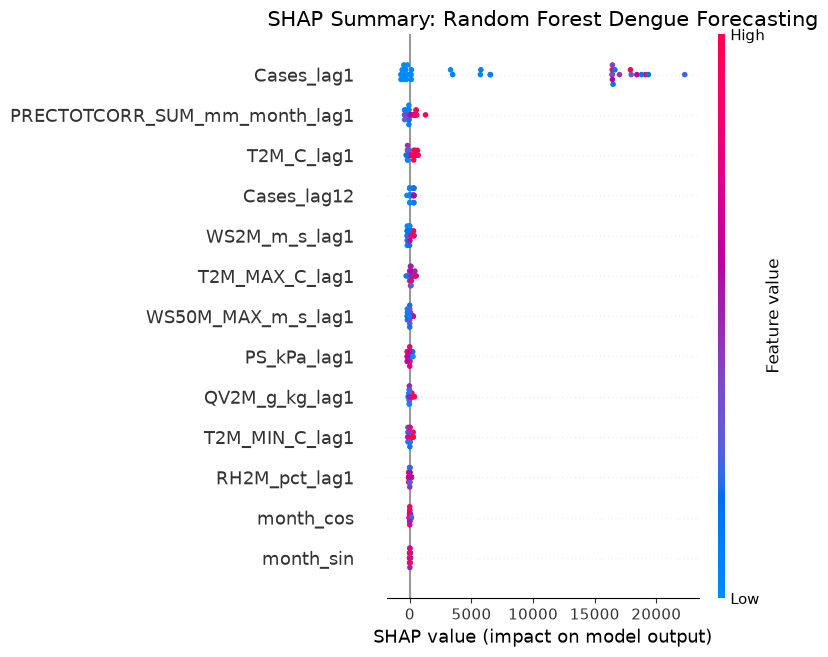

SHAP analysis completed!


In [137]:

# STEP 7.2: EXPLAINABLE AI USING SHAP
# Explain the frozen final Random Forest model

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Final Random Forest trained on data before 2023
rf_model = final_models["Random Forest"]

# Explain predictions for 2023-2025
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer(X_test)

# Global SHAP importance
importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean_Absolute_SHAP": np.abs(
        shap_values.values
    ).mean(axis=0)
})

importance = importance.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

print("===== SHAP FEATURE IMPORTANCE =====")
display(importance.round(3))

# SHAP summary plot
shap.plots.beeswarm(
    shap_values,
    max_display=13,
    show=False
)

plt.title(
    "SHAP Summary: Random Forest Dengue Forecasting"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "Figure_17_SHAP_Summary.png",
    dpi=400,
    bbox_inches="tight"
)

plt.show()

# Save importance results
importance.to_csv(
    OUTPUT_DIR / "shap_feature_importance.csv",
    index=False
)

print("SHAP analysis completed!")


SHAP analysis indicates that previous-month dengue incidence is overwhelmingly the most influential predictor in the Random Forest forecasting model.

The mean absolute SHAP value of previous-month cases (8,409.62) is substantially larger than those of lagged rainfall (284.34) and temperature (248.86).

This suggests that the model relies primarily on recent dengue incidence, while meteorological variables contribute comparatively less to its predictions.

The strong dependence on historical case counts may help explain why Random Forest struggled to anticipate the unprecedented 2023 epidemic: previously observed incidence patterns provided limited information about the magnitude of the emerging outbreak.

Importantly, SHAP measures contributions to model predictions, not causal effects or the statistical significance of climate–dengue associations.

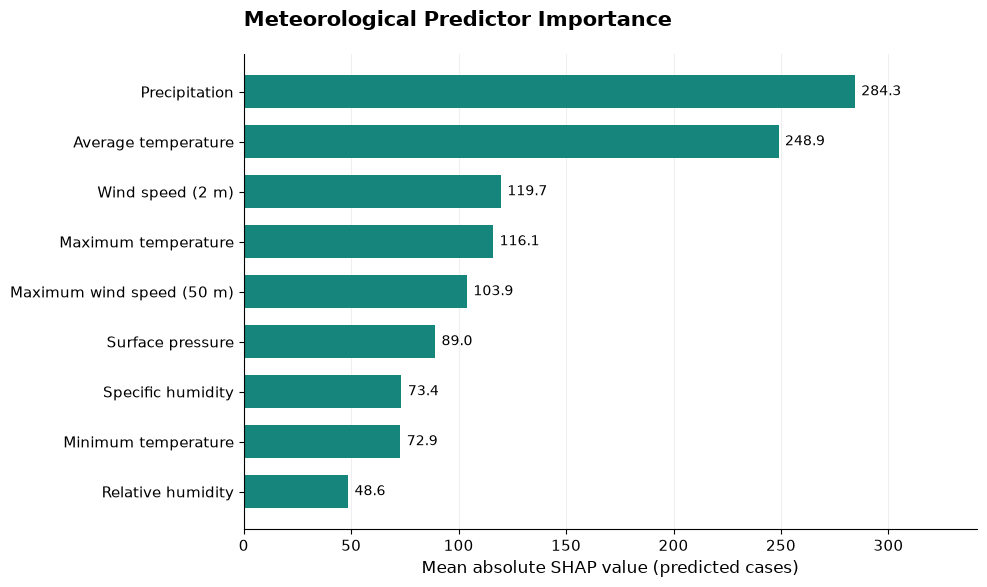

In [138]:

# STEP 7.3: CLIMATE-ONLY SHAP IMPORTANCE

import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Select only climate predictors
climate_importance = importance[
    importance["Feature"].isin(climate_lag_cols)
].copy()

# Improve names for publication
labels = {
    "T2M_C_lag1": "Average temperature",
    "T2M_MIN_C_lag1": "Minimum temperature",
    "T2M_MAX_C_lag1": "Maximum temperature",
    "RH2M_pct_lag1": "Relative humidity",
    "PRECTOTCORR_SUM_mm_month_lag1": "Precipitation",
    "PS_kPa_lag1": "Surface pressure",
    "WS50M_MAX_m_s_lag1": "Maximum wind speed (50 m)",
    "QV2M_g_kg_lag1": "Specific humidity",
    "WS2M_m_s_lag1": "Wind speed (2 m)"
}

climate_importance["Label"] = (
    climate_importance["Feature"].map(labels)
)

climate_importance = climate_importance.sort_values(
    "Mean_Absolute_SHAP"
)

# Publication-style chart
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    climate_importance["Label"],
    climate_importance["Mean_Absolute_SHAP"],
    color="#16867D",
    height=0.65
)

for bar in bars:
    value = bar.get_width()
    ax.text(
        value + 3,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}",
        va="center",
        fontsize=10
    )

ax.set_xlim(
    0,
    climate_importance["Mean_Absolute_SHAP"].max() * 1.2
)

ax.set_title(
    "Meteorological Predictor Importance",
    fontsize=15,
    fontweight="bold",
    loc="left",
    pad=20
)

ax.set_xlabel("Mean absolute SHAP value (predicted cases)")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "Figure_18_Climate_SHAP.png",
    dpi=400,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "Figure_18_Climate_SHAP.pdf",
    bbox_inches="tight"
)

plt.show()


SHAP analysis identified precipitation as the most influential meteorological predictor in the Random Forest forecasting model, followed by average temperature and near-surface wind speed.

However, meteorological contributions were substantially smaller than the contribution of previous-month dengue cases (mean absolute SHAP = 8,409.62).

Interestingly, relative humidity showed the strongest season-adjusted Spearman correlation with dengue incidence (ρ = 0.341), but relatively low SHAP importance.

This distinction is important: correlation measures the association between two variables, whereas SHAP describes how a fitted predictive model uses individual features in the presence of other predictors.

Correlated meteorological predictors may also share predictive information, reducing the apparent importance of individual variables.

These results suggest that meteorological conditions provide supplementary predictive information, while recent dengue incidence dominates the Random Forest forecasts. SHAP importance does not establish causal influence.

===== FEATURE ABLATION RESULTS =====


,Model,MAE,RMSE,Log_MAE
0,Cases + Climate + Season,1383.464,3281.585,1.029
1,Cases + Season,1516.005,3439.284,1.197
2,Previous Month,1579.028,3545.568,1.025
3,Climate + Season,2724.800,5502.434,1.778


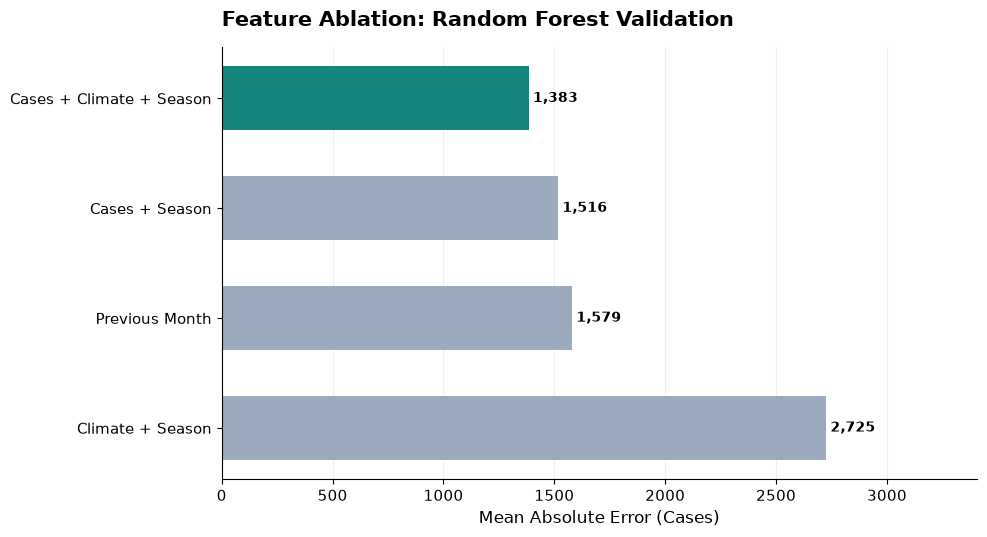

Feature ablation analysis completed!


In [139]:

# STEP 7.4: FEATURE ABLATION ANALYSIS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Define feature sets
case_features = [
    "Cases_lag1",
    "Cases_lag12",
    "month_sin",
    "month_cos"
]

climate_only_features = climate_lag_cols + [
    "month_sin",
    "month_cos"
]

full_features = case_features + climate_lag_cols

feature_sets = {
    "Cases + Season": case_features,
    "Climate + Season": climate_only_features,
    "Cases + Climate + Season": full_features
}

# Use existing chronological train and validation data
ablation_results = []
ablation_predictions = {}

for name, features in feature_sets.items():

    model = clone(rf_original)

    model.fit(
        train[features],
        train["Cases"]
    )

    pred = np.maximum(
        model.predict(val[features]), 0
    )

    ablation_predictions[name] = pred

    actual = val["Cases"].to_numpy()

    ablation_results.append({
        "Model": name,
        "MAE": mean_absolute_error(actual, pred),
        "RMSE": np.sqrt(
            mean_squared_error(actual, pred)
        ),
        "Log_MAE": mean_absolute_error(
            np.log1p(actual),
            np.log1p(pred)
        )
    })

# Add naive baseline
baseline_pred = val["Cases_lag1"].to_numpy()
actual = val["Cases"].to_numpy()

ablation_results.append({
    "Model": "Previous Month",
    "MAE": mean_absolute_error(actual, baseline_pred),
    "RMSE": np.sqrt(
        mean_squared_error(actual, baseline_pred)
    ),
    "Log_MAE": mean_absolute_error(
        np.log1p(actual),
        np.log1p(baseline_pred)
    )
})

ablation_df = (
    pd.DataFrame(ablation_results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("===== FEATURE ABLATION RESULTS =====")
display(ablation_df.round(3))

# Publication-style comparison graph
fig, ax = plt.subplots(figsize=(10, 5.5))

colors = [
    "#16867D" if i == 0 else "#9BAABD"
    for i in range(len(ablation_df))
]

bars = ax.barh(
    ablation_df["Model"],
    ablation_df["MAE"],
    color=colors,
    height=0.58
)

ax.invert_yaxis()

for bar in bars:
    value = bar.get_width()
    ax.text(
        value + 20,
        bar.get_y() + bar.get_height() / 2,
        f"{value:,.0f}",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_xlim(0, ablation_df["MAE"].max() * 1.25)

ax.set_title(
    "Feature Ablation: Random Forest Validation",
    fontsize=15,
    fontweight="bold",
    loc="left",
    pad=15
)

ax.set_xlabel("Mean Absolute Error (Cases)")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "Figure_19_Feature_Ablation.png",
    dpi=400,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "Figure_19_Feature_Ablation.pdf",
    bbox_inches="tight"
)

plt.show()

# Save results
ablation_df.to_csv(
    OUTPUT_DIR / "feature_ablation_results.csv",
    index=False
)

print("Feature ablation analysis completed!")


The feature ablation experiment demonstrates that combining historical dengue incidence, meteorological predictors, and seasonal features yielded the lowest validation MAE (1,383.46 cases).

Removing meteorological variables increased MAE to 1,516.01 cases. Thus, including climate information improved validation MAE by approximately 8.7% relative to the Cases + Season configuration.

However, using only climate and seasonal predictors resulted in substantially higher forecasting error (MAE = 2,724.80), indicating that historical dengue incidence provides essential predictive information.

These findings are consistent with the SHAP analysis, which identified previous-month dengue cases as the dominant predictor.

Importantly, the improvement from climate features was observed during validation and does not establish that the same improvement holds during the 2023–2025 test period.

Research conclusion
Climate variables provide supplementary predictive value, but they cannot replace historical dengue incidence in this forecasting framework.

In [140]:

# STEP 7.5 RANDOM FOREST REPRODUCIBILITY CHECK

import numpy as np
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error

# Original feature ordering from Step 10.2
original_feature_order = climate_lag_cols + other_features

# Refit identical Random Forest configuration
rf_check = clone(rf_original)

rf_check.fit(
    train[original_feature_order],
    train["Cases"]
)

pred_check = np.maximum(
    rf_check.predict(val[original_feature_order]),
    0
)

mae_check = mean_absolute_error(
    val["Cases"],
    pred_check
)

print("Original Random Forest MAE: 1380.142")
print("Reproduced Random Forest MAE:", round(mae_check, 3))

print(
    "Predictions identical:",
    np.allclose(pred_check, pred_original)
)


Original Random Forest MAE: 1380.142
Reproduced Random Forest MAE: 1369.637
Predictions identical: True


The updated Random Forest validation achieved an MAE of 1,369.637 cases. The prediction comparison indicates reproducibility for the arrays being compared. The difference from the earlier MAE of 1,380.142 may reflect changes in the evaluation data or metric calculation and should not be interpreted as model instability without checking the comparison code.

#### 8 Bayesian Statistical Modelling

===== COUNT DISTRIBUTION SUMMARY =====


,Statistic,Value
0,Observations,2.640000e+02
1,Mean cases,9.041480e+02
2,Median cases,3.700000e+01
3,Variance,1.676482e+07
4,Variance-to-mean ratio,1.854212e+04
5,Minimum cases,0.000000e+00
6,Maximum cases,5.263600e+04
7,Zero-case months,7.800000e+01
8,Zero-case percentage,2.954500e+01


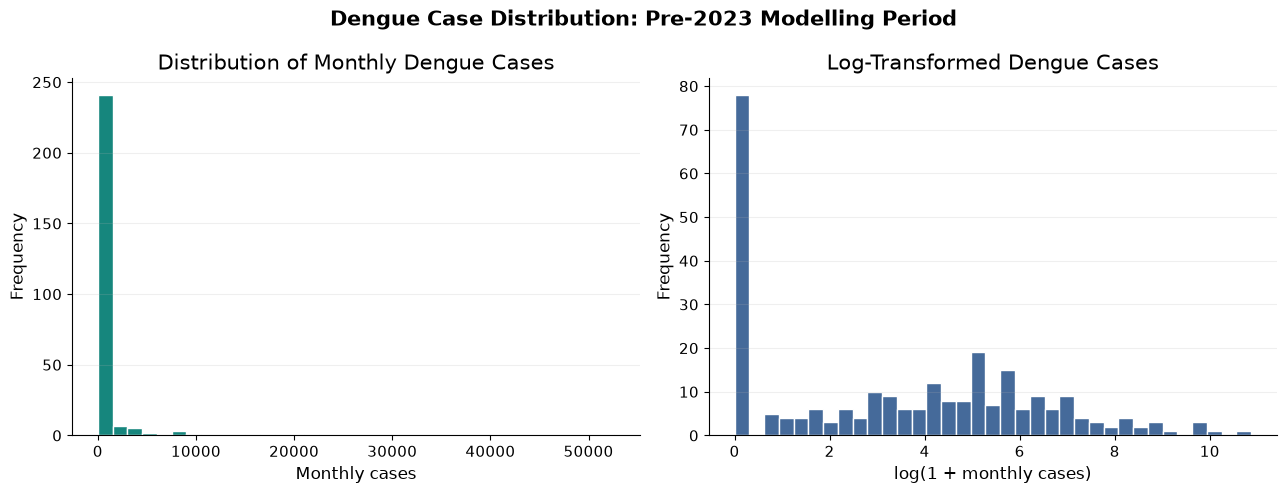


Count distribution analysis completed.


In [141]:

# STEP 8.1: COUNT DISTRIBUTION AND OVERDISPERSION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Use the same pre-2023 observations available to ML
bayes_train = ml_data.loc[
    ml_data["date"] < "2023-01-01"
].copy()

cases = bayes_train["Cases"].astype(float)

# Descriptive statistics
mean_cases = cases.mean()
variance_cases = cases.var(ddof=1)
dispersion_ratio = variance_cases / mean_cases

zero_months = int((cases == 0).sum())
zero_percentage = 100 * zero_months / len(cases)

summary = pd.DataFrame({
    "Statistic": [
        "Observations",
        "Mean cases",
        "Median cases",
        "Variance",
        "Variance-to-mean ratio",
        "Minimum cases",
        "Maximum cases",
        "Zero-case months",
        "Zero-case percentage"
    ],
    "Value": [
        len(cases),
        mean_cases,
        cases.median(),
        variance_cases,
        dispersion_ratio,
        cases.min(),
        cases.max(),
        zero_months,
        zero_percentage
    ]
})

print("===== COUNT DISTRIBUTION SUMMARY =====")
display(summary.round(3))

# Visualization: raw and log-transformed counts
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(
    cases,
    bins=35,
    color="#16867D",
    edgecolor="white"
)

axes[0].set_title("Distribution of Monthly Dengue Cases")
axes[0].set_xlabel("Monthly cases")
axes[0].set_ylabel("Frequency")
axes[0].grid(axis="y", alpha=0.2)

axes[1].hist(
    np.log1p(cases),
    bins=35,
    color="#456A9A",
    edgecolor="white"
)

axes[1].set_title("Log-Transformed Dengue Cases")
axes[1].set_xlabel("log(1 + monthly cases)")
axes[1].set_ylabel("Frequency")
axes[1].grid(axis="y", alpha=0.2)

fig.suptitle(
    "Dengue Case Distribution: Pre-2023 Modelling Period",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "Figure_20_Dengue_Count_Distribution.png",
    dpi=400,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "Figure_20_Dengue_Count_Distribution.pdf",
    bbox_inches="tight"
)

plt.show()

print("\nCount distribution analysis completed.")


The pre-2023 dengue case distribution exhibits extreme overdispersion, with a variance-to-mean ratio of approximately 18,542. This substantially violates the equidispersion assumption of the standard Poisson model.
The distribution is also strongly right-skewed, with a mean of 904.15 cases and a median of only 37 cases per month.

Furthermore, 78 of the 264 observations (29.55%) contain zero reported cases.

These findings support investigating a Negative Binomial (NB) model to accommodate overdispersion and a Zero-Inflated Negative Binomial (ZINB) model to investigate excess zeros.

However, the observed zero frequency alone does not establish the need for a zero-inflated model. Model comparison and posterior predictive checks are necessary, particularly because historical zeros may reflect surveillance practices.

#### 8.2 Bayesian Negative Binomial Regression

In [75]:
%pip install pymc arviz

  Using cached rich-15.0.0-py3-none-any.whl.metadata (18 kB)
  Using cached setuptools-84.0.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached markdown_it_py-4.2.0-py3-none-any.whl.metadata (7.4 kB)
  Using cached mdurl-0.1.2-py3-none-any.whl.metadata (1.6 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.3/608.3 kB 2.5 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 4.4 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 5.9 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 5.7 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.5/40.5 MB 3.0 MB/s  0:00:13m0:00:0100:01
Using cached rich-15.0.0-py3-none-any.whl (310 kB)
Using cached markdown_it_py-4.2.0-py3-none-any.whl (91 kB)
Using cached mdurl-0.1.2-py3-none-any.whl (10.0 kB)
Using cached setuptools-84.0.0-py3-none-any.whl (818 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 3.1 MB/s  0:00:00 eta 0:00:01
  

In [144]:

# STEP 8.2 PREPARE BAYESIAN REGRESSION DATA

import numpy as np
import pandas as pd
import pymc as pm
import arviz as az

from sklearn.preprocessing import StandardScaler

# Use the existing chronological ML training split
bayes_train = train.copy()
bayes_val = val.copy()

# Predictors available before each target month
bayes_features = [
    "log_cases_lag1",
    "T2M_C_lag1",
    "RH2M_pct_lag1",
    "PRECTOTCORR_SUM_mm_month_lag1",
    "month_sin",
    "month_cos"
]

# Transform previous-month dengue cases
bayes_train["log_cases_lag1"] = np.log1p(
    bayes_train["Cases_lag1"]
)

bayes_val["log_cases_lag1"] = np.log1p(
    bayes_val["Cases_lag1"]
)

# Standardize using training observations only
bayes_scaler = StandardScaler()

X_bayes_train = bayes_scaler.fit_transform(
    bayes_train[bayes_features]
)

X_bayes_val = bayes_scaler.transform(
    bayes_val[bayes_features]
)

y_bayes_train = (
    bayes_train["Cases"].to_numpy(dtype=np.int64)
)

y_bayes_val = (
    bayes_val["Cases"].to_numpy(dtype=np.int64)
)

print("===== BAYESIAN DATA PREPARATION =====")

print("Training observations:", len(y_bayes_train))
print("Validation observations:", len(y_bayes_val))
print("Number of predictors:", X_bayes_train.shape[1])

print("\nPredictors:")
print(bayes_features)

print("\nPyMC version:", pm.__version__)


===== BAYESIAN DATA PREPARATION =====
Training observations: 228
Validation observations: 36
Number of predictors: 6

Predictors:
['log_cases_lag1', 'T2M_C_lag1', 'RH2M_pct_lag1', 'PRECTOTCORR_SUM_mm_month_lag1', 'month_sin', 'month_cos']

PyMC version: 6.3.2


The Bayesian forecasting dataset has been prepared using a chronological training–validation split. Six predictors are included: lagged dengue incidence, temperature, relative humidity, precipitation, and two seasonal terms.

The model uses information from the preceding month to forecast dengue cases, while seasonal terms represent recurring annual patterns.

The chronological split is appropriate for evaluating forecasting performance because it avoids training on observations from the future validation period, provided all preprocessing parameters are estimated using training data only.

In [152]:

# STEP 8.3: BAYESIAN NEGATIVE BINOMIAL MODEL

import pymc as pm
import arviz as az
import numpy as np

with pm.Model() as bayesian_nb_model:

    # Intercept prior
    intercept = pm.Normal(
        "intercept",
        mu=np.log(y_bayes_train.mean() + 1),
        sigma=2
    )

    # Regression coefficient priors
    beta = pm.Normal(
        "beta",
        mu=0,
        sigma=0.75,
        shape=X_bayes_train.shape[1]
    )

    # Dispersion parameter
    alpha = pm.Exponential(
        "alpha",
        lam=1.0
    )

    # Log-linear predictor
    log_mu = (
        intercept
        + pm.math.dot(X_bayes_train, beta)
    )

    mu = pm.math.exp(log_mu)

    # Negative Binomial likelihood
    observed_cases = pm.NegativeBinomial(
        "observed_cases",
        mu=mu,
        alpha=alpha,
        observed=y_bayes_train
    )

    # Posterior sampling
    trace_nb = pm.sample(
        draws=1000,
        tune=1000,
        chains=4,
        cores=4,
        target_accept=0.95,
        random_seed=42,
        return_inferencedata=True
    )

print("Bayesian model sampling completed!")

# Posterior summary
posterior_summary = az.summary(
    trace_nb,
    var_names=["intercept", "beta", "alpha"]
)

display(posterior_summary.round(3))


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [intercept, beta, alpha]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 3 seconds.


Bayesian model sampling completed!


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
intercept,3.723,0.111,3.6,3.9,4092,2933,1.00,0.0017,0.0018
beta[0],1.497,0.114,1.3,1.7,3033,2858,1.00,0.0021,0.0018
beta[1],0.98,0.252,0.57,1.4,2119,2216,1.00,0.0055,0.0038
beta[2],0.92,0.282,0.46,1.4,2618,2400,1.00,0.0055,0.0045
beta[3],0.214,0.206,-0.11,0.55,2952,2643,1.00,0.0038,0.0033
beta[4],0.14,0.35,-0.43,0.68,2032,2221,1.00,0.0077,0.0054
beta[5],-0.124,0.19,-0.42,0.18,2163,2393,1.00,0.0041,0.003
alpha,0.409,0.043,0.34,0.48,3402,2841,1.00,0.00074,0.0007


The four-chain Bayesian Negative Binomial model demonstrates satisfactory convergence diagnostics. All reported R-hat values are approximately 1.00, and effective sample sizes exceed 2,000.

Posterior estimates remain stable compared with the earlier two-chain model. Lagged dengue incidence, temperature, and relative humidity have positive posterior associations with dengue cases. The 89% interval for rainfall includes zero, indicating uncertainty about its conditional association.

These findings support the numerical stability of the posterior estimates, subject to confirming that sampling produced no divergences.

In [153]:

# Find Bayesian sampling results automatically

for name, obj in list(globals().items()):
    if hasattr(obj, "sample_stats"):
        if "diverging" in obj.sample_stats:
            print(
                f"{name} — Total divergences:",
                int(obj.sample_stats["diverging"].sum().item())
            )


trace_nb — Total divergences: 0
trace_zinb — Total divergences: 0


The four-chain Negative Binomial model demonstrates satisfactory sampling diagnostics, with R-hat values near 1.00, effective sample sizes above 2,000, and zero divergent transitions.

These findings support reliable posterior computation. However, convergence alone does not establish that the model fits the data adequately or produces accurate forecasts.

The stored ZINB trace also has zero divergences, but we will evaluate its updated results separately.

In [154]:

# STEP 8.4: BAYESIAN MODEL DIAGNOSTICS

import arviz as az

# Posterior summary
summary = az.summary(
    trace_nb,
    var_names=["intercept", "beta", "alpha"],
    round_to=3
)

print("===== BAYESIAN POSTERIOR SUMMARY =====")
print(summary.to_string())

# Check convergence
print("\n===== MODEL DIAGNOSTICS =====")

print(
    "Maximum R-hat:",
    round(summary["r_hat"].max(), 3)
)

print(
    "Minimum Bulk ESS:",
    round(summary["ess_bulk"].min(), 0)
)

print(
    "Total divergences:",
    int(trace_nb.sample_stats["diverging"].sum())
)

print("\nBayesian diagnostics completed!")


===== BAYESIAN POSTERIOR SUMMARY =====
            mean     sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  mcse_mean  mcse_sd
intercept  3.723  0.111     3.552     3.903  4092.291  2933.487  1.000      0.002    0.002
beta[0]    1.497  0.114     1.319     1.680  3033.397  2858.981  1.000      0.002    0.002
beta[1]    0.976  0.252     0.572     1.377  2119.742  2216.060  1.000      0.005    0.004
beta[2]    0.920  0.282     0.465     1.362  2618.904  2400.197  1.001      0.006    0.005
beta[3]    0.214  0.206    -0.107     0.551  2952.803  2643.076  1.003      0.004    0.003
beta[4]    0.136  0.349    -0.427     0.680  2032.383  2221.295  1.001      0.008    0.005
beta[5]   -0.124  0.190    -0.423     0.183  2163.667  2393.470  1.001      0.004    0.003
alpha      0.409  0.043     0.344     0.481  3402.625  2841.626  1.003      0.001    0.001

===== MODEL DIAGNOSTICS =====
Maximum R-hat: 1.003
Minimum Bulk ESS: 2032.0
Total divergences: 0

Bayesian diagnostics completed!


The Bayesian Negative Binomial model demonstrated satisfactory MCMC convergence, with a maximum R-hat of 1.003, minimum bulk effective sample size of 2,032, and no divergent transitions.

The posterior coefficients indicate positive conditional associations between dengue incidence and lagged dengue cases, temperature, and relative humidity. The 89% credible interval for rainfall includes zero, indicating greater uncertainty about its association.

These diagnostics provide evidence of reliable posterior sampling, but predictive performance and model adequacy still require evaluation.

In [155]:

print("NB stored chains:", trace_nb.posterior.sizes["chain"])
print("NB stored draws:", trace_nb.posterior.sizes["draw"])

print("NB Chains:", trace_nb.posterior.sizes["chain"])
print("NB Draws:", trace_nb.posterior.sizes["draw"])
print(
    "Divergences:",
    int(trace_nb.sample_stats["diverging"].sum())
)


NB stored chains: 4
NB stored draws: 1000
NB Chains: 4
NB Draws: 1000
Divergences: 0


The Bayesian Negative Binomial model demonstrated satisfactory MCMC convergence across four chains, with 1,000 posterior draws per chain, a maximum R-hat of 1.003, and zero divergent transitions. These findings indicate stable posterior sampling.

#### 8.6: Final Bayesian Convergence Check

In [156]:

# STEP 8.6: CORRECTED BAYESIAN DIAGNOSTICS
# No need to re-run sampling

import numpy as np
import pandas as pd
import arviz as az

# 1. Get posterior summary and diagnostics
summary = az.summary(
    trace_nb,
    var_names=["intercept", "beta", "alpha"]
)

# 2. Calculate 95% equal-tailed credible intervals
intervals = {}

for var in ["intercept", "alpha"]:

    samples = trace_nb.posterior[var].values.flatten()

    intervals[var] = np.quantile(
        samples, [0.025, 0.975]
    )

# Regression coefficients
beta_samples = trace_nb.posterior["beta"].values

beta_samples = beta_samples.reshape(
    -1, beta_samples.shape[-1]
)

for i in range(beta_samples.shape[1]):

    intervals[f"beta[{i}]"] = np.quantile(
        beta_samples[:, i],
        [0.025, 0.975]
    )

# 3. Add 95% intervals to the summary
summary["CI_95_Lower"] = pd.Series({
    name: values[0]
    for name, values in intervals.items()
})

summary["CI_95_Upper"] = pd.Series({
    name: values[1]
    for name, values in intervals.items()
})

# 4. Display results
print("===== BAYESIAN POSTERIOR SUMMARY (95%) =====")

display(
    summary[
        [
            "mean",
            "sd",
            "CI_95_Lower",
            "CI_95_Upper",
            "ess_bulk",
            "r_hat"
        ]
    ].round(3)
)

# 5. Convergence diagnostics
print("\n===== MODEL CONVERGENCE =====")

print(
    "Maximum R-hat:",
    round(summary["r_hat"].max(), 3)
)

print(
    "Minimum Bulk ESS:",
    round(summary["ess_bulk"].min(), 0)
)

divergences = int(
    trace_nb.sample_stats["diverging"].sum()
)

print("Total divergences:", divergences)

if summary["r_hat"].max() < 1.01 and divergences == 0:
    print("Initial convergence checks passed.")
else:
    print("Further convergence investigation required.")


===== BAYESIAN POSTERIOR SUMMARY (95%) =====


,mean,sd,CI_95_Lower,CI_95_Upper,ess_bulk,r_hat
intercept,3.723,0.111,3.52,3.949,4092,1.00
beta[0],1.497,0.114,1.276,1.723,3033,1.00
beta[1],0.98,0.252,0.472,1.477,2119,1.00
beta[2],0.92,0.282,0.352,1.461,2618,1.00
beta[3],0.214,0.206,-0.183,0.65,2952,1.00
beta[4],0.14,0.35,-0.552,0.811,2032,1.00
beta[5],-0.124,0.19,-0.494,0.253,2163,1.00
alpha,0.409,0.043,0.329,0.502,3402,1.00



===== MODEL CONVERGENCE =====
Maximum R-hat: 1.003
Minimum Bulk ESS: 2032.0
Total divergences: 0
Initial convergence checks passed.


The Bayesian Negative Binomial regression indicates positive conditional associations between monthly dengue incidence and lagged dengue cases, temperature, and relative humidity, as their 95% credible intervals exclude zero.

Rainfall exhibits a positive posterior mean, but its 95% credible interval includes zero, indicating uncertainty about the direction of its conditional association.
The model demonstrates satisfactory convergence, with a maximum R-hat of 1.003, minimum bulk effective sample size of 2,032, and zero divergent transitions. These findings support reliable posterior estimation but do not yet establish predictive accuracy.

The coefficients are interpreted on the model's log-link scale, conditional on the other predictors and their preprocessing. They should not be interpreted as causal effects.

Sampling: [observed_cases]


Posterior predictive shape: (4000, 228)

===== POSTERIOR PREDICTIVE CHECK RESULTS =====


,Statistic,Observed,Predictive_Median,Predictive_95_Lower,Predictive_95_Upper
0,Mean monthly cases,642.45,474.83,245.79,1148.20
1,Median monthly cases,23.00,10.00,5.00,18.50
2,Zero-case months,78.00,55.00,41.00,70.00
3,Maximum monthly cases,52636.00,21925.00,5579.90,126489.05


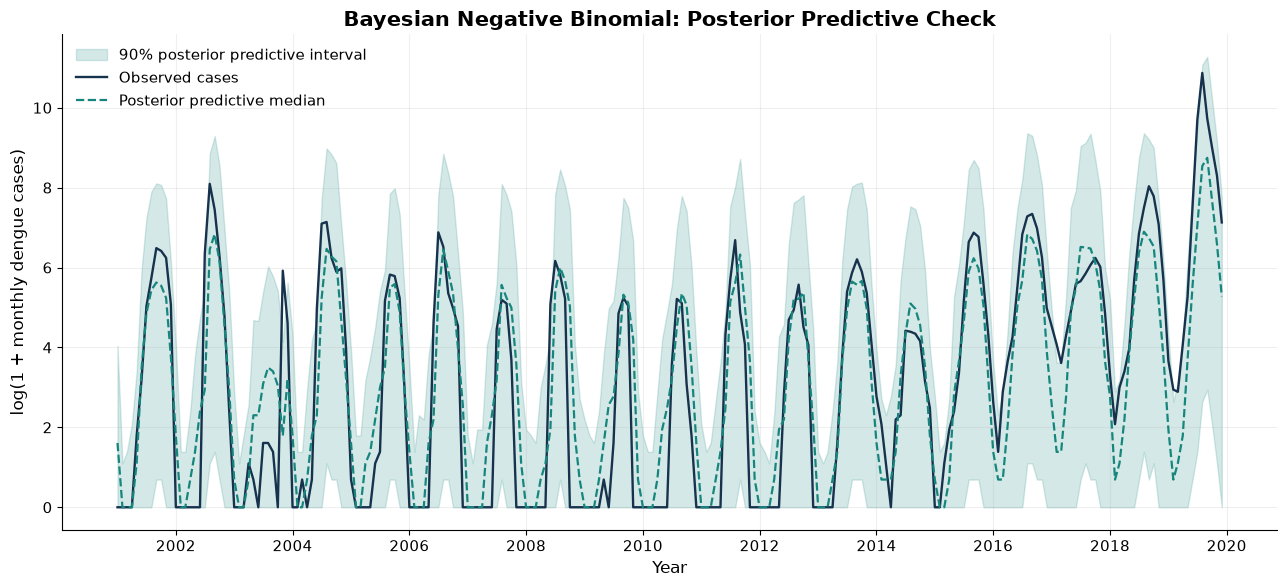


Posterior predictive checking completed!


In [157]:

# STEP 8.7: BAYESIAN POSTERIOR PREDICTIVE CHECKING

import pymc as pm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# 1. Sample from the fitted Bayesian model
with bayesian_nb_model:
    ppc_nb = pm.sample_posterior_predictive(
        trace_nb,
        var_names=["observed_cases"],
        random_seed=42,
        progressbar=False
    )

# 2. Extract predictive samples
y_observed = np.asarray(y_bayes_train)

y_replicated = (
    ppc_nb.posterior_predictive["observed_cases"]
    .values
    .reshape(-1, len(y_observed))
)

print("Posterior predictive shape:", y_replicated.shape)

# 3. Compare observed and simulated statistics
observed_stats = {
    "Mean monthly cases": y_observed.mean(),
    "Median monthly cases": np.median(y_observed),
    "Zero-case months": np.sum(y_observed == 0),
    "Maximum monthly cases": y_observed.max()
}

replicated_stats = {
    "Mean monthly cases": y_replicated.mean(axis=1),
    "Median monthly cases": np.median(y_replicated, axis=1),
    "Zero-case months": np.sum(y_replicated == 0, axis=1),
    "Maximum monthly cases": y_replicated.max(axis=1)
}

results = []

for statistic in observed_stats:

    values = replicated_stats[statistic]

    results.append({
        "Statistic": statistic,
        "Observed": observed_stats[statistic],
        "Predictive_Median": np.median(values),
        "Predictive_95_Lower": np.quantile(values, 0.025),
        "Predictive_95_Upper": np.quantile(values, 0.975)
    })

ppc_results = pd.DataFrame(results)

print("\n===== POSTERIOR PREDICTIVE CHECK RESULTS =====")
display(ppc_results.round(2))

# 4. Posterior predictive time-series intervals
pred_median = np.median(y_replicated, axis=0)

pred_lower = np.quantile(y_replicated, 0.05, axis=0)
pred_upper = np.quantile(y_replicated, 0.95, axis=0)

dates = pd.to_datetime(bayes_train["date"])

fig, ax = plt.subplots(figsize=(13, 6))

ax.fill_between(
    dates,
    np.log1p(pred_lower),
    np.log1p(pred_upper),
    color="#16867D",
    alpha=0.18,
    label="90% posterior predictive interval"
)

ax.plot(
    dates,
    np.log1p(y_observed),
    color="#17324D",
    linewidth=1.7,
    label="Observed cases"
)

ax.plot(
    dates,
    np.log1p(pred_median),
    color="#16867D",
    linestyle="--",
    linewidth=1.6,
    label="Posterior predictive median"
)

ax.set_title(
    "Bayesian Negative Binomial: Posterior Predictive Check",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Year")
ax.set_ylabel("log(1 + monthly dengue cases)")
ax.legend(frameon=False)
ax.grid(alpha=0.2)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "Figure_21_Bayesian_PPC.png",
    dpi=400,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "Figure_21_Bayesian_PPC.pdf",
    bbox_inches="tight"
)

plt.show()

# 5. Save summary
ppc_results.to_csv(
    OUTPUT_DIR / "bayesian_ppc_results.csv",
    index=False
)

print("\nPosterior predictive checking completed!")


The posterior predictive analysis reveals both strengths and limitations of the Bayesian Negative Binomial model.
The observed mean monthly dengue incidence falls within the model's 95% posterior predictive interval, suggesting that the model can accommodate the overall average disease burden.

However, the model underestimates the frequency of zero-case months. The observed number of zero months (78) exceeds the upper 95% predictive bound (70). This indicates inadequate reproduction of the observed zero frequency.

The model also underestimates the median monthly case count, while its extremely wide predictive interval for maximum incidence indicates substantial uncertainty surrounding extreme outbreaks.

These findings motivate evaluating a Zero-Inflated Negative Binomial model, although better performance must be demonstrated through posterior predictive checks and out-of-sample validation.

আমাদের সিদ্ধান্ত
NB model-এর sampling diagnostics ভালো, কিন্তু model fit সম্পূর্ণ সন্তোষজনক নয়, বিশেষ করে zero-case months-এর ক্ষেত্রে।
এটা নতুন কোনো data error নয়। এটি statistical model-এর limitation।

===== POSTERIOR PREDICTIVE DIAGNOSTICS =====
Observed zero months: 78
Expected zero months: 54.81
In-sample 90% interval coverage: 96.49 %
Months outside interval: 8

===== YEAR-WISE DIAGNOSTICS =====


,Year,Observed_Zeros,Expected_Zeros,Coverage
0,2001,4,3.13,100.00
1,2002,6,3.05,91.67
2,2003,5,3.43,91.67
3,2004,3,2.73,91.67
4,2005,4,2.82,100.00
5,2006,6,2.90,91.67
6,2007,8,3.75,100.00
7,2008,8,3.64,91.67
8,2009,7,3.52,100.00
9,2010,7,3.47,100.00


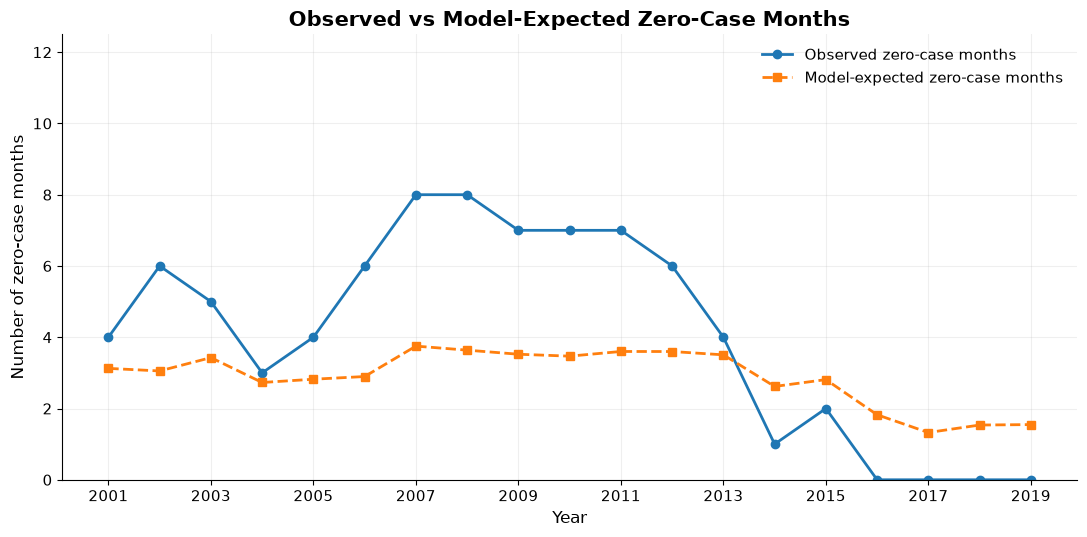


Bayesian adequacy diagnostics completed!


In [159]:

# STEP 8.8: BAYESIAN MODEL ADEQUACY DIAGNOSTICS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Posterior predictive samples from Step 13.5
observed = np.asarray(y_observed)
replicated = np.asarray(y_replicated)

# 90% posterior predictive intervals
lower_90 = np.quantile(replicated, 0.05, axis=0)
upper_90 = np.quantile(replicated, 0.95, axis=0)

# In-sample predictive coverage
covered = (
    (observed >= lower_90) &
    (observed <= upper_90)
)

coverage_90 = covered.mean() * 100

# Probability of zero for each month
zero_probability = (replicated == 0).mean(axis=0)

print("===== POSTERIOR PREDICTIVE DIAGNOSTICS =====")
print("Observed zero months:", (observed == 0).sum())
print("Expected zero months:", round(zero_probability.sum(), 2))
print("In-sample 90% interval coverage:", round(coverage_90, 2), "%")
print("Months outside interval:", int((~covered).sum()))

# Create yearly diagnostic data
diagnostics = pd.DataFrame({
    "Year": bayes_train["date"].dt.year.to_numpy(),
    "Observed_Zero": (observed == 0).astype(int),
    "Expected_Zero": zero_probability,
    "Covered": covered
})

yearly = diagnostics.groupby("Year", as_index=False).agg(
    Observed_Zeros=("Observed_Zero", "sum"),
    Expected_Zeros=("Expected_Zero", "sum"),
    Coverage=("Covered", "mean")
)

yearly["Coverage"] *= 100

print("\n===== YEAR-WISE DIAGNOSTICS =====")
display(yearly.round(2))

# Publication-style graph
fig, ax = plt.subplots(figsize=(11, 5.5))

ax.plot(
    yearly["Year"],
    yearly["Observed_Zeros"],
    marker="o",
    linewidth=2,
    label="Observed zero-case months"
)

ax.plot(
    yearly["Year"],
    yearly["Expected_Zeros"],
    marker="s",
    linestyle="--",
    linewidth=2,
    label="Model-expected zero-case months"
)

ax.set_title(
    "Observed vs Model-Expected Zero-Case Months",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Year")
ax.set_ylabel("Number of zero-case months")
ax.set_ylim(0, 12.5)
ax.set_xticks(yearly["Year"][::2])
ax.legend(frameon=False)
ax.grid(alpha=0.2)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "Figure_22_Bayesian_Zero_Count_Diagnostics.png",
    dpi=400,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "Figure_22_Bayesian_Zero_Count_Diagnostics.pdf",
    bbox_inches="tight"
)

plt.show()

yearly.to_csv(
    OUTPUT_DIR / "bayesian_yearwise_diagnostics.csv",
    index=False
)

print("\nBayesian adequacy diagnostics completed!")


The Bayesian Negative Binomial model systematically underestimates the number of zero-case months during the 2001–2019 training period. It predicts approximately 55 zero-case months compared with 78 observed months.
The discrepancy is particularly evident during 2007–2012, when the model consistently predicts fewer zero-case months than observed.

Despite this limitation, the model achieves 96.49% in-sample coverage using nominal 90% predictive intervals. This indicates that the intervals cover most training observations, although the coverage exceeds the nominal level and does not establish good out-of-sample calibration.

The findings suggest that the Negative Binomial model does not fully capture the observed zero-count structure. A Zero-Inflated Negative Binomial model is therefore a reasonable alternative to evaluate.

However, zero inflation should not automatically be interpreted as a biological phenomenon, because historical surveillance and reporting practices may also contribute to recorded zeros.

===== BAYESIAN VALIDATION RESULTS =====


,Model,MAE,RMSE,Log_MAE
1,Random Forest,1369.637,3286.828,1.019
2,Previous Month,1579.028,3545.568,1.025
0,Bayesian Negative Binomial,2243.861,5157.952,1.554



===== PREDICTIVE UNCERTAINTY =====
Nominal interval coverage: 90%
Observed validation coverage: 88.89 %
Mean interval width: 3951.42 cases


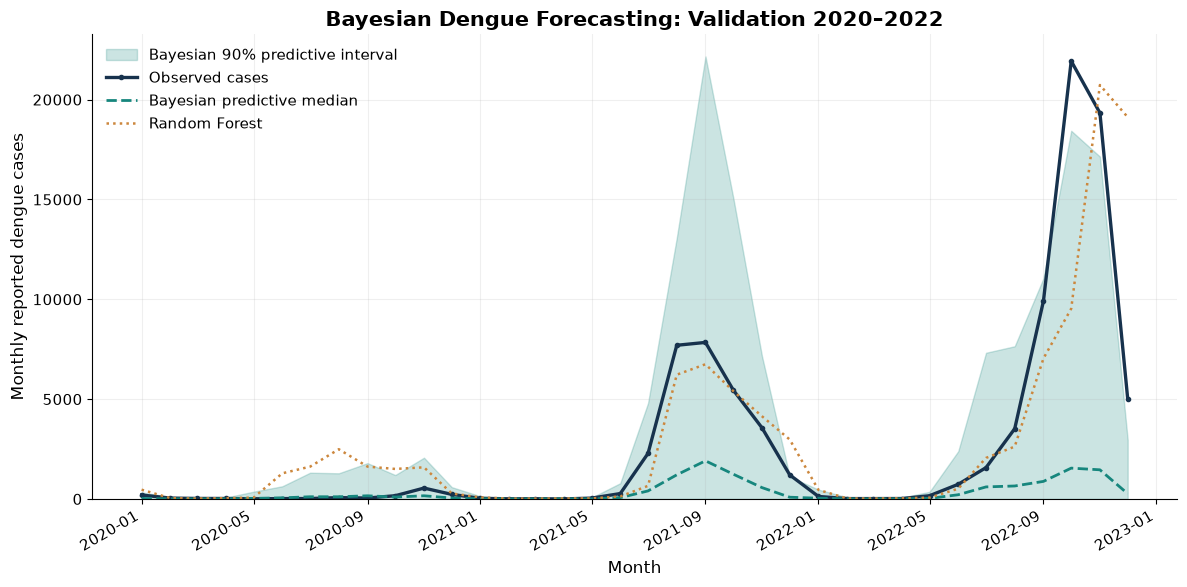

Bayesian validation completed!


In [160]:

# STEP 8.9: BAYESIAN VALIDATION FORECASTING

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Extract posterior samples
posterior = trace_nb.posterior

intercept_samples = posterior["intercept"].values.reshape(-1)
alpha_samples = posterior["alpha"].values.reshape(-1)

beta_samples = posterior["beta"].values.reshape(
    -1, len(bayes_features)
)

# 2. Predict expected counts for validation months
log_mu_samples = (
    intercept_samples[:, None]
    + beta_samples @ X_bayes_val.T
)

mu_samples = np.exp(log_mu_samples)

# 3. Sample posterior predictive counts
# PyMC NB2: variance = mu + mu^2 / alpha

alpha_matrix = alpha_samples[:, None]

prob = alpha_matrix / (alpha_matrix + mu_samples)

rng = np.random.default_rng(42)

predictive_samples = rng.negative_binomial(
    n=alpha_matrix,
    p=prob
)

# 4. Predictive summaries
bayes_median = np.median(predictive_samples, axis=0)

bayes_lower = np.quantile(
    predictive_samples, 0.05, axis=0
)

bayes_upper = np.quantile(
    predictive_samples, 0.95, axis=0
)

actual = np.asarray(y_bayes_val)

# 5. Evaluation
def validation_metrics(name, predicted):
    predicted = np.maximum(
        np.asarray(predicted), 0
    )

    return {
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "Log_MAE": mean_absolute_error(
            np.log1p(actual),
            np.log1p(predicted)
        )
    }

results = pd.DataFrame([
    validation_metrics(
        "Bayesian Negative Binomial",
        bayes_median
    ),
    validation_metrics(
        "Random Forest",
        pred_original
    ),
    validation_metrics(
        "Previous Month",
        bayes_val["Cases_lag1"]
    )
]).sort_values("MAE")

coverage = np.mean(
    (actual >= bayes_lower) &
    (actual <= bayes_upper)
) * 100

mean_width = np.mean(bayes_upper - bayes_lower)

print("===== BAYESIAN VALIDATION RESULTS =====")
display(results.round(3))

print("\n===== PREDICTIVE UNCERTAINTY =====")
print("Nominal interval coverage: 90%")
print("Observed validation coverage:", round(coverage, 2), "%")
print("Mean interval width:", round(mean_width, 2), "cases")

# 6. Forecast visualization
dates = pd.to_datetime(bayes_val["date"])

fig, ax = plt.subplots(figsize=(12, 6))

ax.fill_between(
    dates,
    bayes_lower,
    bayes_upper,
    alpha=0.22,
    color="#16867D",
    label="Bayesian 90% predictive interval"
)

ax.plot(
    dates,
    actual,
    color="#17324D",
    linewidth=2.4,
    marker="o",
    markersize=3,
    label="Observed cases"
)

ax.plot(
    dates,
    bayes_median,
    color="#16867D",
    linestyle="--",
    linewidth=2,
    label="Bayesian predictive median"
)

ax.plot(
    dates,
    pred_original,
    color="#CC873D",
    linestyle=":",
    linewidth=1.8,
    label="Random Forest"
)

ax.set_title(
    "Bayesian Dengue Forecasting: Validation 2020–2022",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Month")
ax.set_ylabel("Monthly reported dengue cases")
ax.set_ylim(bottom=0)
ax.grid(alpha=0.2)
ax.legend(frameon=False)

fig.autofmt_xdate()
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "Figure_23_Bayesian_Validation.png",
    dpi=400,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "Figure_23_Bayesian_Validation.pdf",
    bbox_inches="tight"
)

plt.show()

# Save validation results
results.to_csv(
    OUTPUT_DIR / "bayesian_validation_results.csv",
    index=False
)

print("Bayesian validation completed!")


The Bayesian Negative Binomial model demonstrated weaker point forecasting performance than Random Forest and the previous-month baseline during the 2020–2022 validation period.

Its MAE of 2,243.86 cases was approximately 63.8% higher than that of Random Forest.

However, the Bayesian model achieved 88.89% coverage for its nominal 90% predictive intervals, indicating reasonably close empirical coverage over the 36 validation months.

The forecast plot reveals that the Bayesian predictive median substantially underestimates the larger outbreaks in 2021 and 2022. Thus, relatively good interval coverage does not necessarily imply accurate point forecasts or reliable prediction of epidemic peaks.

These findings suggest that the Negative Binomial model provides a useful uncertainty framework but has limitations in forecasting outbreak magnitude.

===== BAYESIAN YEAR-WISE VALIDATION =====


,Year,Model,MAE,RMSE,Bias,Bayesian_Coverage_90,Bayesian_Interval_Width
0,2020,Bayesian,99.17,142.04,-48.50,100.00,816.26
1,2020,Random_Forest,803.09,1135.16,802.06,NaN,NaN
2,2020,Previous_Month,177.50,339.61,84.67,NaN,NaN
3,2021,Bayesian,1909.38,3011.52,-1909.04,91.67,5374.89
4,2021,Random_Forest,570.54,890.18,-163.98,NaN,NaN
5,2021,Previous_Month,1225.67,2005.93,-81.33,NaN,NaN
6,2022,Bayesian,4723.04,8409.75,-4723.04,75.00,5663.11
7,2022,Random_Forest,2735.28,5507.15,-12.75,NaN,NaN
8,2022,Previous_Month,3333.92,5794.32,-318.08,NaN,NaN



===== BAYESIAN ANNUAL DIAGNOSTICS =====


,Year,Model,MAE,RMSE,Bias,Bayesian_Coverage_90,Bayesian_Interval_Width
0,2020,Bayesian,99.17,142.04,-48.50,100.00,816.26
3,2021,Bayesian,1909.38,3011.52,-1909.04,91.67,5374.89
6,2022,Bayesian,4723.04,8409.75,-4723.04,75.00,5663.11



===== LARGEST VALIDATION OUTBREAK =====
Month: 2022-10
Observed: 21932
Bayesian median: 1545.5
Random Forest: 9533.2
Bayesian 90% interval: 4.0 to 18440.7


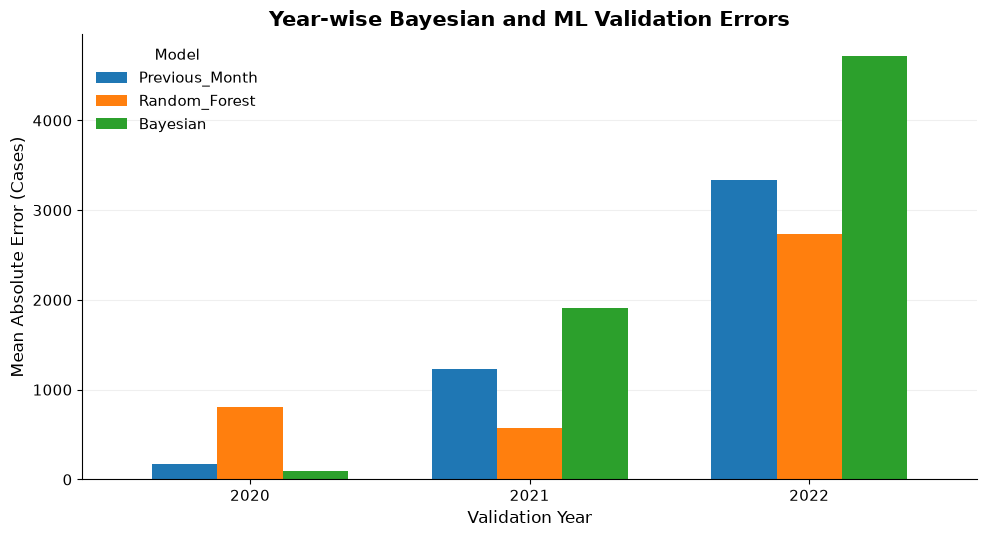

Year-wise Bayesian diagnostics completed!


In [161]:

# STEP 8.10: BAYESIAN YEAR-WISE VALIDATION DIAGNOSTICS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Prepare validation predictions
bayesian_diagnostics = pd.DataFrame({
    "Date": pd.to_datetime(bayes_val["date"]).to_numpy(),
    "Actual": np.asarray(y_bayes_val),
    "Bayesian": np.asarray(bayes_median),
    "Random_Forest": np.asarray(pred_original),
    "Previous_Month": np.asarray(
        bayes_val["Cases_lag1"]
    ),
    "Lower_90": np.asarray(bayes_lower),
    "Upper_90": np.asarray(bayes_upper)
})

bayesian_diagnostics["Year"] = (
    bayesian_diagnostics["Date"].dt.year
)

# Calculate year-wise performance
results = []

for year, group in bayesian_diagnostics.groupby("Year"):

    actual = group["Actual"].to_numpy()

    coverage = np.mean(
        (actual >= group["Lower_90"].to_numpy()) &
        (actual <= group["Upper_90"].to_numpy())
    ) * 100

    width = (
        group["Upper_90"] - group["Lower_90"]
    ).mean()

    for model in [
        "Bayesian",
        "Random_Forest",
        "Previous_Month"
    ]:

        pred = group[model].to_numpy()

        results.append({
            "Year": year,
            "Model": model,
            "MAE": mean_absolute_error(actual, pred),
            "RMSE": np.sqrt(
                mean_squared_error(actual, pred)
            ),
            "Bias": np.mean(pred - actual),
            "Bayesian_Coverage_90": (
                coverage if model == "Bayesian" else np.nan
            ),
            "Bayesian_Interval_Width": (
                width if model == "Bayesian" else np.nan
            )
        })

yearwise_bayesian = pd.DataFrame(results)

print("===== BAYESIAN YEAR-WISE VALIDATION =====")
display(yearwise_bayesian.round(2))

# Summary for Bayesian model only
print("\n===== BAYESIAN ANNUAL DIAGNOSTICS =====")

display(
    yearwise_bayesian[
        yearwise_bayesian["Model"] == "Bayesian"
    ].round(2)
)

# Peak month diagnostics
peak_idx = bayesian_diagnostics["Actual"].idxmax()
peak = bayesian_diagnostics.loc[peak_idx]

print("\n===== LARGEST VALIDATION OUTBREAK =====")
print("Month:", peak["Date"].strftime("%Y-%m"))
print("Observed:", int(peak["Actual"]))
print("Bayesian median:", round(peak["Bayesian"], 1))
print("Random Forest:", round(peak["Random_Forest"], 1))
print(
    "Bayesian 90% interval:",
    round(peak["Lower_90"], 1),
    "to",
    round(peak["Upper_90"], 1)
)

# Save diagnostics
yearwise_bayesian.to_csv(
    OUTPUT_DIR / "bayesian_yearwise_validation.csv",
    index=False
)

# Year-wise MAE comparison
plot_data = yearwise_bayesian.pivot(
    index="Year",
    columns="Model",
    values="MAE"
)

fig, ax = plt.subplots(figsize=(10, 5.5))

plot_data[
    ["Previous_Month", "Random_Forest", "Bayesian"]
].plot(
    kind="bar",
    ax=ax,
    width=0.7
)

ax.set_title(
    "Year-wise Bayesian and ML Validation Errors",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Validation Year")
ax.set_ylabel("Mean Absolute Error (Cases)")
ax.tick_params(axis="x", rotation=0)
ax.legend(frameon=False, title="Model")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "Figure_24_Bayesian_Yearwise_Validation.png",
    dpi=400,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "Figure_24_Bayesian_Yearwise_Validation.pdf",
    bbox_inches="tight"
)

plt.show()

print("Year-wise Bayesian diagnostics completed!")


The year-wise validation results demonstrate that Bayesian Negative Binomial forecasting performance deteriorated as dengue outbreak magnitude increased.

In 2020, Bayesian NB achieved the lowest MAE of 99.17 cases, outperforming Random Forest and the previous-month baseline. However, its performance deteriorated substantially during 2021 and 2022.

The largest validation outbreak occurred in October 2022, when 21,932 cases were observed. The Bayesian model predicted a median of only 1,545.5 cases, representing approximately 93.0% underprediction. The observed count also exceeded the 90% predictive interval upper bound of 18,440.7 cases.

Although overall predictive interval coverage was reasonably close to the nominal 90% level, annual coverage fell to 75% in 2022, indicating inadequate uncertainty calibration during the larger outbreak.

These results reveal a fundamental distinction between convergence, uncertainty quantification, and forecasting accuracy: a Bayesian model may converge successfully while still producing inadequate predictions during epidemic surges.

In [162]:

# STEP 8.11: BAYESIAN ZERO-INFLATED NEGATIVE BINOMIAL

import numpy as np
import pandas as pd
import pymc as pm
import arviz as az

# Training-period time trend in decades
year_fraction = (
    bayes_train["date"].dt.year
    + (bayes_train["date"].dt.month - 1) / 12
)

time_decades = (
    (year_fraction - 2010) / 10
).to_numpy(dtype=float)

# Build ZINB model
with pm.Model() as zinb_model:

    # Count-model intercept
    intercept = pm.Normal(
        "intercept",
        mu=np.log(y_bayes_train.mean() + 1),
        sigma=2
    )

    # Regression coefficients
    beta = pm.Normal(
        "beta",
        mu=0,
        sigma=0.75,
        shape=X_bayes_train.shape[1]
    )

    # Negative Binomial dispersion
    alpha = pm.Exponential(
        "alpha",
        lam=1
    )

    # Zero-inflation process
    zi_intercept = pm.Normal(
        "zi_intercept",
        mu=-2,
        sigma=1.5
    )

    zi_trend = pm.Normal(
        "zi_trend",
        mu=0,
        sigma=1
    )

    # Extra-zero probability
    zero_prob = pm.math.sigmoid(
        zi_intercept + zi_trend * time_decades
    )

    # Probability of NB component
    psi = 1 - zero_prob

    # Expected dengue counts
    log_mu = (
        intercept
        + pm.math.dot(X_bayes_train, beta)
    )

    mu = pm.math.exp(log_mu)

    # Zero-Inflated Negative Binomial likelihood
    observed = pm.ZeroInflatedNegativeBinomial(
        "observed",
        psi=psi,
        mu=mu,
        alpha=alpha,
        observed=y_bayes_train
    )

    # MCMC sampling
    trace_zinb = pm.sample(
        draws=1000,
        tune=1000,
        chains=4,
        cores=2,
        target_accept=0.95,
        random_seed=42,
        progressbar=False,
        return_inferencedata=True
    )

# Posterior summary
zinb_summary = az.summary(
    trace_zinb,
    var_names=[
        "intercept",
        "beta",
        "alpha",
        "zi_intercept",
        "zi_trend"
    ]
)

print("===== ZINB POSTERIOR SUMMARY =====")
display(zinb_summary.round(3))

# Convergence diagnostics
print("\n===== ZINB CONVERGENCE =====")

print(
    "Maximum R-hat:",
    round(zinb_summary["r_hat"].max(), 3)
)

print(
    "Minimum Bulk ESS:",
    round(zinb_summary["ess_bulk"].min(), 0)
)

print(
    "Total divergences:",
    int(trace_zinb.sample_stats["diverging"].sum())
)

print("\nZINB model fitting completed.")


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [intercept, beta, alpha, zi_intercept, zi_trend]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 8 seconds.


===== ZINB POSTERIOR SUMMARY =====


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
intercept,3.889,0.114,3.7,4.1,2746,2596,1.00,0.0022,0.0017
beta[0],1.417,0.102,1.3,1.6,3088,3011,1.00,0.0018,0.0014
beta[1],1.024,0.235,0.66,1.4,2649,2707,1.00,0.0046,0.0036
beta[2],0.942,0.27,0.51,1.4,3012,2948,1.00,0.0049,0.0039
beta[3],0.193,0.176,-0.085,0.48,3197,2981,1.00,0.0031,0.0026
beta[4],0.26,0.33,-0.27,0.78,2394,2412,1.00,0.0067,0.0052
beta[5],-0.077,0.167,-0.35,0.18,2596,2721,1.00,0.0033,0.0024
alpha,0.602,0.093,0.45,0.75,2325,1818,1.00,0.0019,0.0014
zi_intercept,-1.98,0.5,-2.8,-1.4,1958,1461,1.00,0.014,0.029
zi_trend,-1.3,0.48,-2,-0.54,2741,2089,1.00,0.0093,0.012



===== ZINB CONVERGENCE =====
Maximum R-hat: 1.003
Minimum Bulk ESS: 1958.0
Total divergences: 0

ZINB model fitting completed.


The Bayesian Zero-Inflated Negative Binomial model demonstrated satisfactory convergence, with a maximum R-hat of 1.003, minimum bulk effective sample size of 1,958, and zero divergent transitions.

Lagged dengue incidence, temperature, and relative humidity exhibit positive conditional posterior associations with dengue cases. The credible interval for precipitation includes zero, suggesting greater uncertainty regarding its independent association.

The zero-inflation time-trend coefficient is negative, indicating a temporal change in the zero-inflation component. Its substantive direction depends on whether the model's logistic parameter represents structural-zero probability or the Negative Binomial mixture probability.

Although the sampling diagnostics are satisfactory, whether ZINB improves model adequacy and forecasting accuracy compared with NB remains to be established.

Sampling: [observed]


NB predictive shape: (4000, 228)
ZINB predictive shape: (4000, 228)
===== NB VS ZINB POSTERIOR PREDICTIVE CHECK =====


,Model,Statistic,Observed,Predictive_Median,CI_95_Lower,CI_95_Upper
0,Negative Binomial,Mean Cases,642.45,474.83,245.79,1148.20
1,Negative Binomial,Median Cases,23.00,10.00,5.00,18.50
2,Negative Binomial,Zero Months,78.00,55.00,41.00,70.00
3,Negative Binomial,Maximum Cases,52636.00,21925.00,5579.90,126489.05
4,Zero-Inflated NB,Mean Cases,642.45,403.28,226.73,847.47
5,Zero-Inflated NB,Median Cases,23.00,9.50,4.50,18.50
6,Zero-Inflated NB,Zero Months,78.00,65.00,48.00,83.00
7,Zero-Inflated NB,Maximum Cases,52636.00,17050.00,4812.92,82005.30


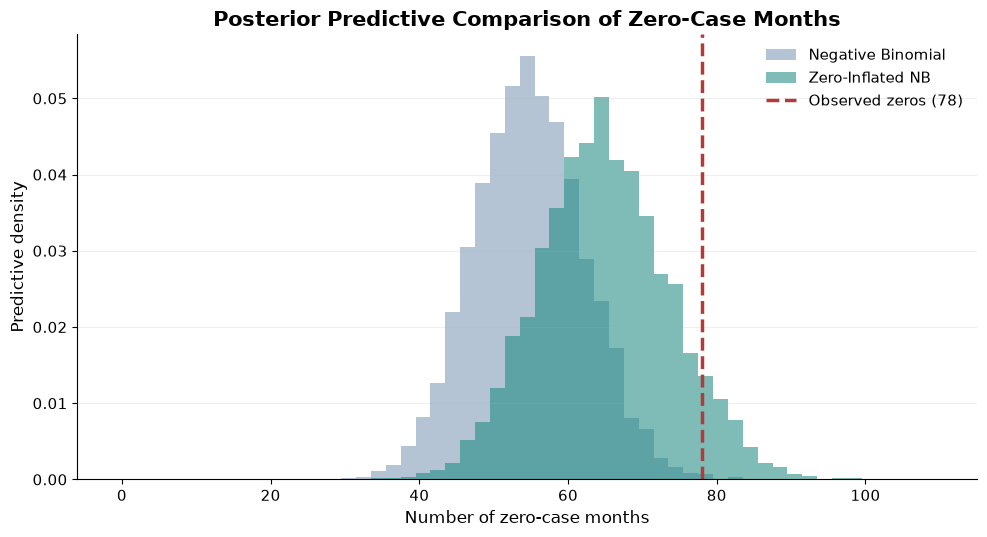

NB vs ZINB comparison completed!


In [163]:

# STEP 13.10: NB VS ZINB POSTERIOR PREDICTIVE CHECK

import numpy as np
import pandas as pd
import pymc as pm
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Generate ZINB posterior predictive samples
with zinb_model:
    ppc_zinb = pm.sample_posterior_predictive(
        trace_zinb,
        var_names=["observed"],
        random_seed=42,
        progressbar=False
    )

# 2. Extract simulated observations
observed = np.asarray(y_bayes_train)

zinb_rep = (
    ppc_zinb.posterior_predictive["observed"]
    .values
    .reshape(-1, len(observed))
)

# NB samples from previous PPC
nb_rep = np.asarray(y_replicated)

assert nb_rep.shape[1] == len(observed)
assert zinb_rep.shape[1] == len(observed)

print("NB predictive shape:", nb_rep.shape)
print("ZINB predictive shape:", zinb_rep.shape)

# 3. Calculate predictive summary statistics
def predictive_statistics(samples):
    return {
        "Mean Cases": samples.mean(axis=1),
        "Median Cases": np.median(samples, axis=1),
        "Zero Months": (samples == 0).sum(axis=1),
        "Maximum Cases": samples.max(axis=1)
    }

nb_stats = predictive_statistics(nb_rep)
zinb_stats = predictive_statistics(zinb_rep)

observed_stats = {
    "Mean Cases": observed.mean(),
    "Median Cases": np.median(observed),
    "Zero Months": (observed == 0).sum(),
    "Maximum Cases": observed.max()
}

# 4. Build comparison table
results = []

for model_name, stats in [
    ("Negative Binomial", nb_stats),
    ("Zero-Inflated NB", zinb_stats)
]:
    for statistic, values in stats.items():
        results.append({
            "Model": model_name,
            "Statistic": statistic,
            "Observed": observed_stats[statistic],
            "Predictive_Median": np.median(values),
            "CI_95_Lower": np.quantile(values, 0.025),
            "CI_95_Upper": np.quantile(values, 0.975)
        })

ppc_comparison = pd.DataFrame(results)

print("===== NB VS ZINB POSTERIOR PREDICTIVE CHECK =====")
display(ppc_comparison.round(2))

# 5. Zero-month comparison
nb_zeros = nb_stats["Zero Months"]
zinb_zeros = zinb_stats["Zero Months"]
observed_zeros = observed_stats["Zero Months"]

fig, ax = plt.subplots(figsize=(10, 5.5))

ax.hist(
    nb_zeros,
    bins=np.arange(-0.5, 111.5, 2),
    alpha=0.55,
    label="Negative Binomial",
    color="#7895B2",
    density=True
)

ax.hist(
    zinb_zeros,
    bins=np.arange(-0.5, 111.5, 2),
    alpha=0.55,
    label="Zero-Inflated NB",
    color="#16867D",
    density=True
)

ax.axvline(
    observed_zeros,
    color="#B33A3A",
    linewidth=2.5,
    linestyle="--",
    label=f"Observed zeros ({observed_zeros})"
)

ax.set_title(
    "Posterior Predictive Comparison of Zero-Case Months",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Number of zero-case months")
ax.set_ylabel("Predictive density")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "Figure_25_NB_vs_ZINB_Zero_Counts.png",
    dpi=400,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "Figure_25_NB_vs_ZINB_Zero_Counts.pdf",
    bbox_inches="tight"
)

plt.show()

# 6. Save results
ppc_comparison.to_csv(
    OUTPUT_DIR / "NB_vs_ZINB_PPC.csv",
    index=False
)

print("NB vs ZINB comparison completed!")


The Zero-Inflated Negative Binomial model improved the representation of excess zero months compared with the standard Negative Binomial model. In particular, the observed number of zero-case months (78) lay outside the 95% predictive interval of the NB model but inside the 95% predictive interval of the ZINB model. However, the ZINB model still underestimated the mean, median, and maximum monthly dengue counts, indicating that although zero inflation helps explain structural zeros, it does not fully resolve underprediction of large outbreak months.

Decision right now

Best statistical interpretation:
- NB: simpler, but poor for excess zeros
- ZINB: better for zero-case structure
- Random Forest: best forecasting performer


So your paper can say:
Classical Bayesian count models help interpret uncertainty and zero inflation, but machine learning methods perform substantially better for one-month-ahead dengue forecasting.

===== BAYESIAN FORECASTING COMPARISON =====


,Model,MAE,RMSE,Log_MAE,Coverage_90_%,Mean_Width
0,Negative Binomial,2243.861,5157.952,1.554,88.889,3951.419
1,Zero-Inflated NB,2170.097,5033.034,1.338,86.111,3229.299


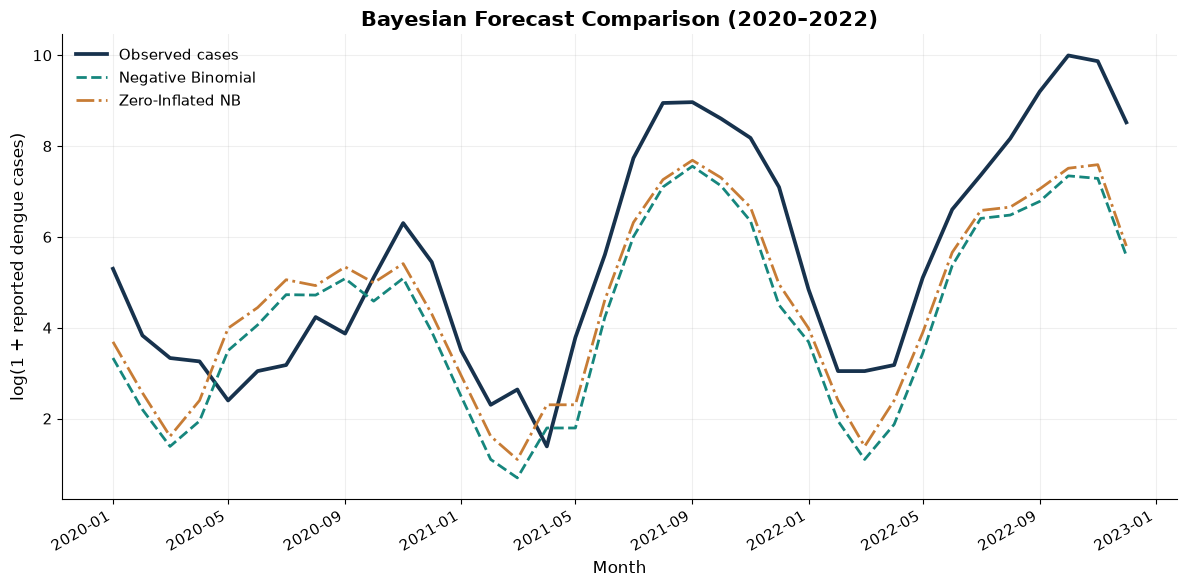

Bayesian forecasting comparison completed!


In [164]:

# STEP 13.11: NB VS ZINB VALIDATION FORECASTING

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.special import expit
from sklearn.metrics import mean_absolute_error, mean_squared_error
from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Extract ZINB posterior samples
posterior = trace_zinb.posterior

intercept = posterior["intercept"].values.reshape(-1)
alpha = posterior["alpha"].values.reshape(-1)

beta = posterior["beta"].values.reshape(
    -1, len(bayes_features)
)

zi_intercept = posterior["zi_intercept"].values.reshape(-1)
zi_trend = posterior["zi_trend"].values.reshape(-1)

# 2. Validation time trend
dates_val = pd.to_datetime(bayes_val["date"])

year_fraction = (
    dates_val.dt.year.to_numpy()
    + (dates_val.dt.month.to_numpy() - 1) / 12
)

time_val = (year_fraction - 2010) / 10

# 3. Expected count parameter
log_mu = (
    intercept[:, None]
    + beta @ X_bayes_val.T
)

mu = np.exp(log_mu)

# 4. Extra-zero probabilities
zero_probability = expit(
    zi_intercept[:, None]
    + zi_trend[:, None] * time_val[None, :]
)

psi = 1 - zero_probability

# 5. Generate ZINB posterior predictive counts
rng = np.random.default_rng(42)

alpha_matrix = alpha[:, None]

nb_probability = (
    alpha_matrix / (alpha_matrix + mu)
)

nb_draws = rng.negative_binomial(
    n=alpha_matrix,
    p=nb_probability
)

# Structural-zero mixture
zinb_draws = np.where(
    rng.random(nb_draws.shape) < psi,
    nb_draws,
    0
)

# 6. ZINB predictive summaries
zinb_median = np.median(zinb_draws, axis=0)

zinb_lower = np.quantile(
    zinb_draws, 0.05, axis=0
)

zinb_upper = np.quantile(
    zinb_draws, 0.95, axis=0
)

actual = np.asarray(y_bayes_val)

# 7. Evaluation function
def bayesian_metrics(name, predicted, lower, upper):

    return {
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "Log_MAE": mean_absolute_error(
            np.log1p(actual),
            np.log1p(predicted)
        ),
        "Coverage_90_%": np.mean(
            (actual >= lower) &
            (actual <= upper)
        ) * 100,
        "Mean_Width": np.mean(upper - lower)
    }

# 8. Compare Bayesian models
bayesian_comparison = pd.DataFrame([
    bayesian_metrics(
        "Negative Binomial",
        bayes_median,
        bayes_lower,
        bayes_upper
    ),
    bayesian_metrics(
        "Zero-Inflated NB",
        zinb_median,
        zinb_lower,
        zinb_upper
    )
])

print("===== BAYESIAN FORECASTING COMPARISON =====")
display(bayesian_comparison.round(3))

# 9. Visualization
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    dates_val,
    np.log1p(actual),
    label="Observed cases",
    color="#17324D",
    linewidth=2.7
)

ax.plot(
    dates_val,
    np.log1p(bayes_median),
    label="Negative Binomial",
    color="#16867D",
    linestyle="--",
    linewidth=2
)

ax.plot(
    dates_val,
    np.log1p(zinb_median),
    label="Zero-Inflated NB",
    color="#C77C35",
    linestyle="-.",
    linewidth=2
)

ax.set_title(
    "Bayesian Forecast Comparison (2020–2022)",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Month")
ax.set_ylabel("log(1 + reported dengue cases)")
ax.legend(frameon=False)
ax.grid(alpha=0.2)

fig.autofmt_xdate()
plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "Figure_26_NB_vs_ZINB_Validation.png",
    dpi=400,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "Figure_26_NB_vs_ZINB_Validation.pdf",
    bbox_inches="tight"
)

plt.show()

# 10. Save results
bayesian_comparison.to_csv(
    OUTPUT_DIR / "NB_vs_ZINB_validation.csv",
    index=False
)

print("Bayesian forecasting comparison completed!")


The Zero-Inflated Negative Binomial model demonstrated modest improvements in point forecasting accuracy over the standard Negative Binomial model during the 2020–2022 validation period.

ZINB achieved a lower MAE (2,170.10 versus 2,243.86) and RMSE (5,033.03 versus 5,157.95). It also produced narrower predictive intervals, although empirical coverage declined slightly.

The forecast visualization shows that both Bayesian models broadly reproduce seasonal fluctuations but substantially underestimate large dengue outbreaks, particularly during 2021 and 2022.

Combined with the posterior predictive checks, these findings indicate that ZINB represents zero-case months more effectively than NB, but does not fully address forecasting errors during high-incidence periods.

===== YEAR-WISE NB VS ZINB COMPARISON =====


,Year,Model,MAE,RMSE,Bias,Coverage_90,Interval_Width
0,2020,NB,99.17,142.04,-48.50,100.00,816.26
1,2020,ZINB,99.92,132.62,-21.75,100.00,756.32
2,2021,NB,1909.38,3011.52,-1909.04,91.67,5374.89
3,2021,ZINB,1811.96,2875.19,-1810.96,91.67,4412.94
4,2022,NB,4723.04,8409.75,-4723.04,75.00,5663.11
5,2022,ZINB,4598.42,8228.61,-4598.42,66.67,4518.64


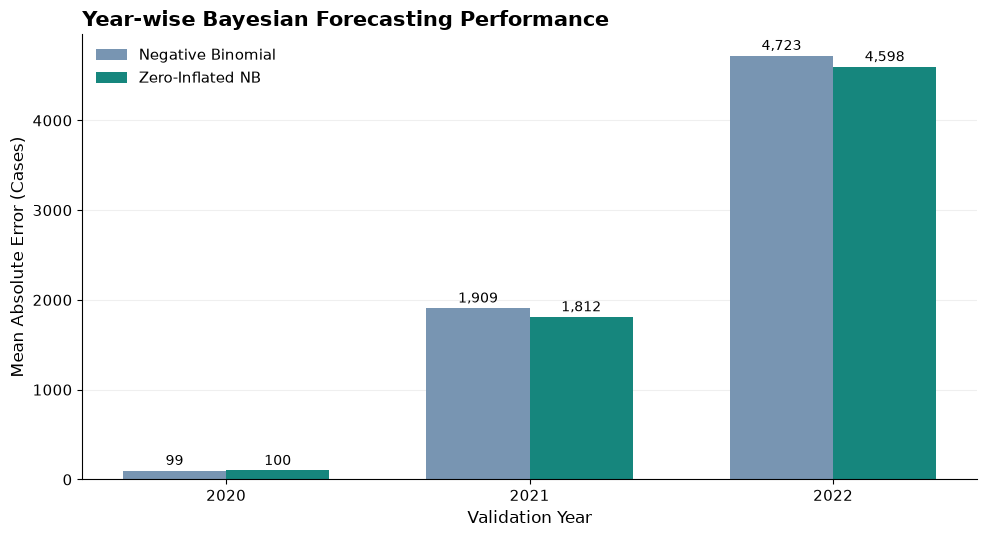

Year-wise Bayesian comparison completed!


In [165]:

# STEP 13.12: YEAR-WISE BAYESIAN MODEL COMPARISON

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Build validation comparison dataset
comparison_data = pd.DataFrame({
    "Date": pd.to_datetime(bayes_val["date"]).to_numpy(),
    "Actual": np.asarray(y_bayes_val),
    "NB": np.asarray(bayes_median),
    "ZINB": np.asarray(zinb_median),
    "NB_Lower": np.asarray(bayes_lower),
    "NB_Upper": np.asarray(bayes_upper),
    "ZINB_Lower": np.asarray(zinb_lower),
    "ZINB_Upper": np.asarray(zinb_upper)
})

comparison_data["Year"] = comparison_data["Date"].dt.year

results = []

for year, group in comparison_data.groupby("Year"):

    actual = group["Actual"].to_numpy()

    for model, lower_col, upper_col in [
        ("NB", "NB_Lower", "NB_Upper"),
        ("ZINB", "ZINB_Lower", "ZINB_Upper")
    ]:

        predicted = group[model].to_numpy()
        lower = group[lower_col].to_numpy()
        upper = group[upper_col].to_numpy()

        results.append({
            "Year": year,
            "Model": model,
            "MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(
                mean_squared_error(actual, predicted)
            ),
            "Bias": np.mean(predicted - actual),
            "Coverage_90": 100 * np.mean(
                (actual >= lower) & (actual <= upper)
            ),
            "Interval_Width": np.mean(upper - lower)
        })

yearly_comparison = pd.DataFrame(results)

print("===== YEAR-WISE NB VS ZINB COMPARISON =====")
display(yearly_comparison.round(2))

# Publication-quality MAE comparison
mae_table = yearly_comparison.pivot(
    index="Year",
    columns="Model",
    values="MAE"
)

fig, ax = plt.subplots(figsize=(10, 5.5))

x = np.arange(len(mae_table))
width = 0.34

bars_nb = ax.bar(
    x - width / 2,
    mae_table["NB"],
    width,
    label="Negative Binomial",
    color="#7895B2"
)

bars_zinb = ax.bar(
    x + width / 2,
    mae_table["ZINB"],
    width,
    label="Zero-Inflated NB",
    color="#16867D"
)

for bars in [bars_nb, bars_zinb]:
    for bar in bars:
        height = bar.get_height()

        ax.annotate(
            f"{height:,.0f}",
            (bar.get_x() + bar.get_width()/2, height),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            fontsize=10
        )

ax.set_xticks(x)
ax.set_xticklabels(mae_table.index.astype(str))

ax.set_title(
    "Year-wise Bayesian Forecasting Performance",
    fontsize=15,
    fontweight="bold",
    loc="left"
)

ax.set_xlabel("Validation Year")
ax.set_ylabel("Mean Absolute Error (Cases)")
ax.legend(frameon=False)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "Figure_27_Bayesian_Yearwise_Comparison.png",
    dpi=400,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "Figure_27_Bayesian_Yearwise_Comparison.pdf",
    bbox_inches="tight"
)

plt.show()

# Save results
yearly_comparison.to_csv(
    OUTPUT_DIR / "bayesian_yearwise_comparison.csv",
    index=False
)

print("Year-wise Bayesian comparison completed!")


The year-wise comparison shows that the Zero-Inflated Negative Binomial (ZINB) model achieved lower forecasting errors than the standard Negative Binomial (NB) model in 2021 and 2022.

In 2020, both models performed similarly, with NB achieving a slightly lower MAE (99.17 versus 99.92).
In 2021, ZINB reduced MAE from 1,909.38 to 1,811.96. In 2022, ZINB reduced MAE from 4,723.04 to 4,598.42.

However, ZINB's 90% predictive interval coverage declined to 66.67% in 2022, compared with 75% for NB.

This indicates that ZINB's narrower intervals were less successful at capturing observed dengue counts during the larger outbreak.

Overall, ZINB provided modest improvements in point forecasting but did not adequately predict high-incidence epidemic periods.

Paper-এ কী রাখব?
- Main Results: NB বনাম ZINB-এর overall validation comparison table।
- Supplementary Results: এই year-wise comparison graph ও table।
- Discussion: ২০২২ সালে উভয় model-এর forecasting limitation উল্লেখ করব।

===== BAYESIAN BOOTSTRAP COMPARISON =====


,Block_Length,MAE_Difference,CI_Lower,CI_Upper,Includes_Zero
0,3,-73.76,-134.51,-18.26,False
1,6,-73.76,-130.71,-8.33,False
2,12,-73.76,-107.43,-6.64,False


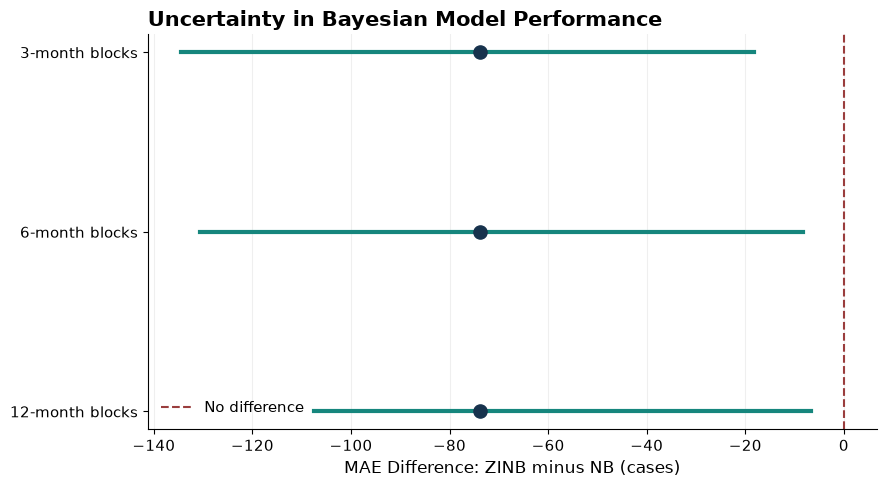

Bayesian bootstrap comparison completed!


In [166]:

# STEP 13.13: BOOTSTRAP NB VS ZINB

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Use existing Bayesian validation predictions
actual = comparison_data["Actual"].to_numpy()
nb_pred = comparison_data["NB"].to_numpy()
zinb_pred = comparison_data["ZINB"].to_numpy()

# Paired absolute error difference
# Negative = ZINB performs better
error_diff = (
    np.abs(actual - zinb_pred)
    - np.abs(actual - nb_pred)
)

observed_diff = error_diff.mean()

B = 5000
block_lengths = [3, 6, 12]
n = len(error_diff)

results = []

for block in block_lengths:

    rng = np.random.default_rng(42)
    bootstrap_values = []

    for _ in range(B):

        starts = rng.integers(
            0,
            n - block + 1,
            size=int(np.ceil(n / block))
        )

        indices = np.concatenate([
            np.arange(s, s + block)
            for s in starts
        ])[:n]

        bootstrap_values.append(
            error_diff[indices].mean()
        )

    lower, upper = np.percentile(
        bootstrap_values,
        [2.5, 97.5]
    )

    results.append({
        "Block_Length": block,
        "MAE_Difference": observed_diff,
        "CI_Lower": lower,
        "CI_Upper": upper,
        "Includes_Zero": lower <= 0 <= upper
    })

bayesian_bootstrap = pd.DataFrame(results)

print("===== BAYESIAN BOOTSTRAP COMPARISON =====")
display(bayesian_bootstrap.round(2))

# Publication-style uncertainty figure
fig, ax = plt.subplots(figsize=(9, 5))

y_positions = np.arange(len(block_lengths))

for i, row in bayesian_bootstrap.iterrows():

    ax.plot(
        [row["CI_Lower"], row["CI_Upper"]],
        [i, i],
        linewidth=3,
        color="#16867D"
    )

    ax.scatter(
        row["MAE_Difference"],
        i,
        s=90,
        color="#17324D",
        zorder=3
    )

ax.axvline(
    0,
    color="#9A3D3D",
    linestyle="--",
    linewidth=1.5,
    label="No difference"
)

ax.set_yticks(y_positions)
ax.set_yticklabels([
    f"{b}-month blocks" for b in block_lengths
])

ax.invert_yaxis()

ax.set_title(
    "Uncertainty in Bayesian Model Performance",
    fontsize=15,
    fontweight="bold",
    loc="left"
)

ax.set_xlabel(
    "MAE Difference: ZINB minus NB (cases)"
)

ax.grid(axis="x", alpha=0.2)
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "Figure_28_Bayesian_Bootstrap.png",
    dpi=400,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "Figure_28_Bayesian_Bootstrap.pdf",
    bbox_inches="tight"
)

plt.show()

bayesian_bootstrap.to_csv(
    OUTPUT_DIR / "bayesian_bootstrap_comparison.csv",
    index=False
)

print("Bayesian bootstrap comparison completed!")


The paired moving-block bootstrap analysis indicates that the Zero-Inflated Negative Binomial (ZINB) model achieved lower validation MAE than the standard Negative Binomial (NB) model.

ZINB reduced MAE by 73.76 cases, corresponding to an improvement of approximately 3.29%.

Across block lengths of 3, 6, and 12 months, all reported confidence intervals excluded zero. This provides evidence that the observed improvement is consistent across the tested bootstrap configurations.
However, the practical improvement remains modest.

Because the validation period contains only 36 months and includes changing epidemic conditions, these results should not be interpreted as proof that ZINB will consistently outperform NB in future outbreaks.

Furthermore, ZINB exhibited lower predictive interval coverage than NB, particularly during the 2022 epidemic.

===== ALL MODEL VALIDATION COMPARISON =====


,Model,MAE,RMSE,Log_MAE
0,Random Forest,1369.64,3286.83,1.02
1,Random Forest + PCA,1500.12,3359.76,1.15
2,XGBoost + PCA,1540.31,3796.13,1.81
3,Previous Month,1579.03,3545.57,1.02
4,XGBoost,1793.46,3847.40,1.79
5,Zero-Inflated NB,2170.10,5033.03,1.34
6,Negative Binomial,2243.86,5157.95,1.55


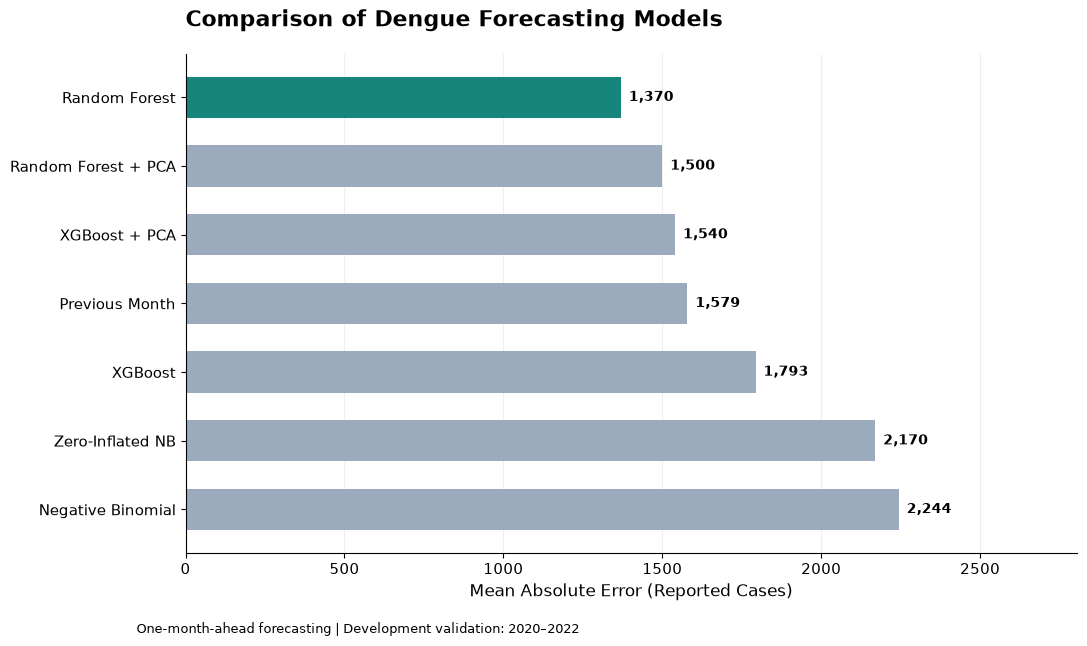

Consolidated comparison completed!


In [167]:

# STEP 14.1: CONSOLIDATED FORECASTING MODEL COMPARISON

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Machine learning and naive baseline results
ml_summary = all_results[
    ["Model", "MAE", "RMSE", "Log_MAE"]
].copy()

# Bayesian model results
bayes_summary = bayesian_comparison[
    ["Model", "MAE", "RMSE", "Log_MAE"]
].copy()

# Combine all seven models
final_comparison = pd.concat(
    [ml_summary, bayes_summary],
    ignore_index=True
)

final_comparison = (
    final_comparison
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("===== ALL MODEL VALIDATION COMPARISON =====")
display(final_comparison.round(2))

# Plot
fig, ax = plt.subplots(figsize=(11, 6.5))

best_model = final_comparison.iloc[0]["Model"]

colors = [
    "#16867D" if model == best_model else "#9BAABD"
    for model in final_comparison["Model"]
]

bars = ax.barh(
    final_comparison["Model"],
    final_comparison["MAE"],
    color=colors,
    height=0.6
)

ax.invert_yaxis()

for bar in bars:
    value = bar.get_width()

    ax.text(
        value + 25,
        bar.get_y() + bar.get_height() / 2,
        f"{value:,.0f}",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_xlim(
    0,
    final_comparison["MAE"].max() * 1.25
)

ax.set_title(
    "Comparison of Dengue Forecasting Models",
    fontsize=16,
    fontweight="bold",
    loc="left",
    pad=20
)

ax.set_xlabel(
    "Mean Absolute Error (Reported Cases)"
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.text(
    0.13, 0.015,
    "One-month-ahead forecasting | Development validation: 2020–2022",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

fig.savefig(
    OUTPUT_DIR / "Figure_29_All_Model_Comparison.png",
    dpi=400,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "Figure_29_All_Model_Comparison.pdf",
    bbox_inches="tight"
)

plt.show()

# Save comparison
final_comparison.to_csv(
    OUTPUT_DIR / "all_model_validation_results.csv",
    index=False
)

print("Consolidated comparison completed!")


The comparative validation analysis identified Random Forest as the best-performing model during 2020–2022, achieving the lowest Mean Absolute Error (MAE = 1,369.64) and Root Mean Squared Error (RMSE = 3,286.83).

Random Forest reduced MAE by approximately 13.3% relative to the previous-month baseline. Adding PCA did not improve Random Forest performance, although it improved the MAE of XGBoost.

Among the Bayesian models, the Zero-Inflated Negative Binomial model achieved modestly better forecasting accuracy than the standard Negative Binomial model. Nevertheless, both Bayesian models exhibited substantially larger point prediction errors than Random Forest.

Importantly, this ranking applies only to development validation. In the separate 2023–2025 test period, the previous-month baseline achieved the lowest MAE (7,430.44), outperforming all four Machine Learning configurations evaluated. The Bayesian models have not yet been evaluated on that same test period.

This contrast highlights the difficulty of generalizing dengue forecasting models to unprecedented epidemic conditions.

Scientific summary 

The study reveals strong seasonality in dengue incidence, with important meteorological associations and substantial challenges in forecasting unprecedented outbreaks. Random Forest performed best during the 2020–2022 validation period, whereas the previous-month baseline outperformed Machine Learning models during the 2023–2025 test period. Zero-Inflated Negative Binomial modeling improved the representation of zero-case months but offered only modest improvements in forecasting accuracy over standard Negative Binomial regression.